# Exploratory Data Analysis

This notebook explores the ACDC dataset before preprocessing. It previews the data, checks its structure and quality, and summarizes numerical, categorical, and Boolean variables.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import sqlite3
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import ceil
from itertools import product
PALETTE = sns.color_palette("viridis", 8)
sns.set_palette(PALETTE)
# for better resolution plots
%config InlineBackend.figure_format = 'retina'

## Load and preview the data

Load the semicolon-separated CSV file and display the first 10 records across all columns to get an initial view of the data.

In [2]:
acdc = pd.read_csv('data/acdc_dataset.csv', sep = ';')
pd.set_option("display.max_columns", None)
acdc.head(10)
# categorical columns have multiple names for the same category, 
# numerical columns are not in the correct range (some are negative where they should not be) 
# uses_print is 0/1 and not T/F)
# date columns are also not in the correct range with end values being 1970 or the end date being smaller than the start date

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,last_badge_swipe,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
0,CW000001,38.0,Female,Information Technology,Portugal,False,0,flex,3,2021-08-01,2023-03-06,2023-03-23,-17,220,2.65,26.09,22,0.0,0.0,18.0,False,False,True,0,False,True,True,False,False,2,4477.97
1,CW000002,38.0,Male,Information Technology,Portugal,True,2,HOT_DESK,2,2023-11-24,1970-01-01,2023-11-24,37,2,0.32,10.68,1,0.0,0.0,0.0,False,False,False,0,True,False,False,False,False,0,165.86
2,CW000003,43.0,Male,Education,DE,True,1,flex,3,2021-12-03,1970-01-01,2023-07-22,163,19,0.17,26.09,2,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,1,4486.17
3,CW000004,38.0,F,Legal,portugal,False,0,flex,3,2022-01-02,2022-02-15,2022-01-02,44,8,1.23,18.74,9,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,0,258.63
4,CW000005,45.0,Female,Information Technology,United Kingdom,False,0,hot_desk,2,2023-10-24,1970-01-01,2023-12-17,15,4,0.38,17.39,3,0.0,0.0,0.0,False,False,False,0,False,False,True,False,False,0,335.74
5,CW000006,39.0,Male,Health,Portugal,False,0,flex,3,2021-05-31,2021-08-01,2021-07-09,23,3,0.36,26.09,3,0.0,0.0,0.0,False,False,False,1,True,False,False,False,False,0,413.17
6,CW000007,23.0,Female,Unknown,Portugal,True,2,hot_desk,2,2022-01-17,2022-03-19,2022-01-31,47,5,0.62,17.39,5,0.0,0.0,1.0,False,False,True,0,False,False,False,False,False,0,257.95
7,CW000008,33.0,Male,Information Technology,Portugal,True,3,flex,3,2021-03-28,2022-06-30,2022-06-14,16,155,2.36,26.09,25,129.0,0.0,0.0,True,False,False,0,False,False,False,True,False,0,4636.8
8,CW000009,30.0,Male,Other,Portugal,False,0,flex,3,2023-08-12,2023-09-21,2023-08-12,40,6,1.10,17.13,6,0.0,1.0,0.0,False,True,False,0,False,False,False,False,False,0,281.37
9,CW000010,44.0,Male,Consulting,Portugal,False,0,dedicated_desk,5,2022-06-06,1970-01-01,2023-12-30,2,331,4.04,43.48,36,42.1,0.0,37.0,True,False,True,1,True,True,False,True,False,1,8741.88


## Dataset structure

Check the number of rows and columns, review the column names, and inspect inferred data types. This helps distinguish numeric, categorical, date-like, and Boolean fields.

In [3]:
acdc.shape

(15465, 31)

In [4]:
list(acdc.columns)

['member_id',
 'age',
 'gender',
 'industry',
 'country',
 'is_team_account',
 'n_colleagues_on_account',
 'plan_tier',
 'plan_days_per_week',
 'membership_start',
 'membership_end',
 'last_badge_swipe',
 'days_since_last_visit',
 'total_visits',
 'avg_weekly_visits',
 'entitled_visits_last_period',
 'actual_visits_last_period',
 'meeting_room_hours',
 'event_space_hours',
 'guest_passes_issued',
 'uses_meeting_rooms',
 'uses_event_space',
 'uses_guest_passes',
 'uses_print',
 'uses_mail_handling',
 'uses_phone_booths',
 'uses_day_passes',
 'uses_storage',
 'uses_bike_locker',
 'n_renewals',
 'lifetime_value']

In [5]:
acdc.dtypes

member_id                          str
age                            float64
gender                             str
industry                           str
country                            str
is_team_account                   bool
n_colleagues_on_account          int64
plan_tier                          str
plan_days_per_week               int64
membership_start                   str
membership_end                     str
last_badge_swipe                   str
days_since_last_visit            int64
total_visits                     int64
avg_weekly_visits              float64
entitled_visits_last_period    float64
actual_visits_last_period        int64
meeting_room_hours             float64
event_space_hours              float64
guest_passes_issued            float64
uses_meeting_rooms                bool
uses_event_space                  bool
uses_guest_passes                 bool
uses_print                       int64
uses_mail_handling                bool
uses_phone_booths        

## Missing values

Calculate the percentage of missing values in each column and show only columns that contain missing data.

In [6]:
column_percentage = acdc.isna().mean() * 100
column_percentage = column_percentage[column_percentage > 0]
column_percentage

age                    3.608147
gender                 3.427093
country                2.780472
plan_tier              0.678952
meeting_room_hours     8.393146
guest_passes_issued    8.218558
lifetime_value         6.724863
dtype: float64

## Duplicate records

Count exact duplicate rows and repeated member IDs, then inspect records with duplicated IDs to see whether they are identical or differ in their other fields.

In [7]:
print("Duplicated rows:", acdc.duplicated().sum())
print("Duplicated member IDs:", acdc["member_id"].duplicated().sum())

Duplicated rows: 15
Duplicated member IDs: 15


In [8]:
dup_ids = acdc.loc[acdc["member_id"].duplicated(keep=False)].sort_values("member_id")
dup_ids.head(30)

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,last_badge_swipe,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
959,CW000935,22.0,Female,Unknown,Portugal,False,0,FLEX,3,2022-12-18,2023-03-07,2023-01-21,45,18,1.56,26.09,11,1.7,0.0,1.0,True,False,True,0,False,False,False,False,False,0,505.28
15453,CW000935,22.0,Female,Unknown,Portugal,False,0,FLEX,3,2022-12-18,2023-03-07,2023-01-21,45,18,1.56,26.09,11,1.7,0.0,1.0,True,False,True,0,False,False,False,False,False,0,505.28
1428,CW001390,44.0,Male,UNKNOWN,Portugal,False,0,hot_desk,2,28/10/2022,18/12/2022,17/11/2022,31,4,0.61,14.63,5,NaN,0.0,NaN,False,False,True,0,False,False,False,False,False,0,231.86
15454,CW001390,44.0,Male,UNKNOWN,Portugal,False,0,hot_desk,2,28/10/2022,18/12/2022,17/11/2022,31,4,0.61,14.63,5,NaN,0.0,NaN,False,False,True,0,False,False,False,False,False,0,231.86
3985,CW003868,28.0,Female,Design & Creative,Portugal,True,1,hot_desk,2,2023-12-27,1970-01-01,2023-12-27,5,1,0.21,1.31,0,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,0,18.14
15462,CW003868,28.0,Female,Design & Creative,Portugal,True,1,hot_desk,2,2023-12-27,1970-01-01,2023-12-27,5,1,0.21,1.31,0,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,0,18.14
5441,CW005287,19.0,Female,Information Technology,Germany,False,0,private_office,7,2021-04-29,2023-10-15,2023-09-26,19,74,0.58,60.87,4,0.0,0.0,0.0,False,False,False,0,True,True,False,True,False,0,20683.24
15461,CW005287,19.0,Female,Information Technology,Germany,False,0,private_office,7,2021-04-29,2023-10-15,2023-09-26,19,74,0.58,60.87,4,0.0,0.0,0.0,False,False,False,0,True,True,False,True,False,0,20683.24
6011,CW005845,35.0,Female,FINANCE,Portugal,True,3,dedicated_desk,5,2021-10-05,1970-01-01,2023-01-26,340,24,0.20,43.48,2,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,4,9403.99
15456,CW005845,35.0,Female,FINANCE,Portugal,True,3,dedicated_desk,5,2021-10-05,1970-01-01,2023-01-26,340,24,0.20,43.48,2,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,4,9403.99


## Variable distributions

Check and convert the lifetime values so they can be included in numeric summaries. Then inspect numeric statistics, raw category frequencies, and Boolean summaries. The category counts retain the original spellings so inconsistent labels remain visible.

In [9]:
# Numeric summary (50% is the median)
numeric = acdc.select_dtypes(include="number").drop(columns="uses_print", errors="ignore")
numeric["lifetime_value"] = pd.to_numeric(
    acdc["lifetime_value"].astype("string").str.replace(r"[€,]", "", regex=True),
    errors="coerce",
)
display(numeric.describe(include=["float", "integer"]).T)

# Category counts, shown separately
display(acdc["gender"].value_counts(dropna=False))
display(acdc["industry"].value_counts(dropna=False))
display(acdc["country"].value_counts(dropna=False))
display(acdc["plan_tier"].value_counts(dropna=False))

,count,mean,std,min,25%,50%,75%,max
age,14907.0,34.858724,10.394649,1.0,29.0,34.0,40.0,149.0
n_colleagues_on_account,15465.0,0.537019,1.177668,-1.0,0.0,0.0,1.0,9.0
plan_days_per_week,15465.0,3.387262,1.458818,0.0,2.0,3.0,5.0,9.0
days_since_last_visit,15465.0,117.109279,275.532807,-956.0,4.0,13.0,55.0,1212.0
total_visits,15465.0,110.406531,182.93934,-112.0,8.0,34.0,132.0,6530.0
avg_weekly_visits,15465.0,1.777214,1.937515,0.0,0.71,1.42,2.41,47.4
entitled_visits_last_period,15465.0,27.517393,13.480235,0.0,17.39,26.09,43.48,78.27
actual_visits_last_period,15465.0,13.80097,11.387207,0.0,5.0,10.0,20.0,60.0
meeting_room_hours,14167.0,33.07557,428.169678,-56.6,0.0,0.0,7.2,41220.0
event_space_hours,15465.0,5.11722,26.013097,-13.5,0.0,0.0,0.0,602.8


gender
Female     7414
Male       6172
NaN         530
Other       465
female      169
F           143
 Female     141
M           138
male        132
 Male       129
other        15
 Other        9
O             8
Name: count, dtype: int64

industry
Information Technology    3322
Consulting                1896
Marketing & PR            1835
Design & Creative         1822
Finance                   1134
Other                     1100
Legal                      809
Education                  727
Unknown                    640
Health                     571
Real Estate                528
CONSULTING                  86
consulting                  76
INFORMATION TECHNOLOGY      54
IT                          53
information technology      49
FINANCE                     48
design & creative           44
Information technology      41
DESIGN & CREATIVE           40
Tech                        40
OTHER                       39
LEGAL                       38
finance                     38
other                       36
Design/Creative             35
Design and Creative         34
legal                       33
MARKETING & PR              32
UNKNOWN                     29
unknown                     27
marketing & pr              25

country
Portugal           9959
United Kingdom     1105
Germany             852
Spain               712
France              506
Netherlands         464
NaN                 430
Other (Europe)      429
Ireland             232
portugal            155
Portucal            142
PT                  130
portugal            122
germany              24
other (europe)       22
france               18
united kingdom       16
DE                   14
UK                   14
Deutschland          13
NL                   13
GB                   12
U.K.                 10
Espana               10
United kingdom        9
FR                    9
ES                    8
España                7
IE                    6
ireland               6
spain                 5
netherlands           4
The Netherlands       4
Holland               3
Name: count, dtype: int64

plan_tier
flex              5182
hot_desk          4974
full_time         2323
dedicated_desk    1481
private_office     630
Flex               138
FLEX               133
NaN                105
HOT_DESK            82
Hot Desk            80
hotdesk             79
fulltime            64
FULL_TIME           49
Full Time           39
DEDICATED_DESK      27
Dedicated Desk      25
dedicateddesk       19
Private Office      13
privateoffice       12
PRIVATE_OFFICE      10
Name: count, dtype: int64

In [10]:
# cat_cols = ["gender", "industry", "country", "plan_tier"]

# # Use a 2x2 grid instead of 4x1, with a manageable figure size
# fig, axes = plt.subplots(2, 2, figsize=(14, 10))
# axes = axes.flatten()

# for i, col in enumerate(cat_cols):
#     ax = axes[i]
    
#     # Fill NaNs with a string placeholder so Matplotlib doesn't crash on floats
#     plot_data = acdc[col].fillna("Missing")
    
#     # Get value counts of the cleaned series
#     counts = plot_data.value_counts()
    
#     # Plot as a bar chart using seaborn
#     sns.countplot(
#         data=acdc.assign(**{col: plot_data}), 
#         x=col, 
#         order=counts.index, 
#         ax=ax, 
#         palette="viridis", 
#         hue=col, 
#         legend=False
#     )
    
#     ax.set_title(f"Distribution of {col}", fontsize=12, fontweight="bold")
#     ax.set_xlabel(col, fontsize=10)
#     ax.set_ylabel("Count", fontsize=10)
#     ax.tick_params(axis='x', rotation=45)

# # Hide any unused subplots (just in case)
# for ax in axes[len(cat_cols):]:
#     ax.axis("off")

# plt.suptitle("Categorical Variable Distributions (Raw Labels)", fontsize=16, y=1.02)
# plt.tight_layout()
# plt.show()

In [11]:
# Boolean summary, including uses_print converted from 0/1 to True/False
booleans = acdc.select_dtypes(include="bool").assign(
    uses_print=acdc["uses_print"].astype(bool)
)
display(booleans.describe(include="bool"))

,is_team_account,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,uses_print
count,15465,15465,15465,15465,15465,15465,15465,15465,15465,15465
unique,2,2,2,2,2,2,2,2,2,2
top,False,False,False,False,False,False,False,False,False,False
freq,11112,10202,13624,12651,11901,11469,12069,13169,15439,10469


Values containing €: 291


70     246.10 €
83     446.70 €
211    859.65 €
220    843.67 €
240    646.66 €
Name: lifetime_value, dtype: str

                             missing       min  median     mean         max   skew  kurtosis  pct_zero  n_negative
age                              557      1.00   34.00    34.86      149.00   3.03     28.90      0.00           0
n_colleagues_on_account            0     -1.00    0.00     0.54        9.00   2.12      4.83     69.18         565
plan_days_per_week                 0      0.00    3.00     3.39        9.00   0.93      0.27      0.28           0
days_since_last_visit              0   -956.00   13.00   117.19     1212.00   2.72      5.98      0.55          56
total_visits                       0   -112.00   34.00   110.39     6530.00   6.82    159.76      0.71          42
avg_weekly_visits                  0      0.00    1.42     1.78       47.40  10.27    190.12      0.09           0
entitled_visits_last_period        0      0.00   26.09    27.51       78.27   0.73      0.00      0.06           0
actual_visits_last_period          0      0.00   10.00    13.80       60.00   1.

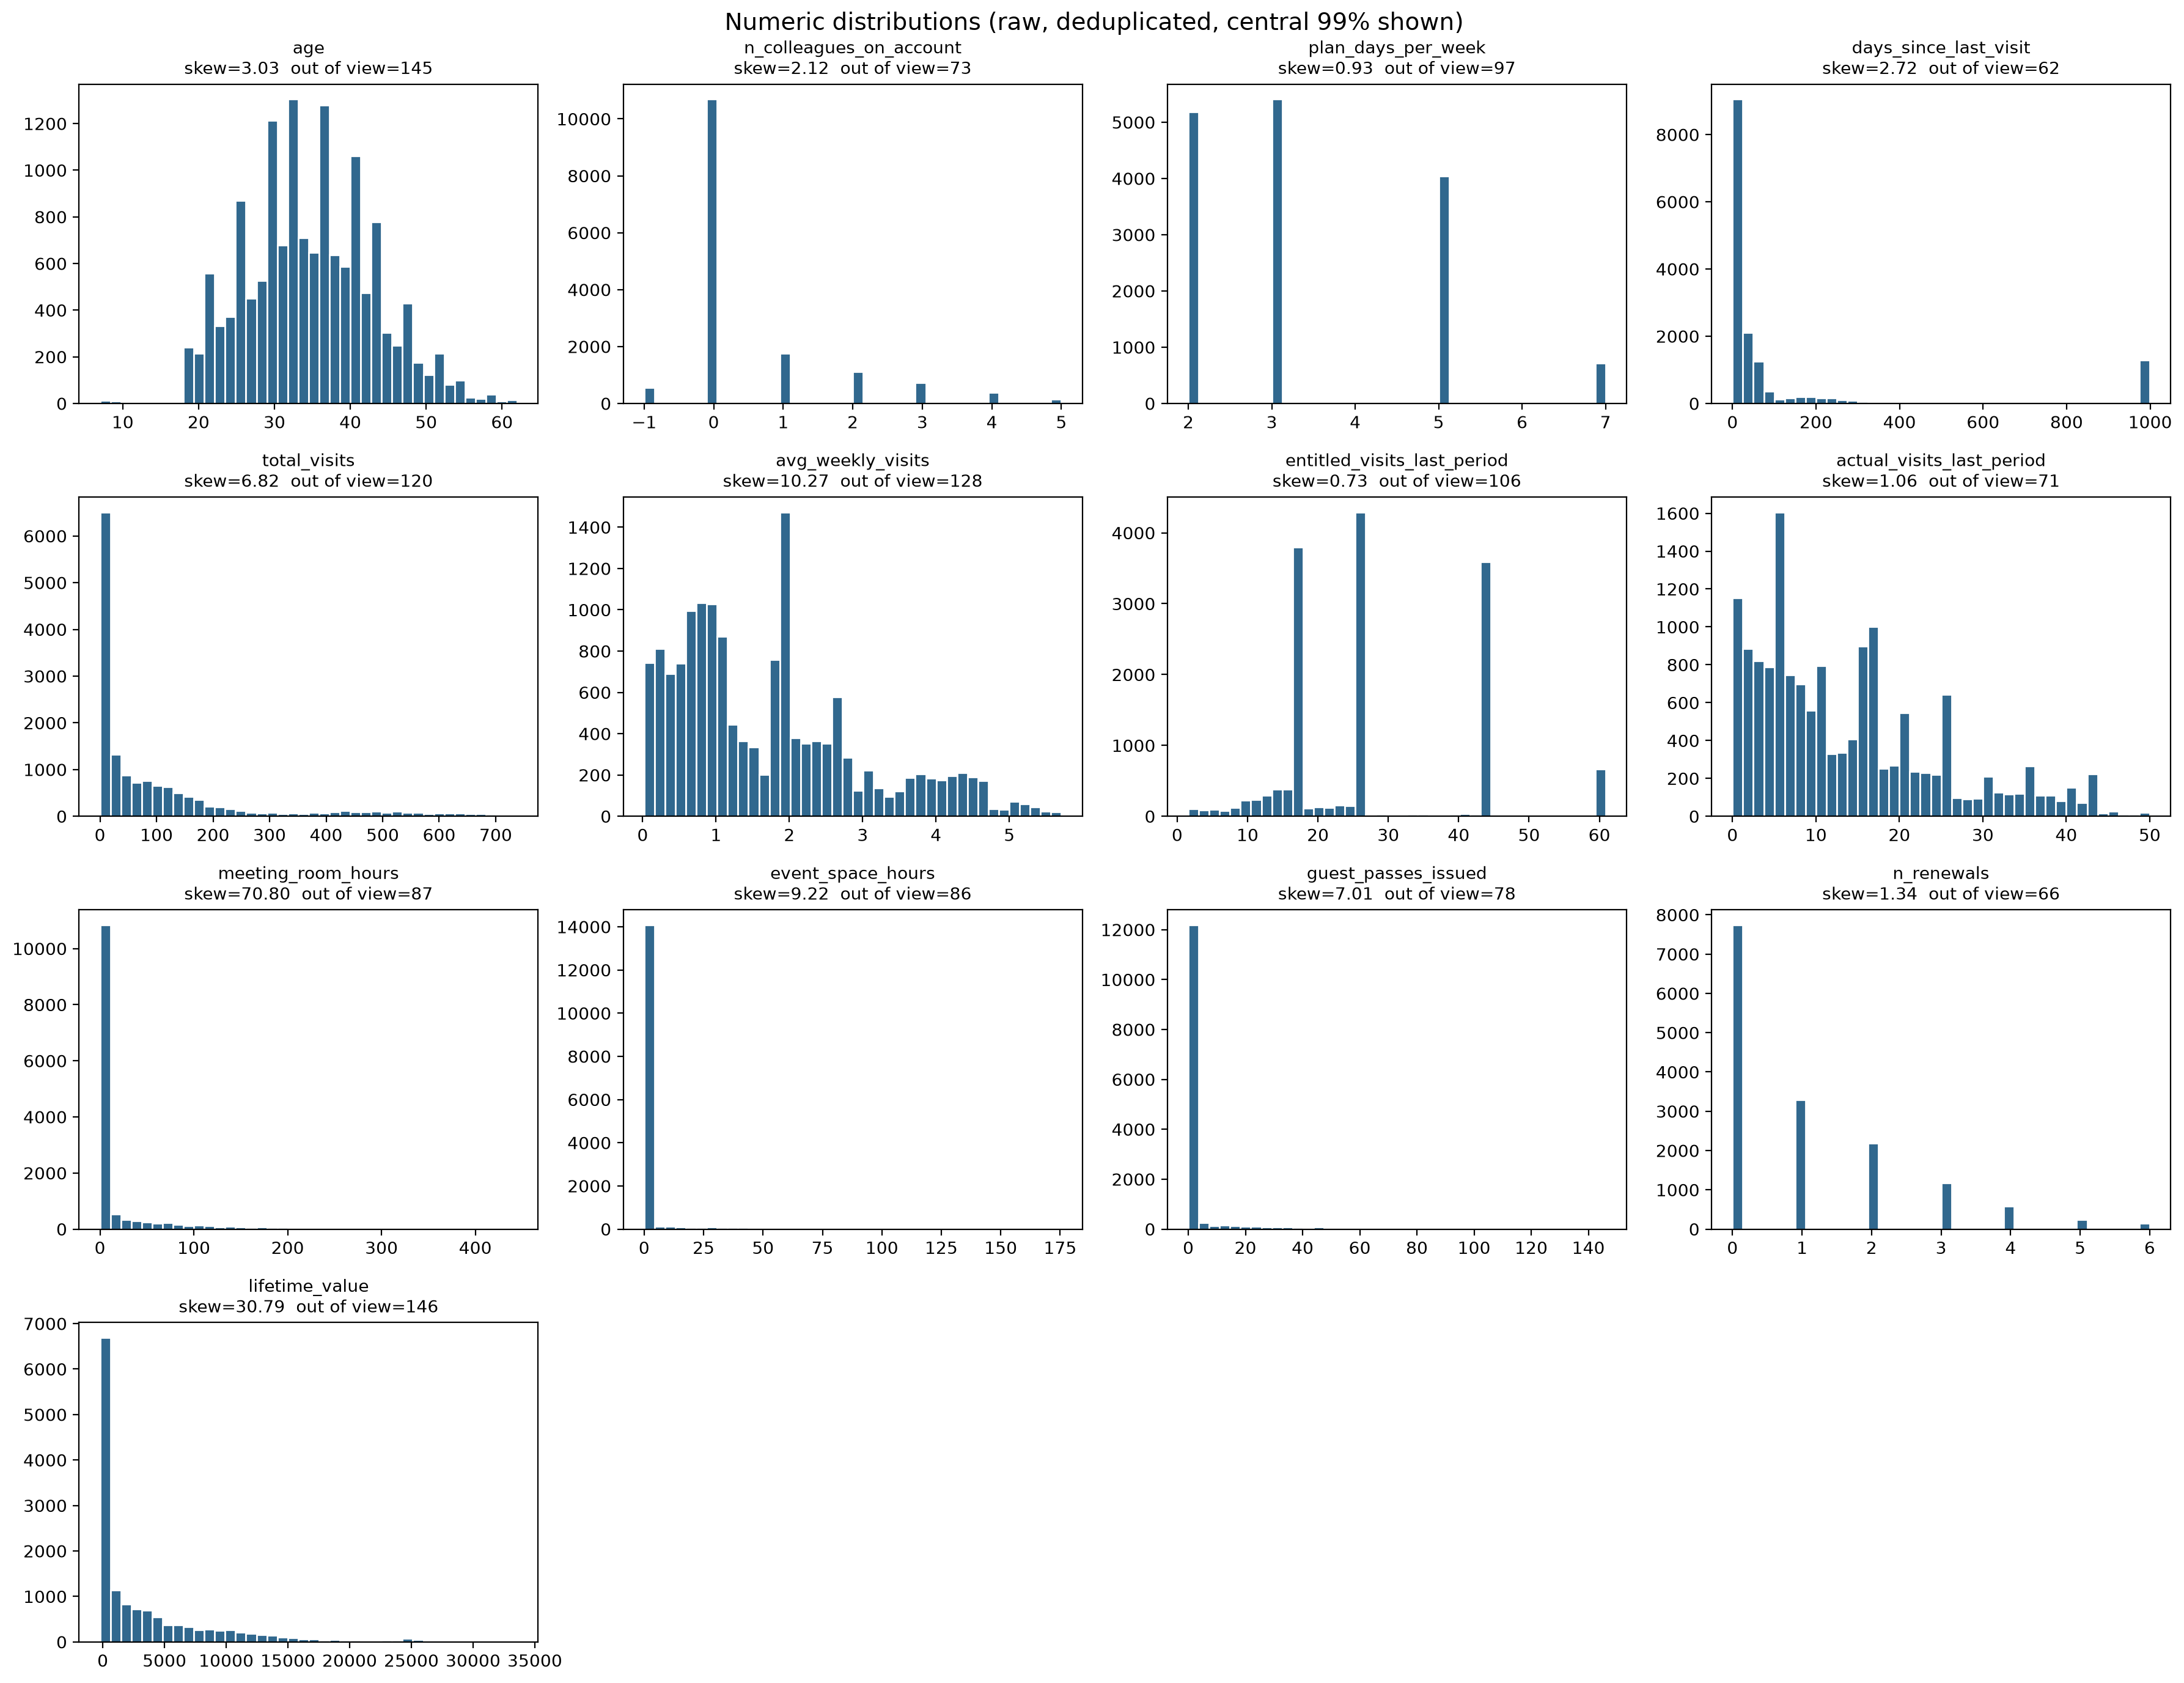

In [12]:
# Lifetime value is of type object, why? Because there are euro signs in some of the values. 
# Check how many values contain the euro sign and remove to look at distribution.
euro_values = acdc["lifetime_value"].astype("string").str.contains("€", na=False)
print(f"Values containing €: {euro_values.sum()}")
display(acdc.loc[euro_values, "lifetime_value"].head())

numeric_acdc = acdc.drop_duplicates()
numeric_acdc["lifetime_value"] = pd.to_numeric(numeric_acdc["lifetime_value"].astype(str).str.replace("€", "").str.replace(",", "").str.strip(), errors="coerce")

num_cols = ["age", "n_colleagues_on_account", "plan_days_per_week", "days_since_last_visit",
            "total_visits", "avg_weekly_visits", "entitled_visits_last_period",
            "actual_visits_last_period", "meeting_room_hours", "event_space_hours",
            "guest_passes_issued", "n_renewals", "lifetime_value"]

stats = pd.DataFrame({
    "missing": numeric_acdc[num_cols].isna().sum(),
    "min": numeric_acdc[num_cols].min(),
    "median": numeric_acdc[num_cols].median(),
    "mean": numeric_acdc[num_cols].mean(),
    "max": numeric_acdc[num_cols].max(),
    "skew": numeric_acdc[num_cols].skew(),
    "kurtosis": numeric_acdc[num_cols].kurt(),
    "pct_zero": (numeric_acdc[num_cols] == 0).mean() * 100,
    "n_negative": (numeric_acdc[num_cols] < 0).sum(),
}).round(2)
print(stats.to_string())

fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, col in zip(axes.flat, num_cols):
    s = numeric_acdc[col].dropna()
    lo, hi = s.quantile([0.005, 0.995])
    s_clip = s[(s >= lo) & (s <= hi)]
    ax.hist(s_clip, bins=40, color=PALETTE[2], edgecolor="white")
    ax.set_title(f"{col}\nskew={s.skew():.2f}  out of view={len(s) - len(s_clip)}", fontsize=10)
for ax in axes.flat[len(num_cols):]:
    ax.axis("off")
fig.suptitle("Numeric distributions (raw, deduplicated, central 99% shown)", fontsize=14)
fig.tight_layout()
#fig.savefig("numeric_distributions.png", dpi=110)

## Univariate Exploration
### Outlier Analysis

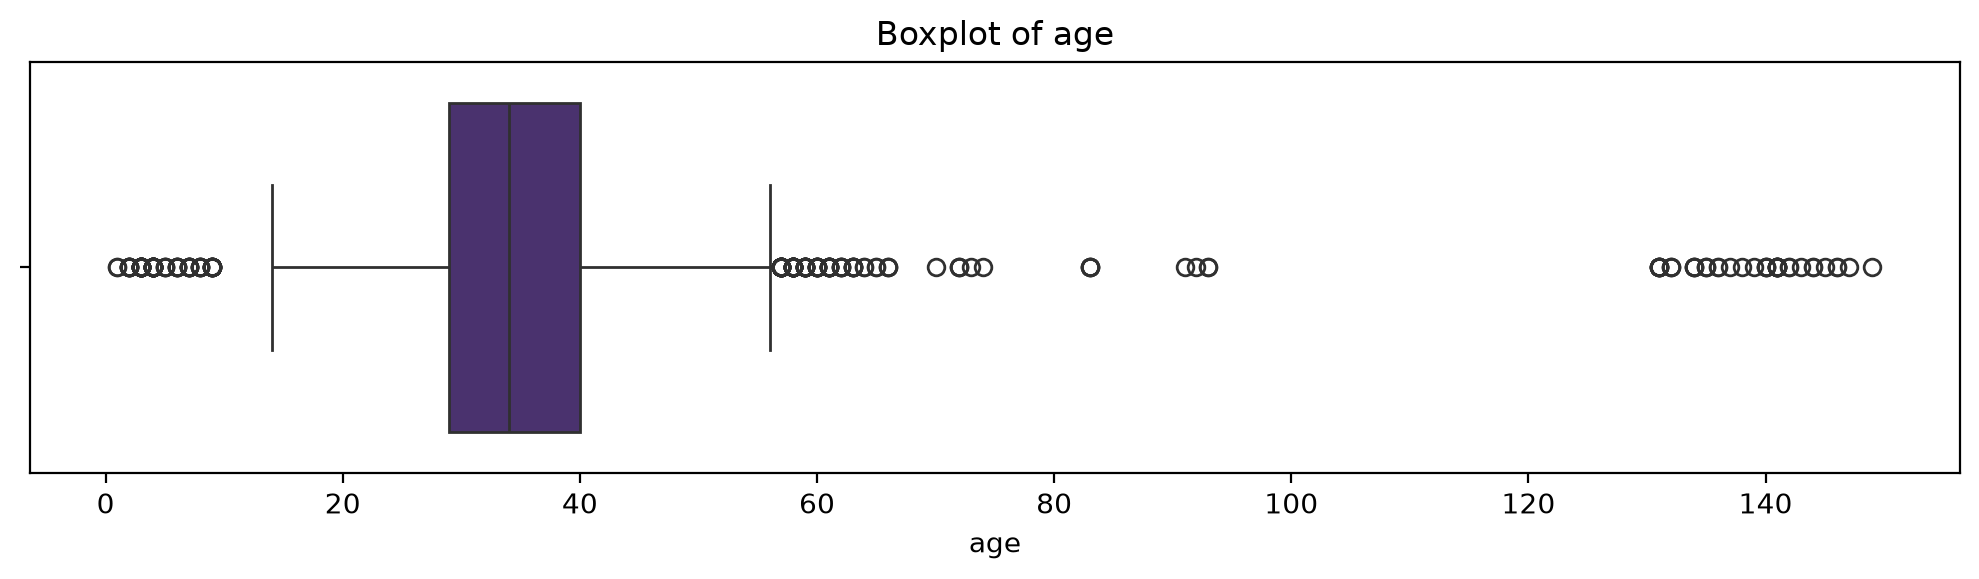

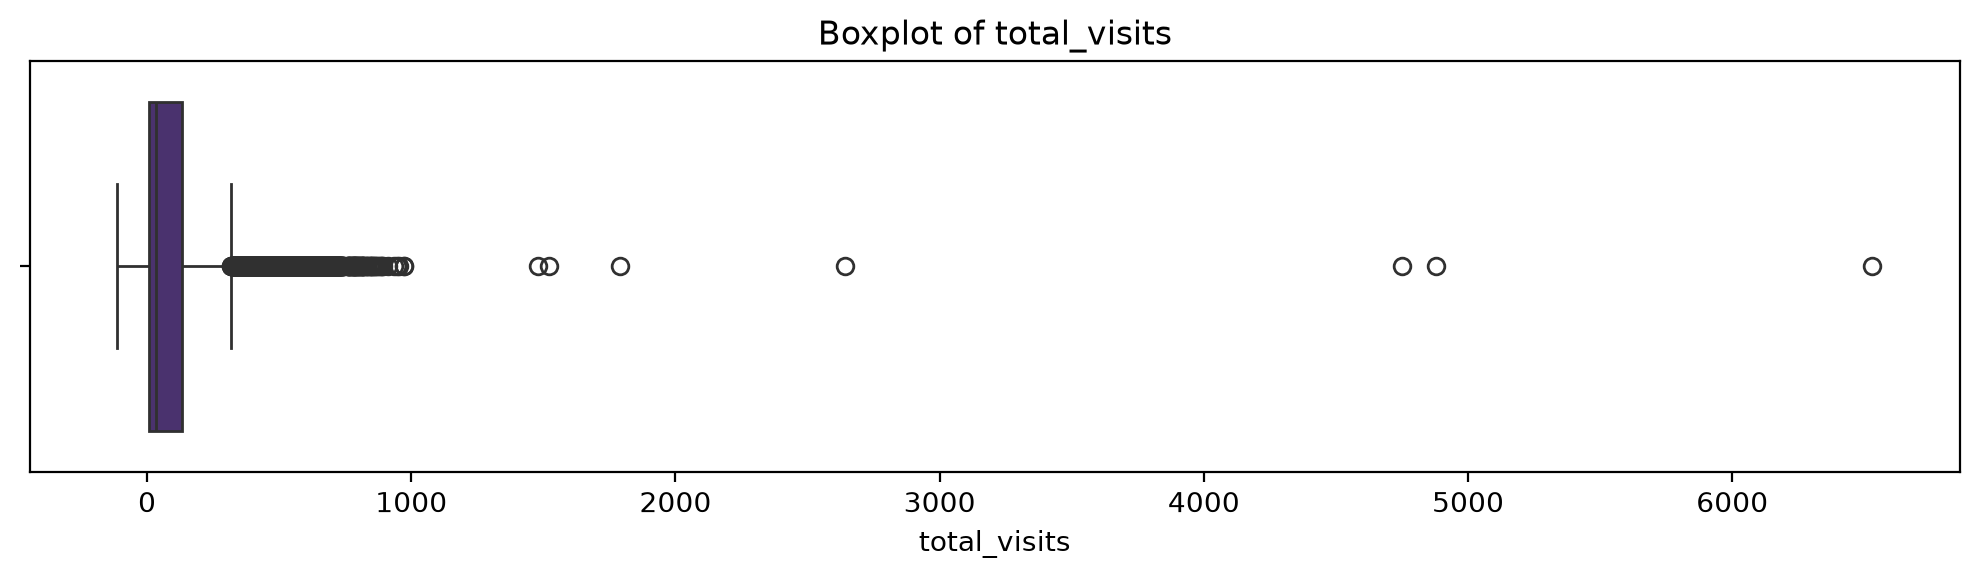

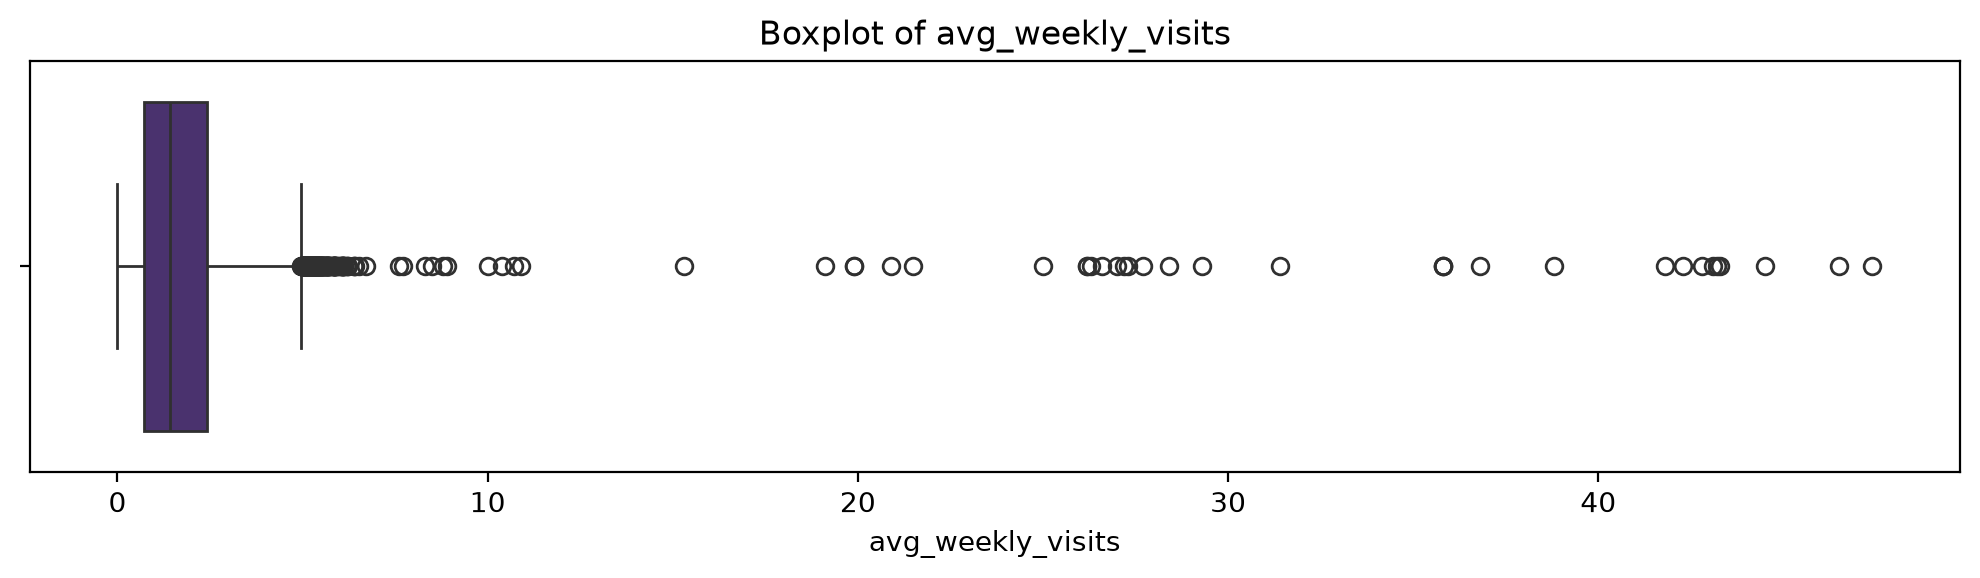

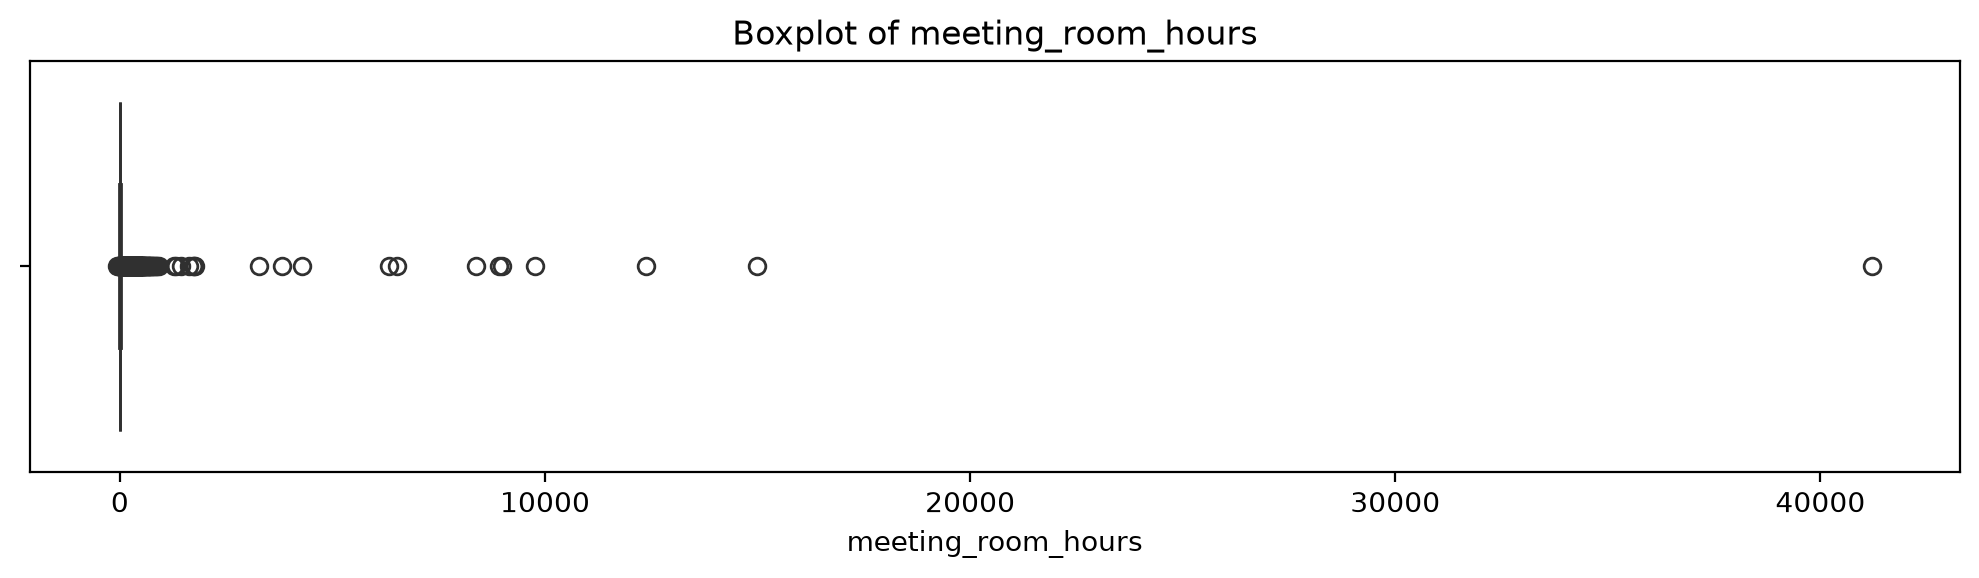

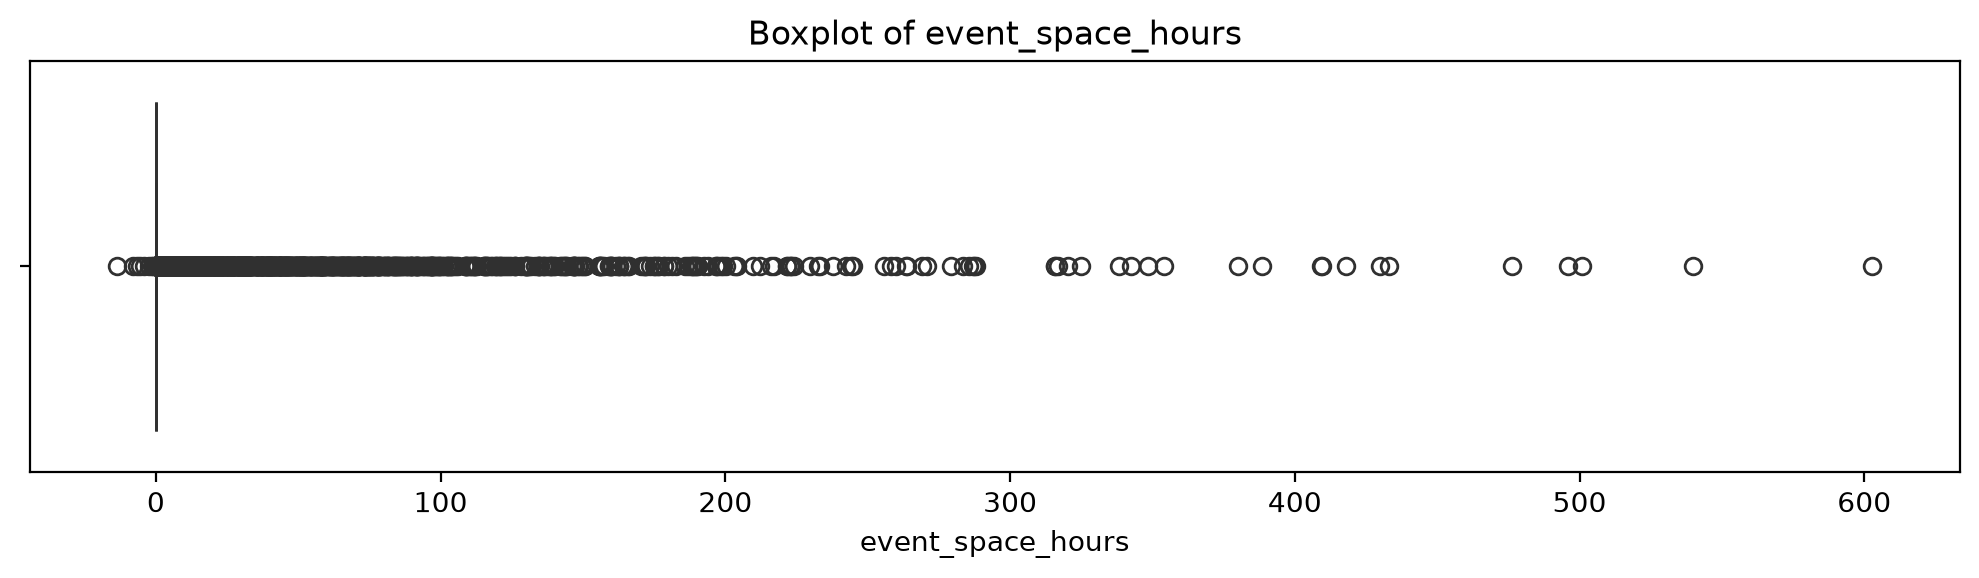

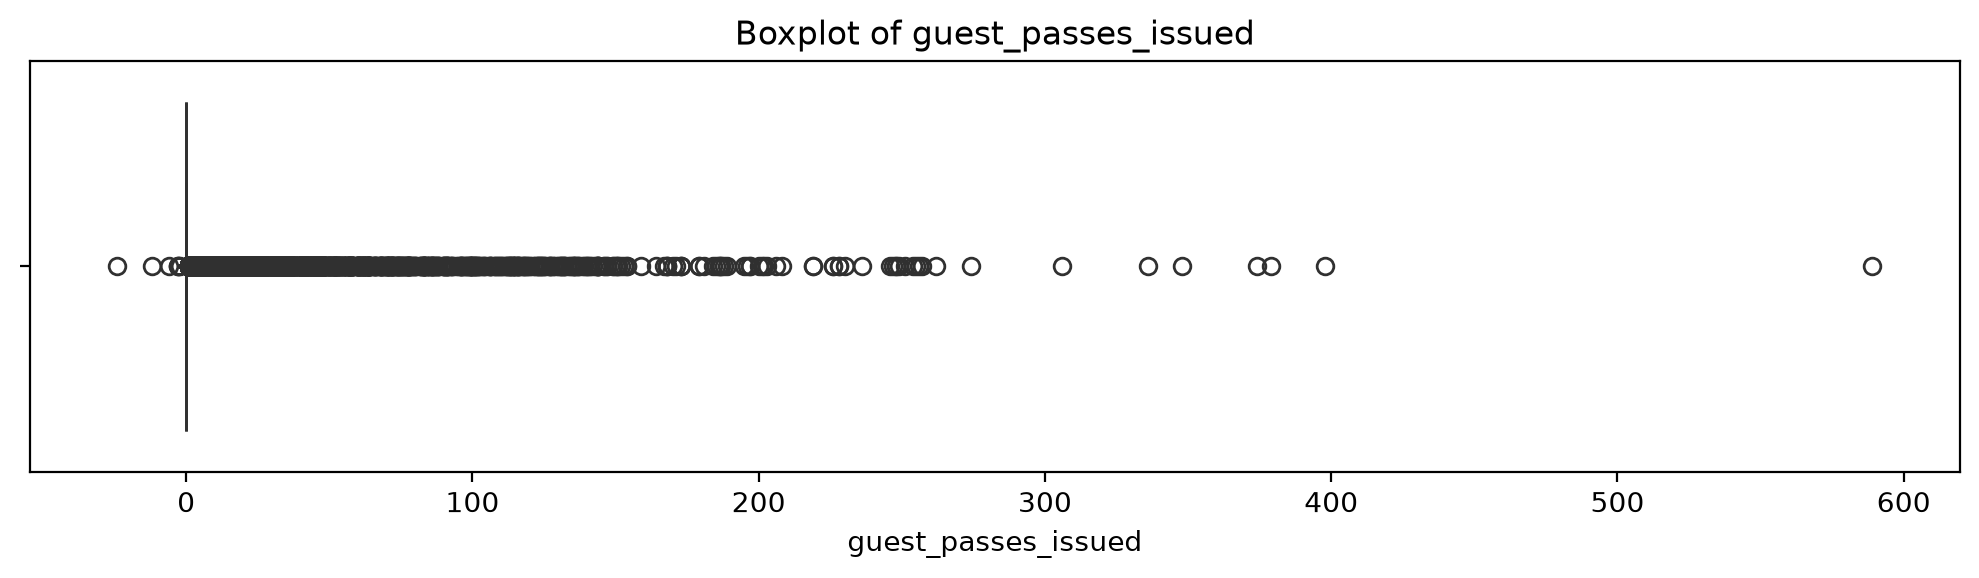

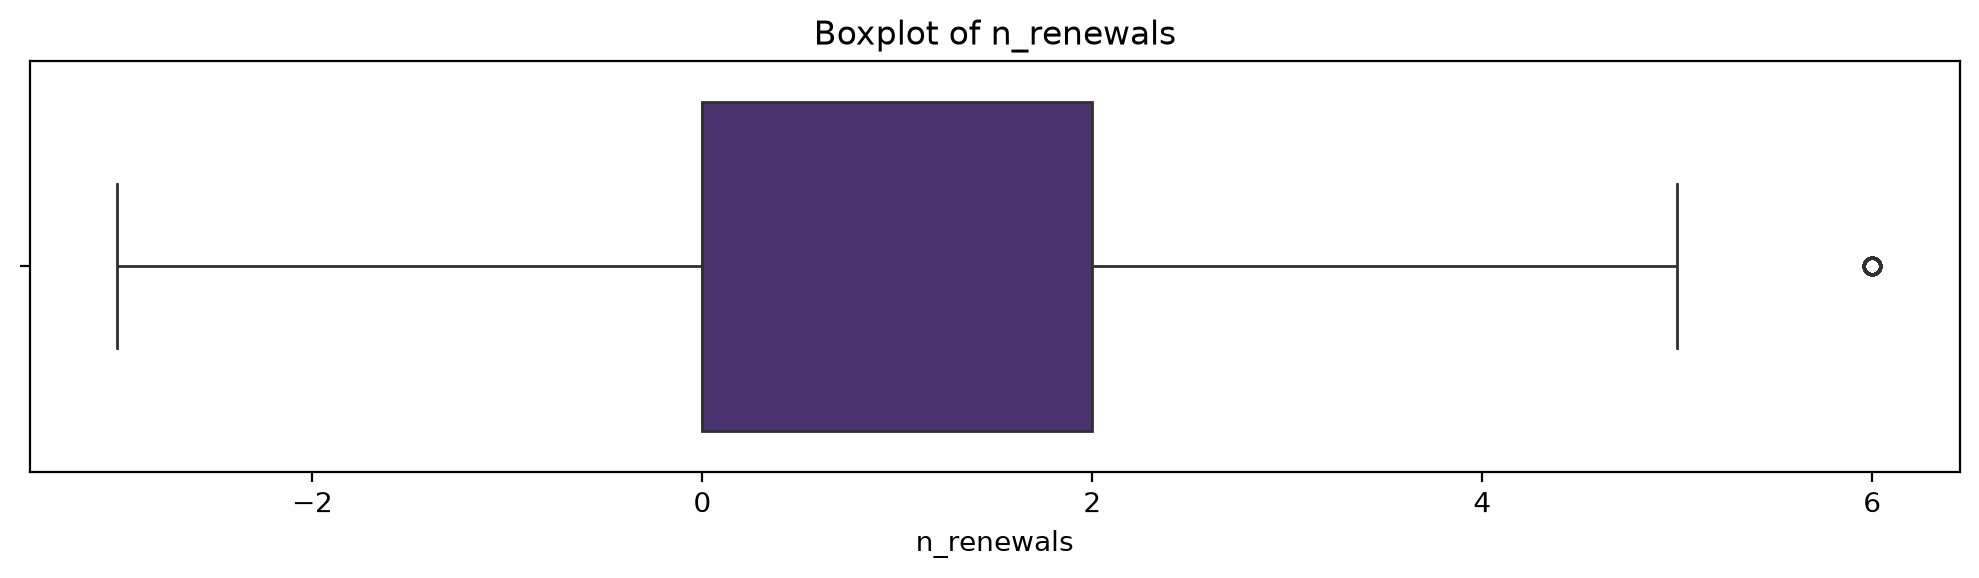

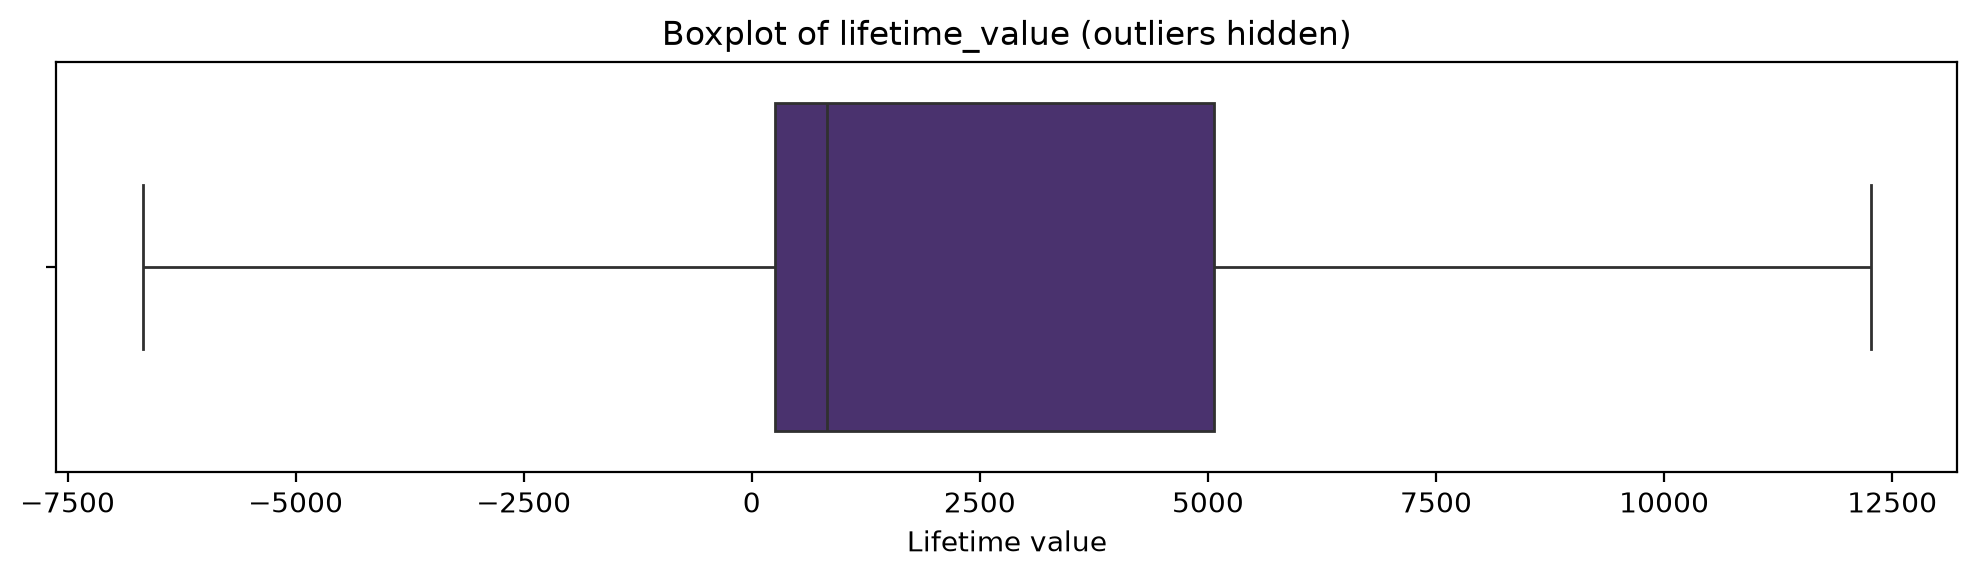

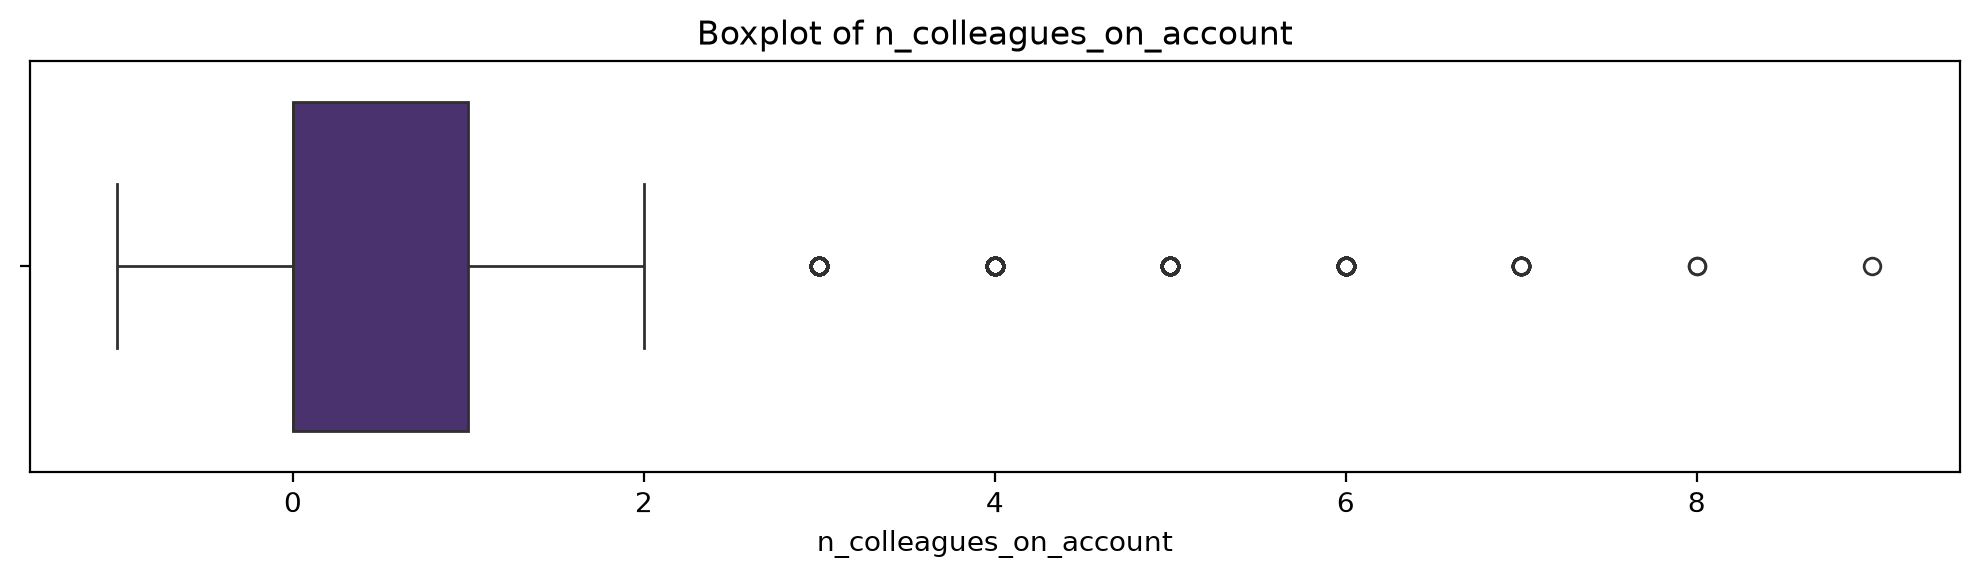

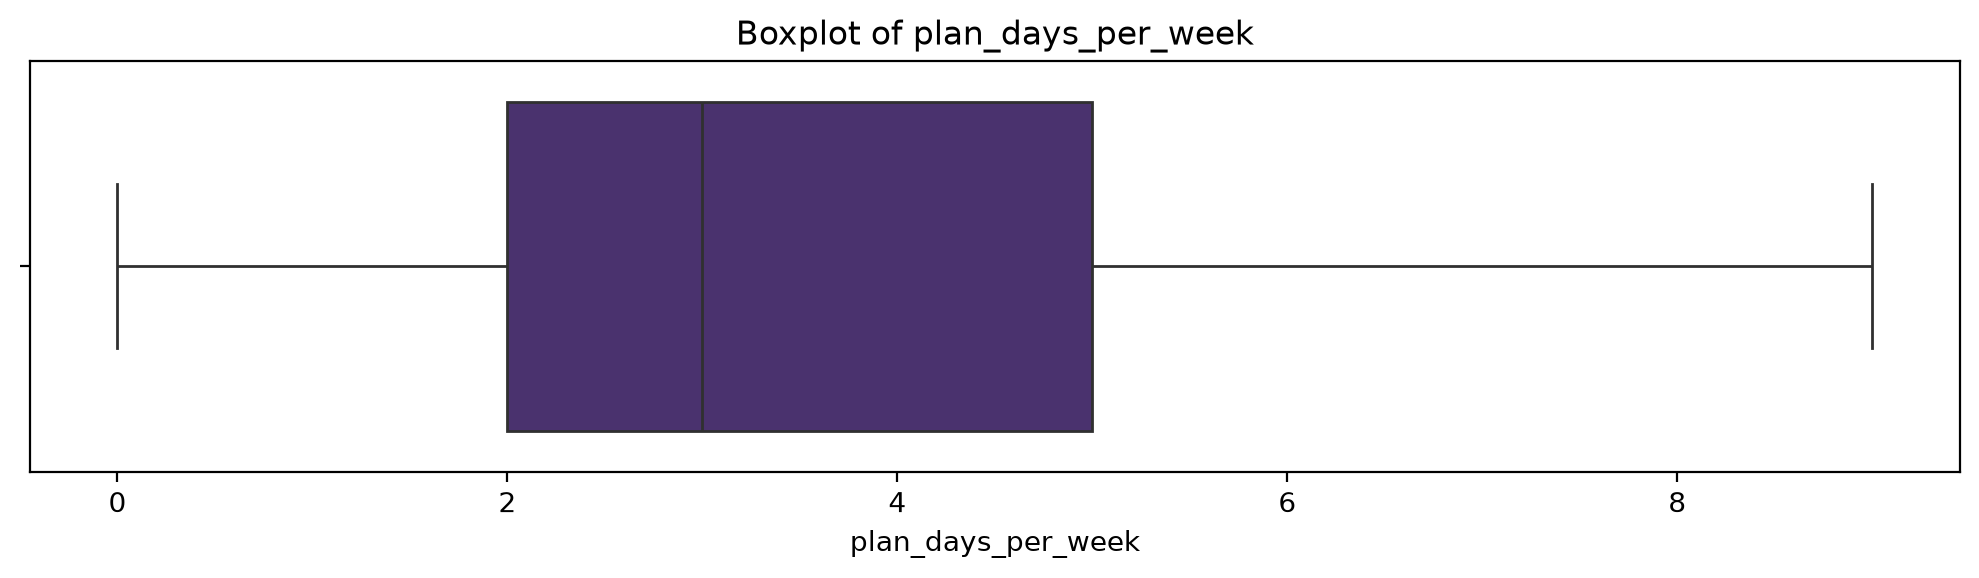

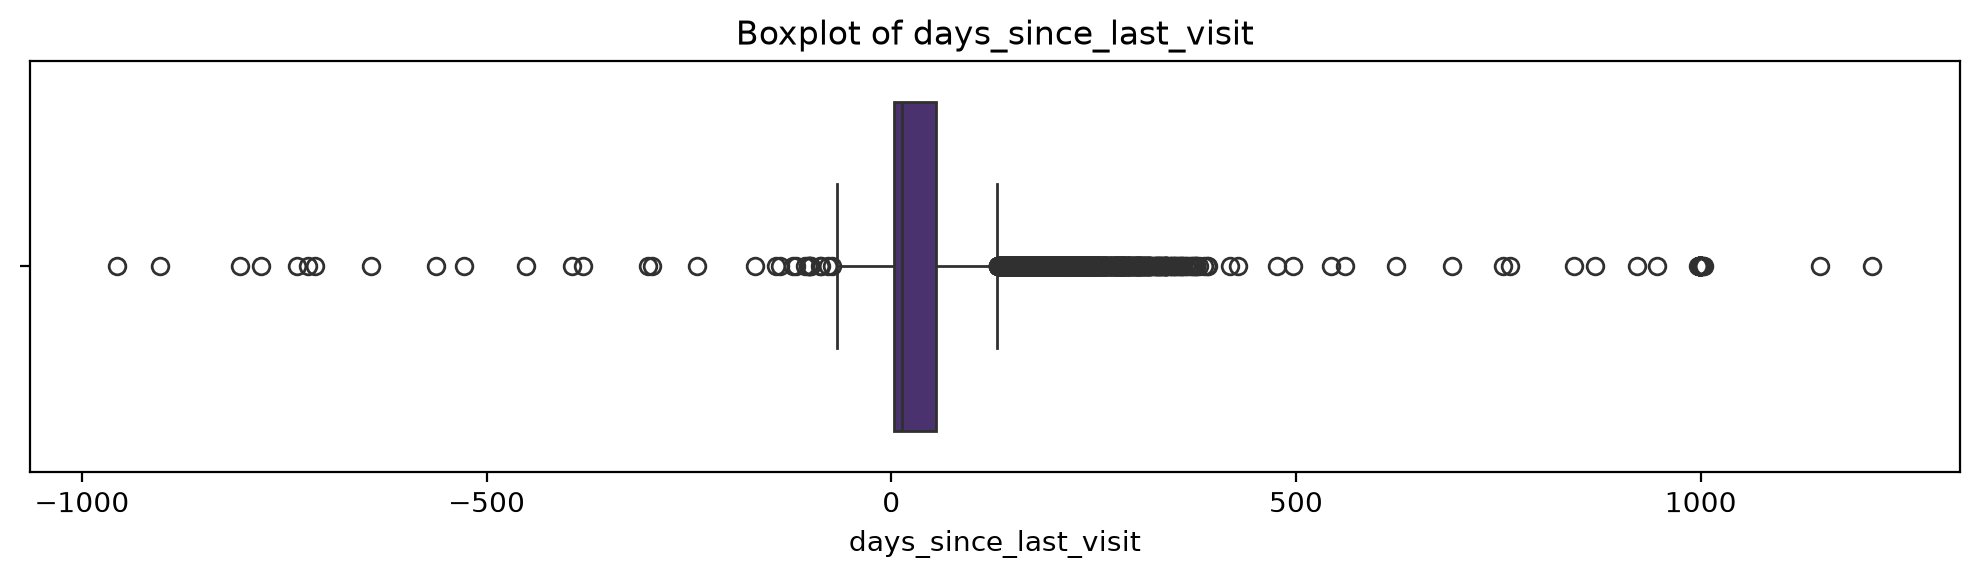

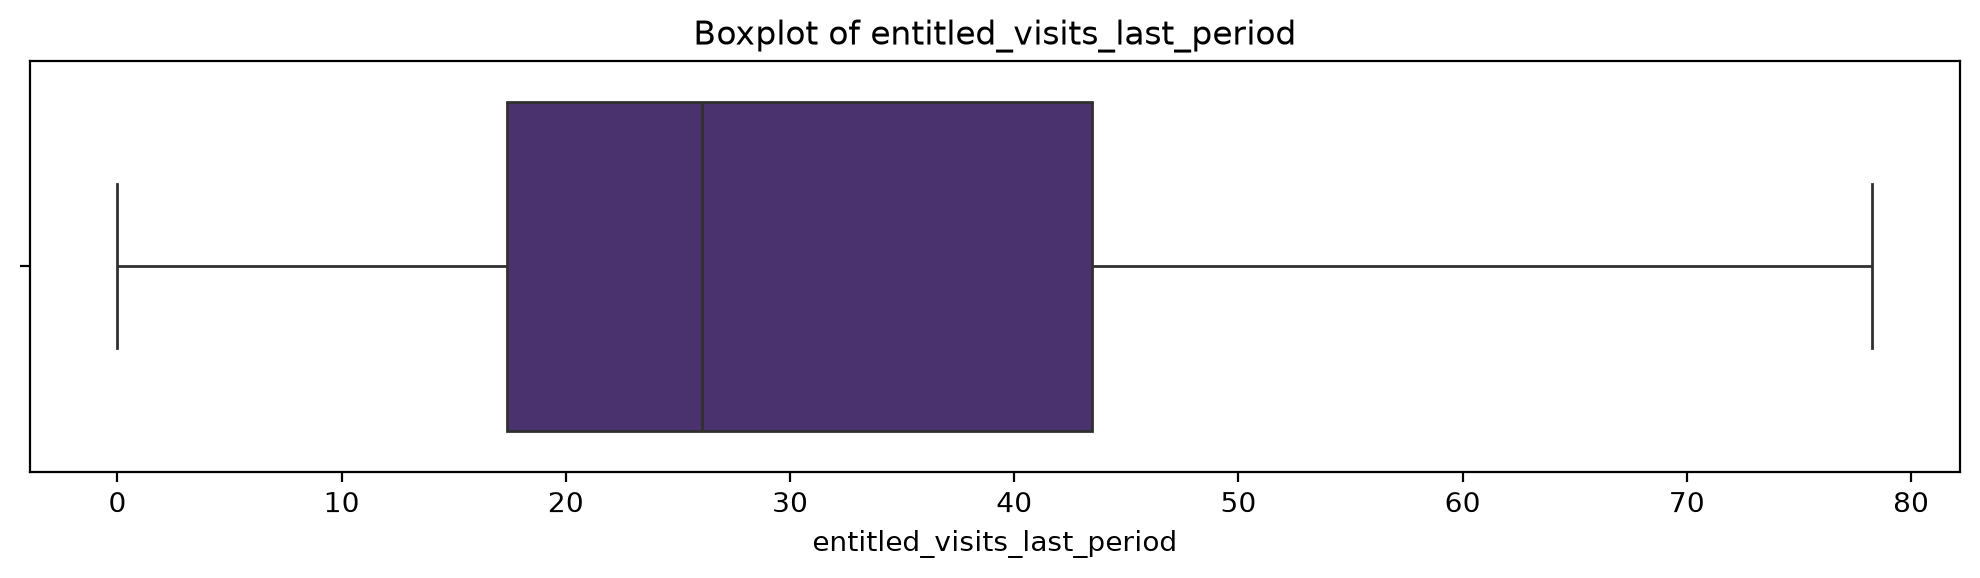

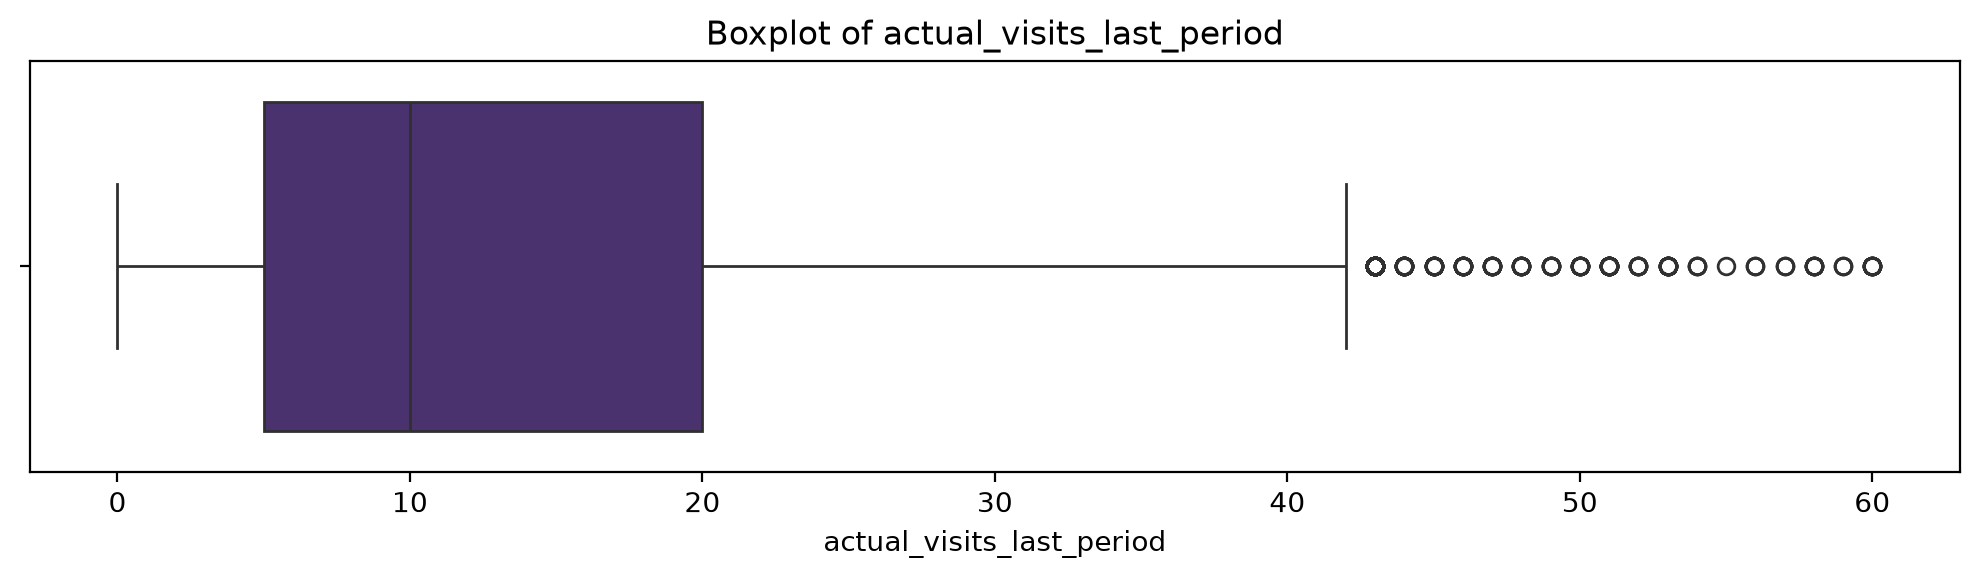

In [13]:
outlier_cols = [
    "age",
    "total_visits",
    "avg_weekly_visits",
    "meeting_room_hours",
    "event_space_hours",
    "guest_passes_issued",
    "n_renewals", 
    "lifetime_value", 
    "n_colleagues_on_account", 
    "plan_days_per_week",
    "days_since_last_visit",
    "entitled_visits_last_period",
    "actual_visits_last_period"
]

for col in outlier_cols:
    plt.figure(figsize=(10, 3))
    values = numeric[col] if col == "lifetime_value" else acdc[col]
    sns.boxplot(x=values, showfliers=(col != "lifetime_value"))
    title = f"Boxplot of {col}"
    if col == "lifetime_value":
        title += " (outliers hidden)"
        plt.xlabel("Lifetime value")
        plt.ticklabel_format(axis="x", style="plain", useOffset=False)
    plt.title(title)
    plt.tight_layout()
    plt.show()

For our variables:

- Age: outliers at very low or very high ages may be data-quality problems if they are unrealistic.
- Total visits: high outliers may be genuinely very active or long-term members.
- Average weekly visits: very high outliers may indicate unusually active members, but they should be checked for plausibility.
- Meeting room hours: high outliers may indicate members who use meeting rooms much more than others, which could be a meaningful customer profile.
- Event space hours: same idea; extreme users may represent a distinct behavioral group.
- Guest passes issued: high values may indicate members who frequently bring clients or guests.
- Number of renewals: high positive values may indicate loyal long-term members, while negative values would be a data-quality problem.

## Correlation and redundancy

Lets try to apply a Spearman correlation to our data to see which behaviors move together and which variables might be redundant when we later build the clustering model. Spearman correlation was used because several numerical variables contain extreme values. As a rank-based measure, Spearman is less sensitive to outliers and can identify monotonic relationships that are not necessarily linear.

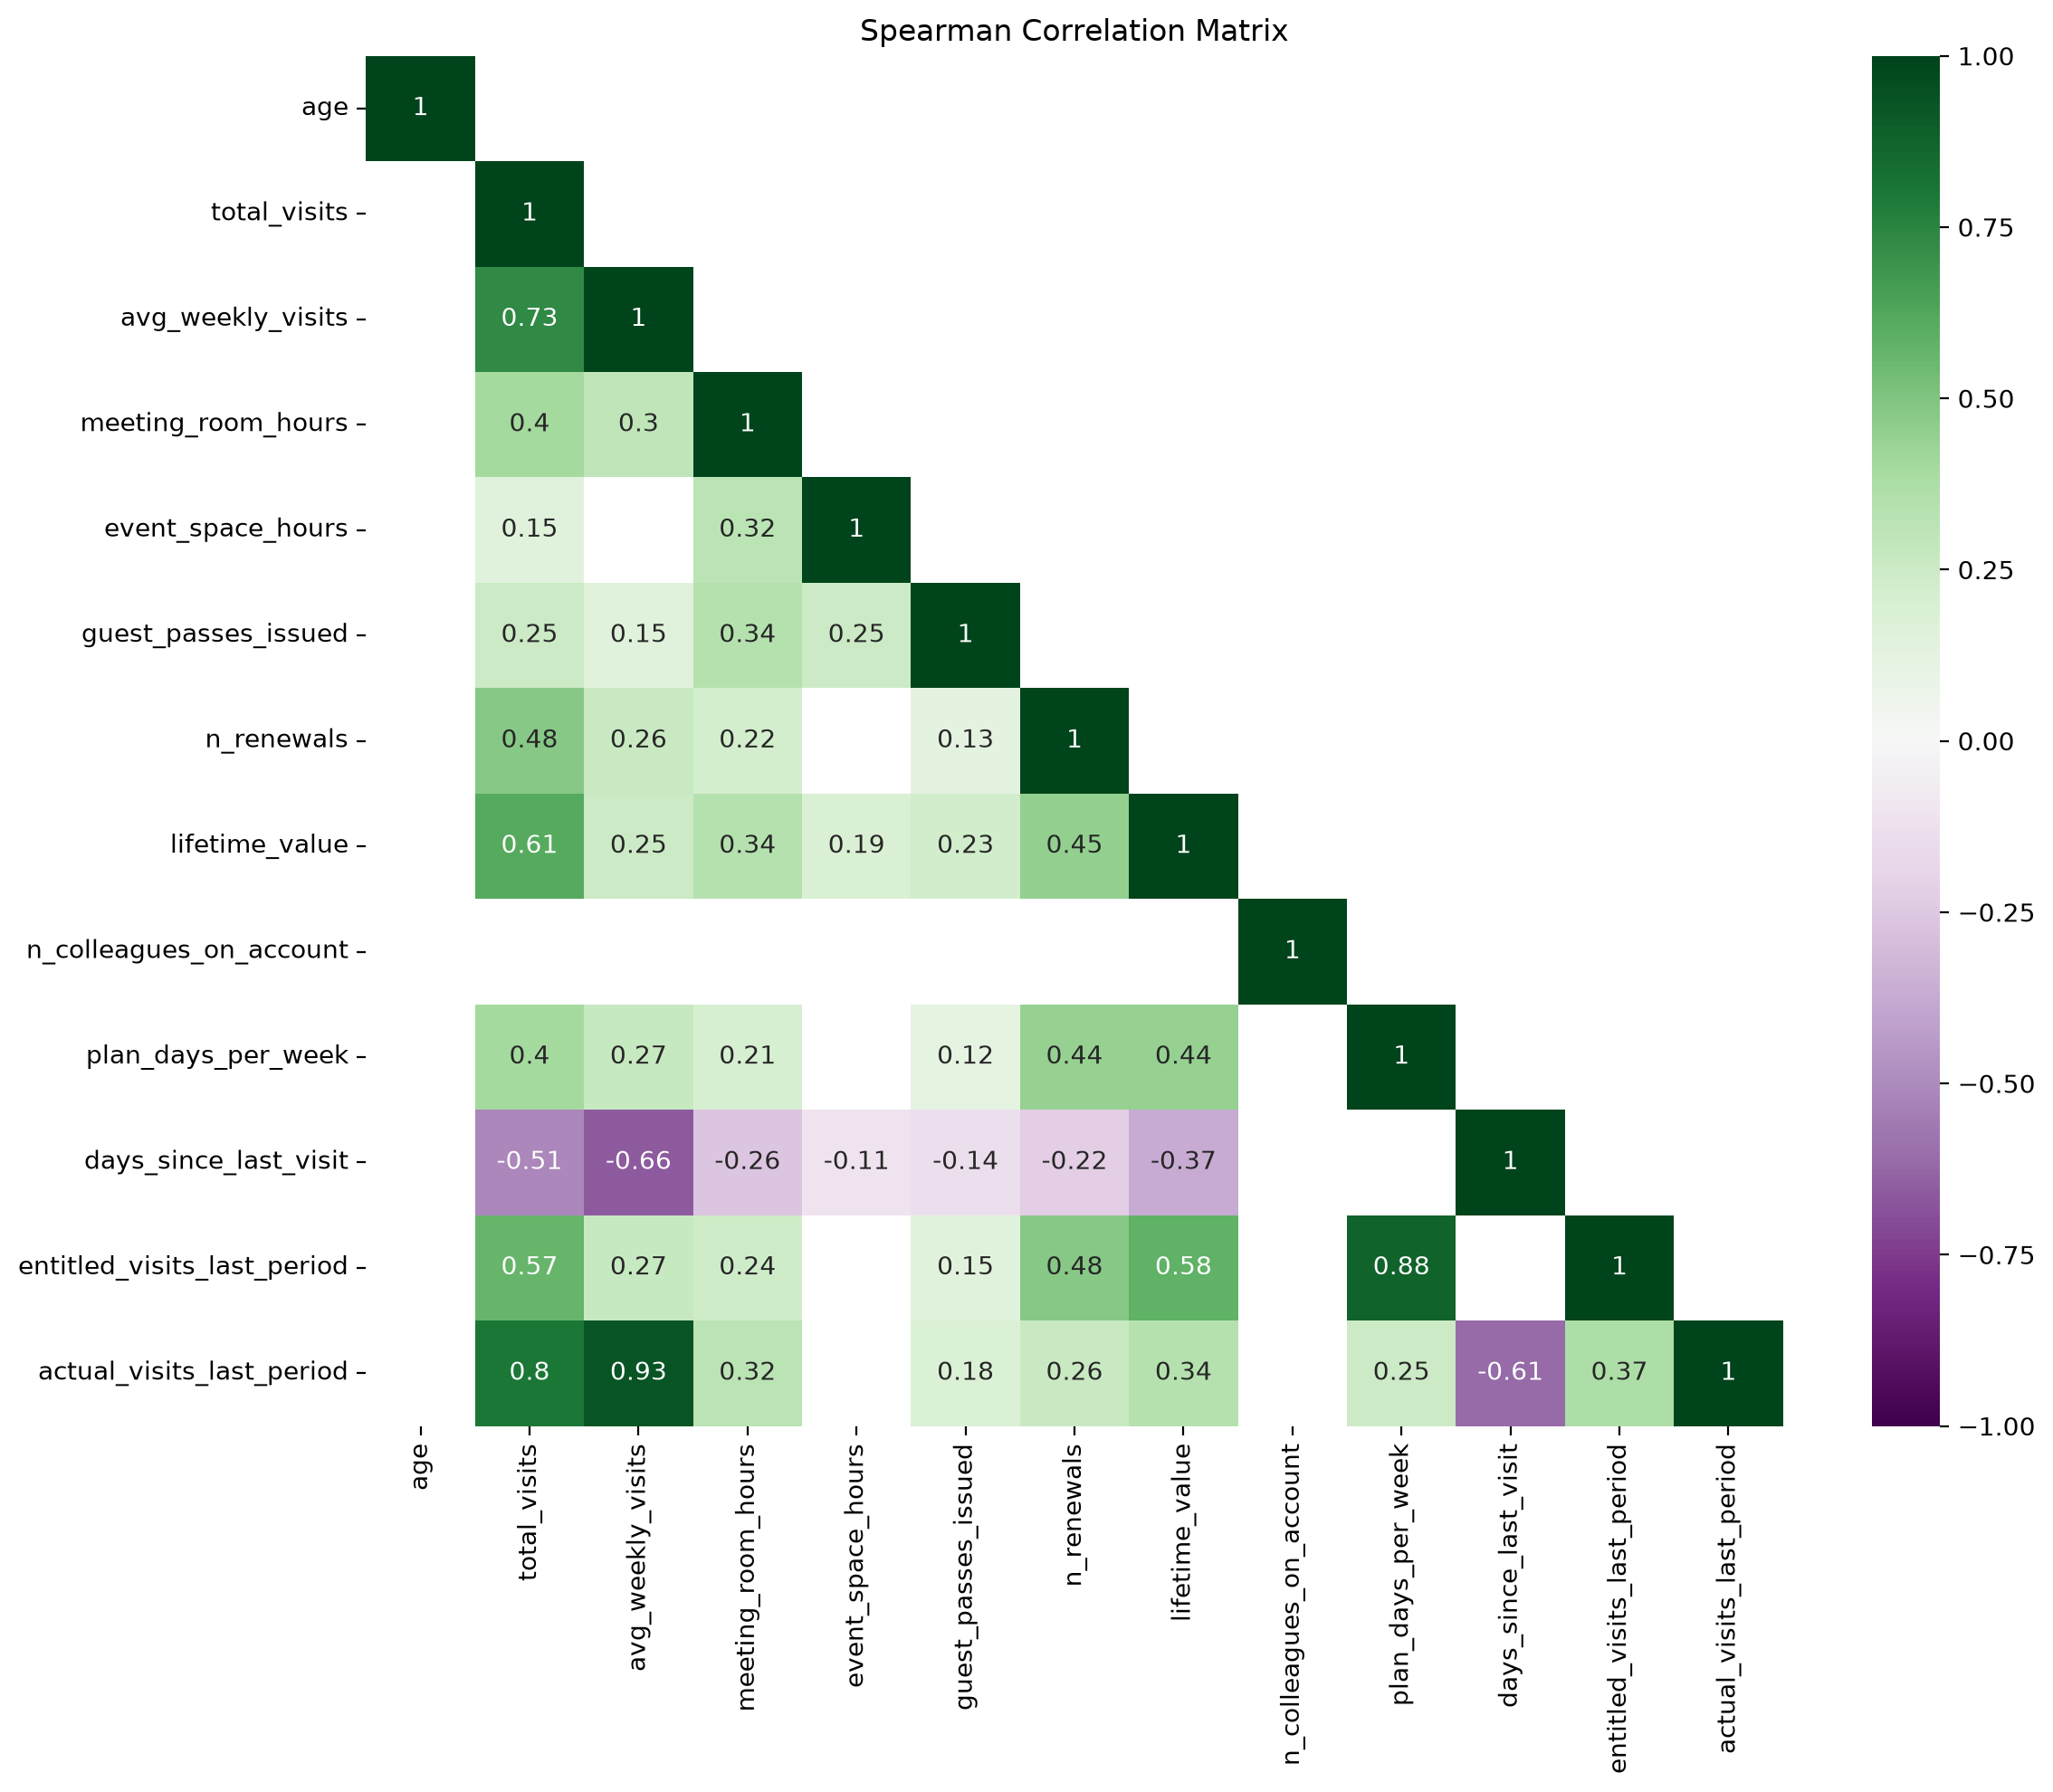

In [14]:
#Variables i want to include in the correlation analysis, aka numeric variables
corr_cols = [
    "age",
    "total_visits",
    "avg_weekly_visits",
    "meeting_room_hours",
    "event_space_hours",
    "guest_passes_issued",
    "n_renewals", 
    "lifetime_value", 
    "n_colleagues_on_account", 
    "plan_days_per_week",
    "days_since_last_visit",
    "entitled_visits_last_period",
    "actual_visits_last_period"
]

numeric["lifetime_value"] = pd.to_numeric(
    acdc["lifetime_value"].astype("string").str.replace(r"[€,]", "", regex=True),
    errors="coerce",
)

corr = numeric[corr_cols].corr(method="spearman").round(2)
plt.figure(figsize=(12, 10)) #size of the graph
sns.heatmap(
    corr,
    mask=(~np.tril(np.ones_like(corr, dtype=bool))) | (corr.abs() < 0.10),
    #tril hides the upper traingle, upper triangle is True but Seaborn hides True cells, so we add the "~"
    annot=True,#write the correlation value inside each square 
    cmap='PRGn', #colour palette
    center=0,
    vmin=-1,
    vmax=1,
)

plt.title("Spearman Correlation Matrix")
plt.tight_layout() #helps prevent labels from overlapping or being cut off
plt.show()
# also the values close to zero(check distributions because they could still relate to eachother



# avg_weekly_visits ↔ actual_visits_last_period = 0.93
# Members with higher weekly visit frequency generally also have more actual visits in the recent period.
# people who rank high in average weekly visits also rank high on actual visits last period

# days_since_last_visit ↔ avg_weekly_visits = -0.66
# As the number of days since the last visit increases, weekly visit frequency generally decreases.

# Age shows little monotonic(means if one grows the other typically grows or decreases too)
# relationship with all variables according to Spearman correlation but it doesnt mean it has no relationship at all

Spearman correlation was used to examine monotonic relationships between numerical variables. The upper triangle was removed because the correlation matrix is symmetrical, and very weak correlations were hidden to improve readability. Strong correlations may indicate related or potentially redundant variables. However, correlations close to zero do not necessarily indicate the absence of a relationship, as non-linear patterns may still be present and should be investigated through distributions and other visualizations.

### Detailed look at specific variables

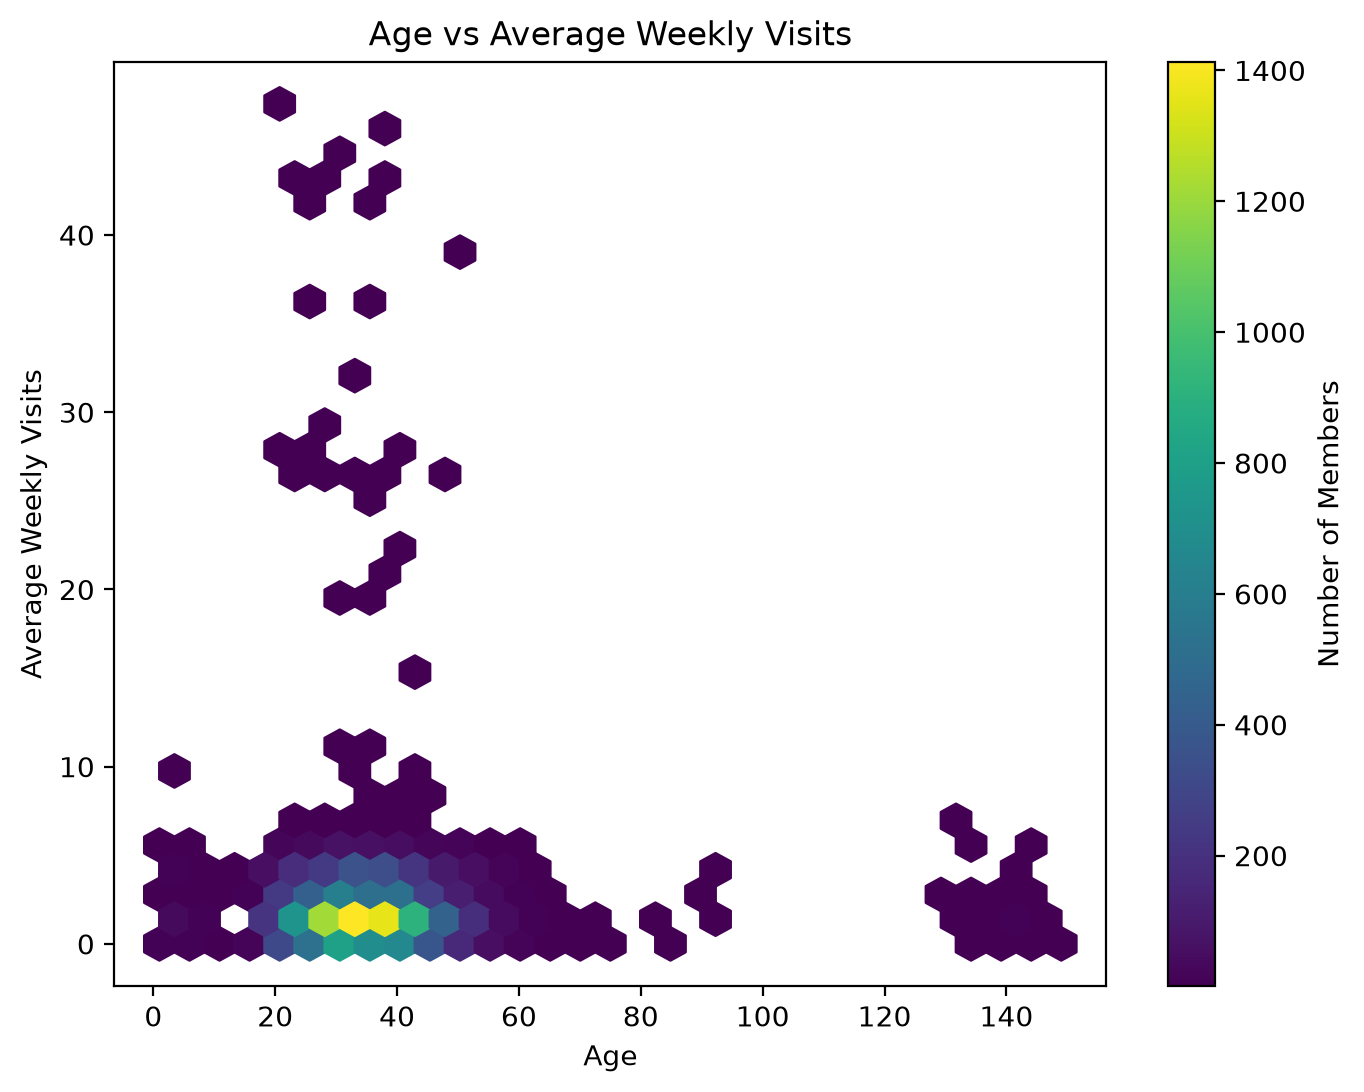

Spearman correlation: 0.01


In [15]:
plt.figure(figsize=(8, 6))

plt.hexbin(
    acdc["age"],
    acdc["avg_weekly_visits"],
    gridsize=30,
    cmap="viridis",
    mincnt=1
)

plt.xlabel("Age")
plt.ylabel("Average Weekly Visits")
plt.title("Age vs Average Weekly Visits")

plt.colorbar(label="Number of Members")
plt.show()

rho = acdc["age"].corr(acdc["avg_weekly_visits"], method="spearman")
print("Spearman correlation:", round(rho, 2))

The hexbin plot does not suggest a clear increasing or decreasing relationship between age and average weekly visits. Instead, the observations are concentrated in particular areas of the distribution, showing that members with similar ages can have quite different levels of weekly activity.

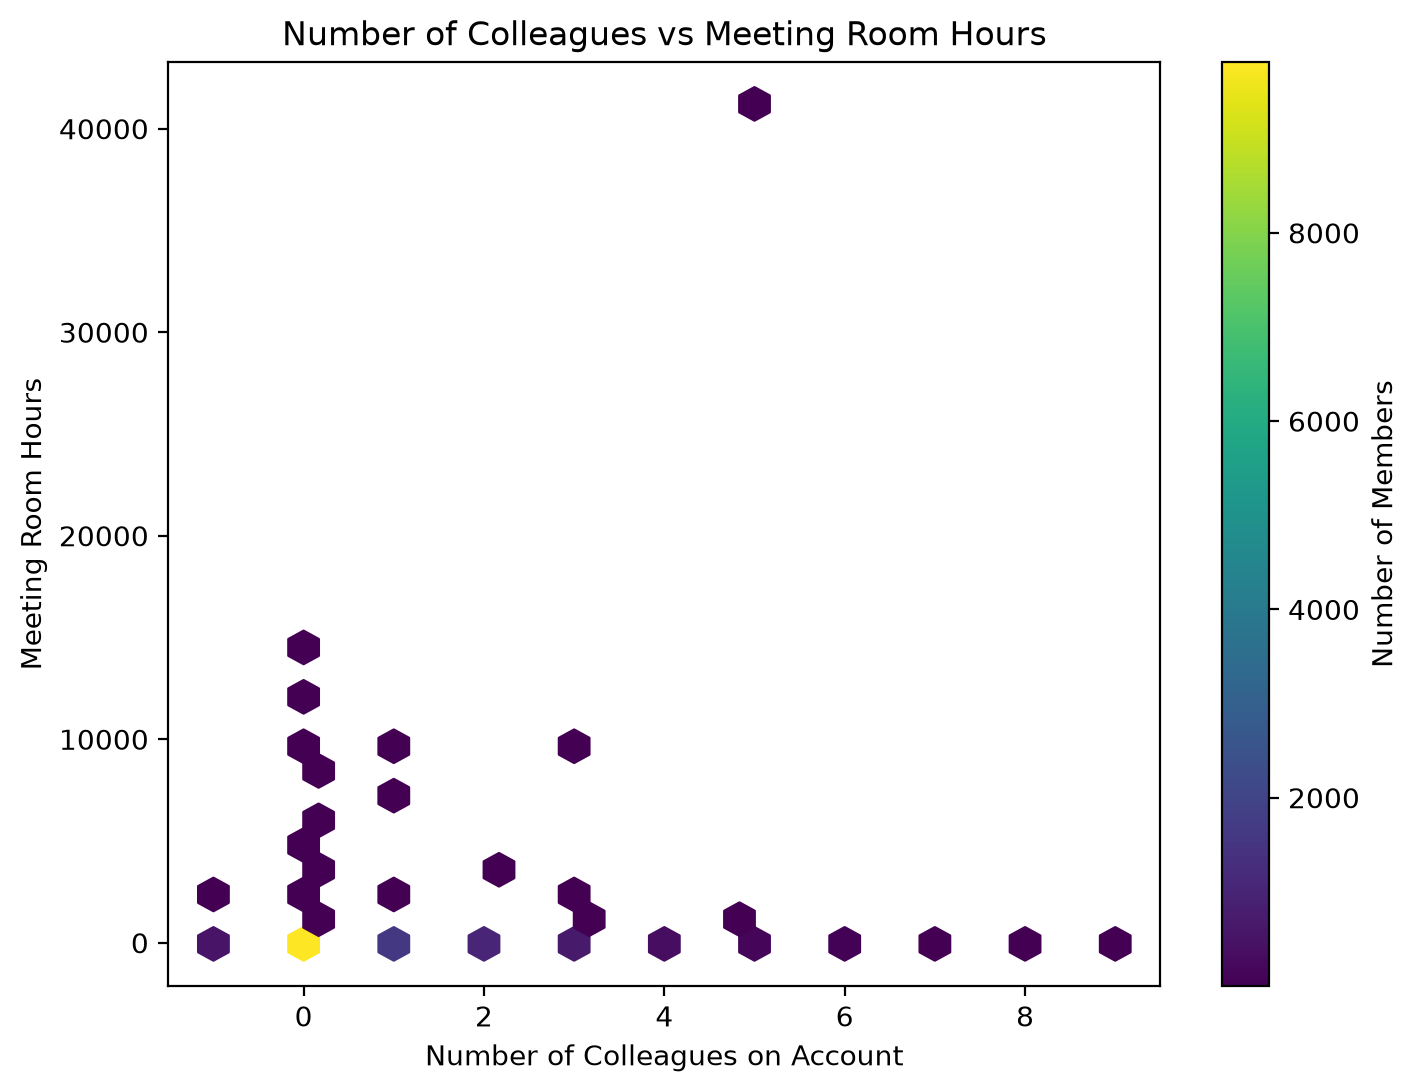

Spearman correlation: 0.01


In [16]:
plt.figure(figsize=(8, 6))

plt.hexbin(
    acdc["n_colleagues_on_account"],
    acdc["meeting_room_hours"],
    gridsize=30,
    cmap="viridis",
    mincnt=1
)

plt.xlabel("Number of Colleagues on Account")
plt.ylabel("Meeting Room Hours")
plt.title("Number of Colleagues vs Meeting Room Hours")

plt.colorbar(label="Number of Members")
plt.show()
rho = acdc["n_colleagues_on_account"].corr(acdc["meeting_room_hours"], method="spearman")
print("Spearman correlation:", round(rho, 2))

No clear monotonic relationship is visible between the number of colleagues on an account and meeting-room usage. Most members are concentrated around low values for both variables. However, the graph reveals that there is extremely large meeting-room-hour values, plus a negative value for number of colleagues. Those are strong anomalies.

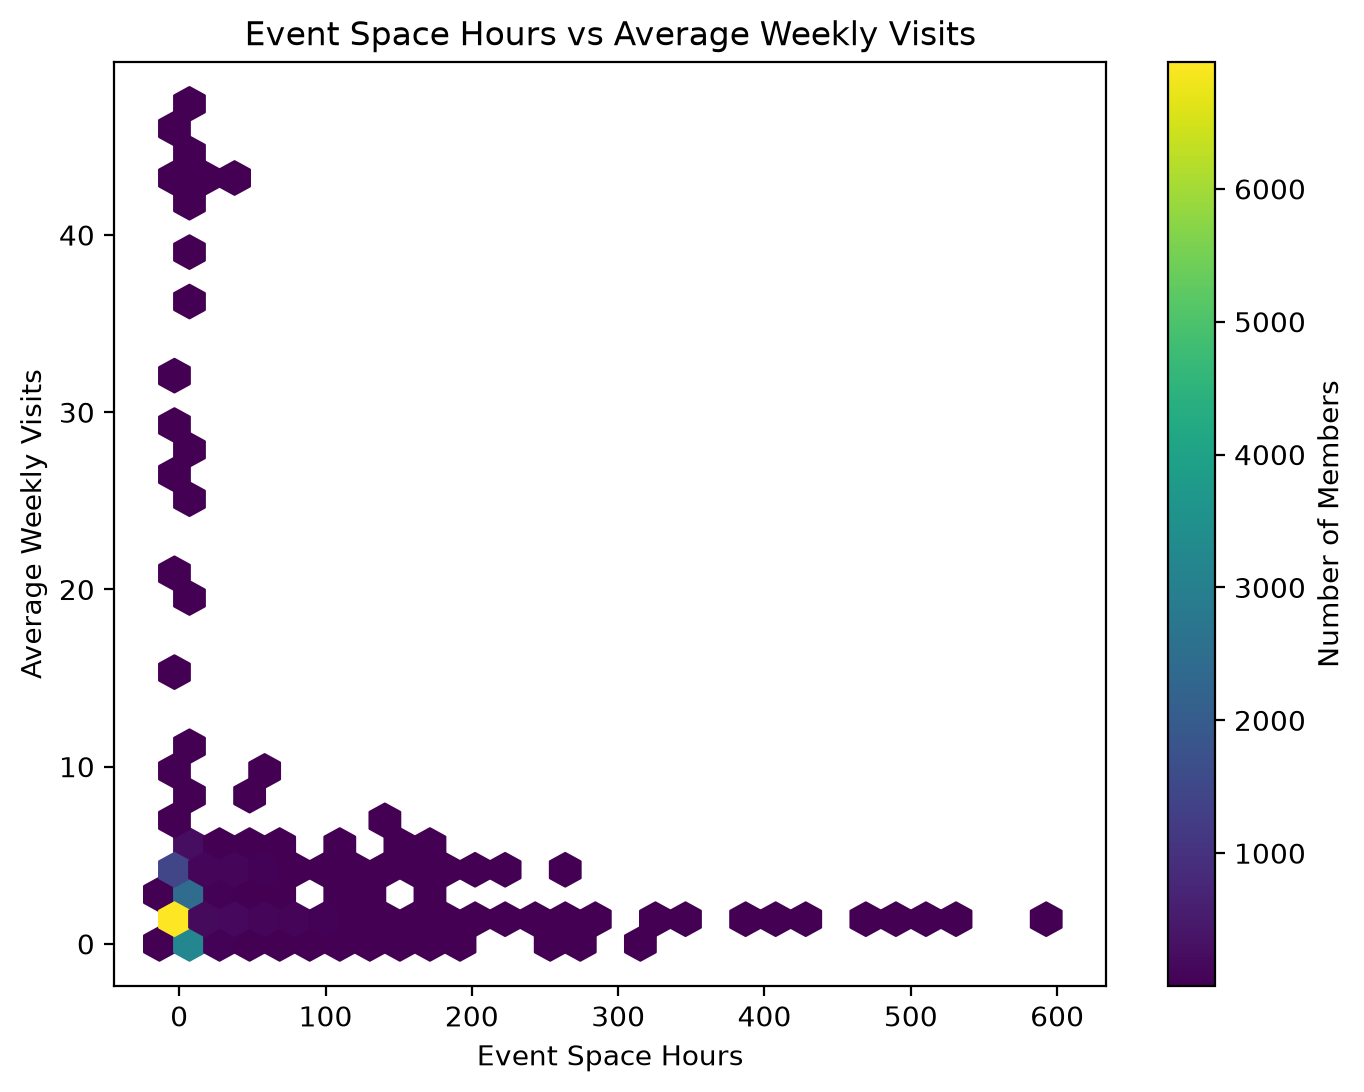

Spearman correlation: 0.07


In [17]:
plt.figure(figsize=(8, 6))

plt.hexbin(
    acdc["event_space_hours"],
    acdc["avg_weekly_visits"],
    gridsize=30,
    cmap="viridis",
    mincnt=1
)

plt.xlabel("Event Space Hours")
plt.ylabel("Average Weekly Visits")
plt.title("Event Space Hours vs Average Weekly Visits")

plt.colorbar(label="Number of Members")
plt.show()

rho = acdc["event_space_hours"].corr(acdc["avg_weekly_visits"], method="spearman")
print("Spearman correlation:", round(rho, 2))

Event-space usage shows little evidence of a strong monotonic relationship with average weekly visits. Most members have low values for both variables, while high event-space usage is mainly associated with low weekly visits. This suggests that event-space hours may capture a different behavioral dimension from regular workspace attendance.

                             missing       min  median     mean         max   skew  kurtosis  pct_zero  n_negative
age                              557      1.00   34.00    34.86      149.00   3.03     28.90      0.00           0
n_colleagues_on_account            0     -1.00    0.00     0.54        9.00   2.12      4.83     69.18         565
plan_days_per_week                 0      0.00    3.00     3.39        9.00   0.93      0.27      0.28           0
days_since_last_visit              0   -956.00   13.00   117.19     1212.00   2.72      5.98      0.55          56
total_visits                       0   -112.00   34.00   110.39     6530.00   6.82    159.76      0.71          42
avg_weekly_visits                  0      0.00    1.42     1.78       47.40  10.27    190.12      0.09           0
entitled_visits_last_period        0      0.00   26.09    27.51       78.27   0.73      0.00      0.06           0
actual_visits_last_period          0      0.00   10.00    13.80       60.00   1.

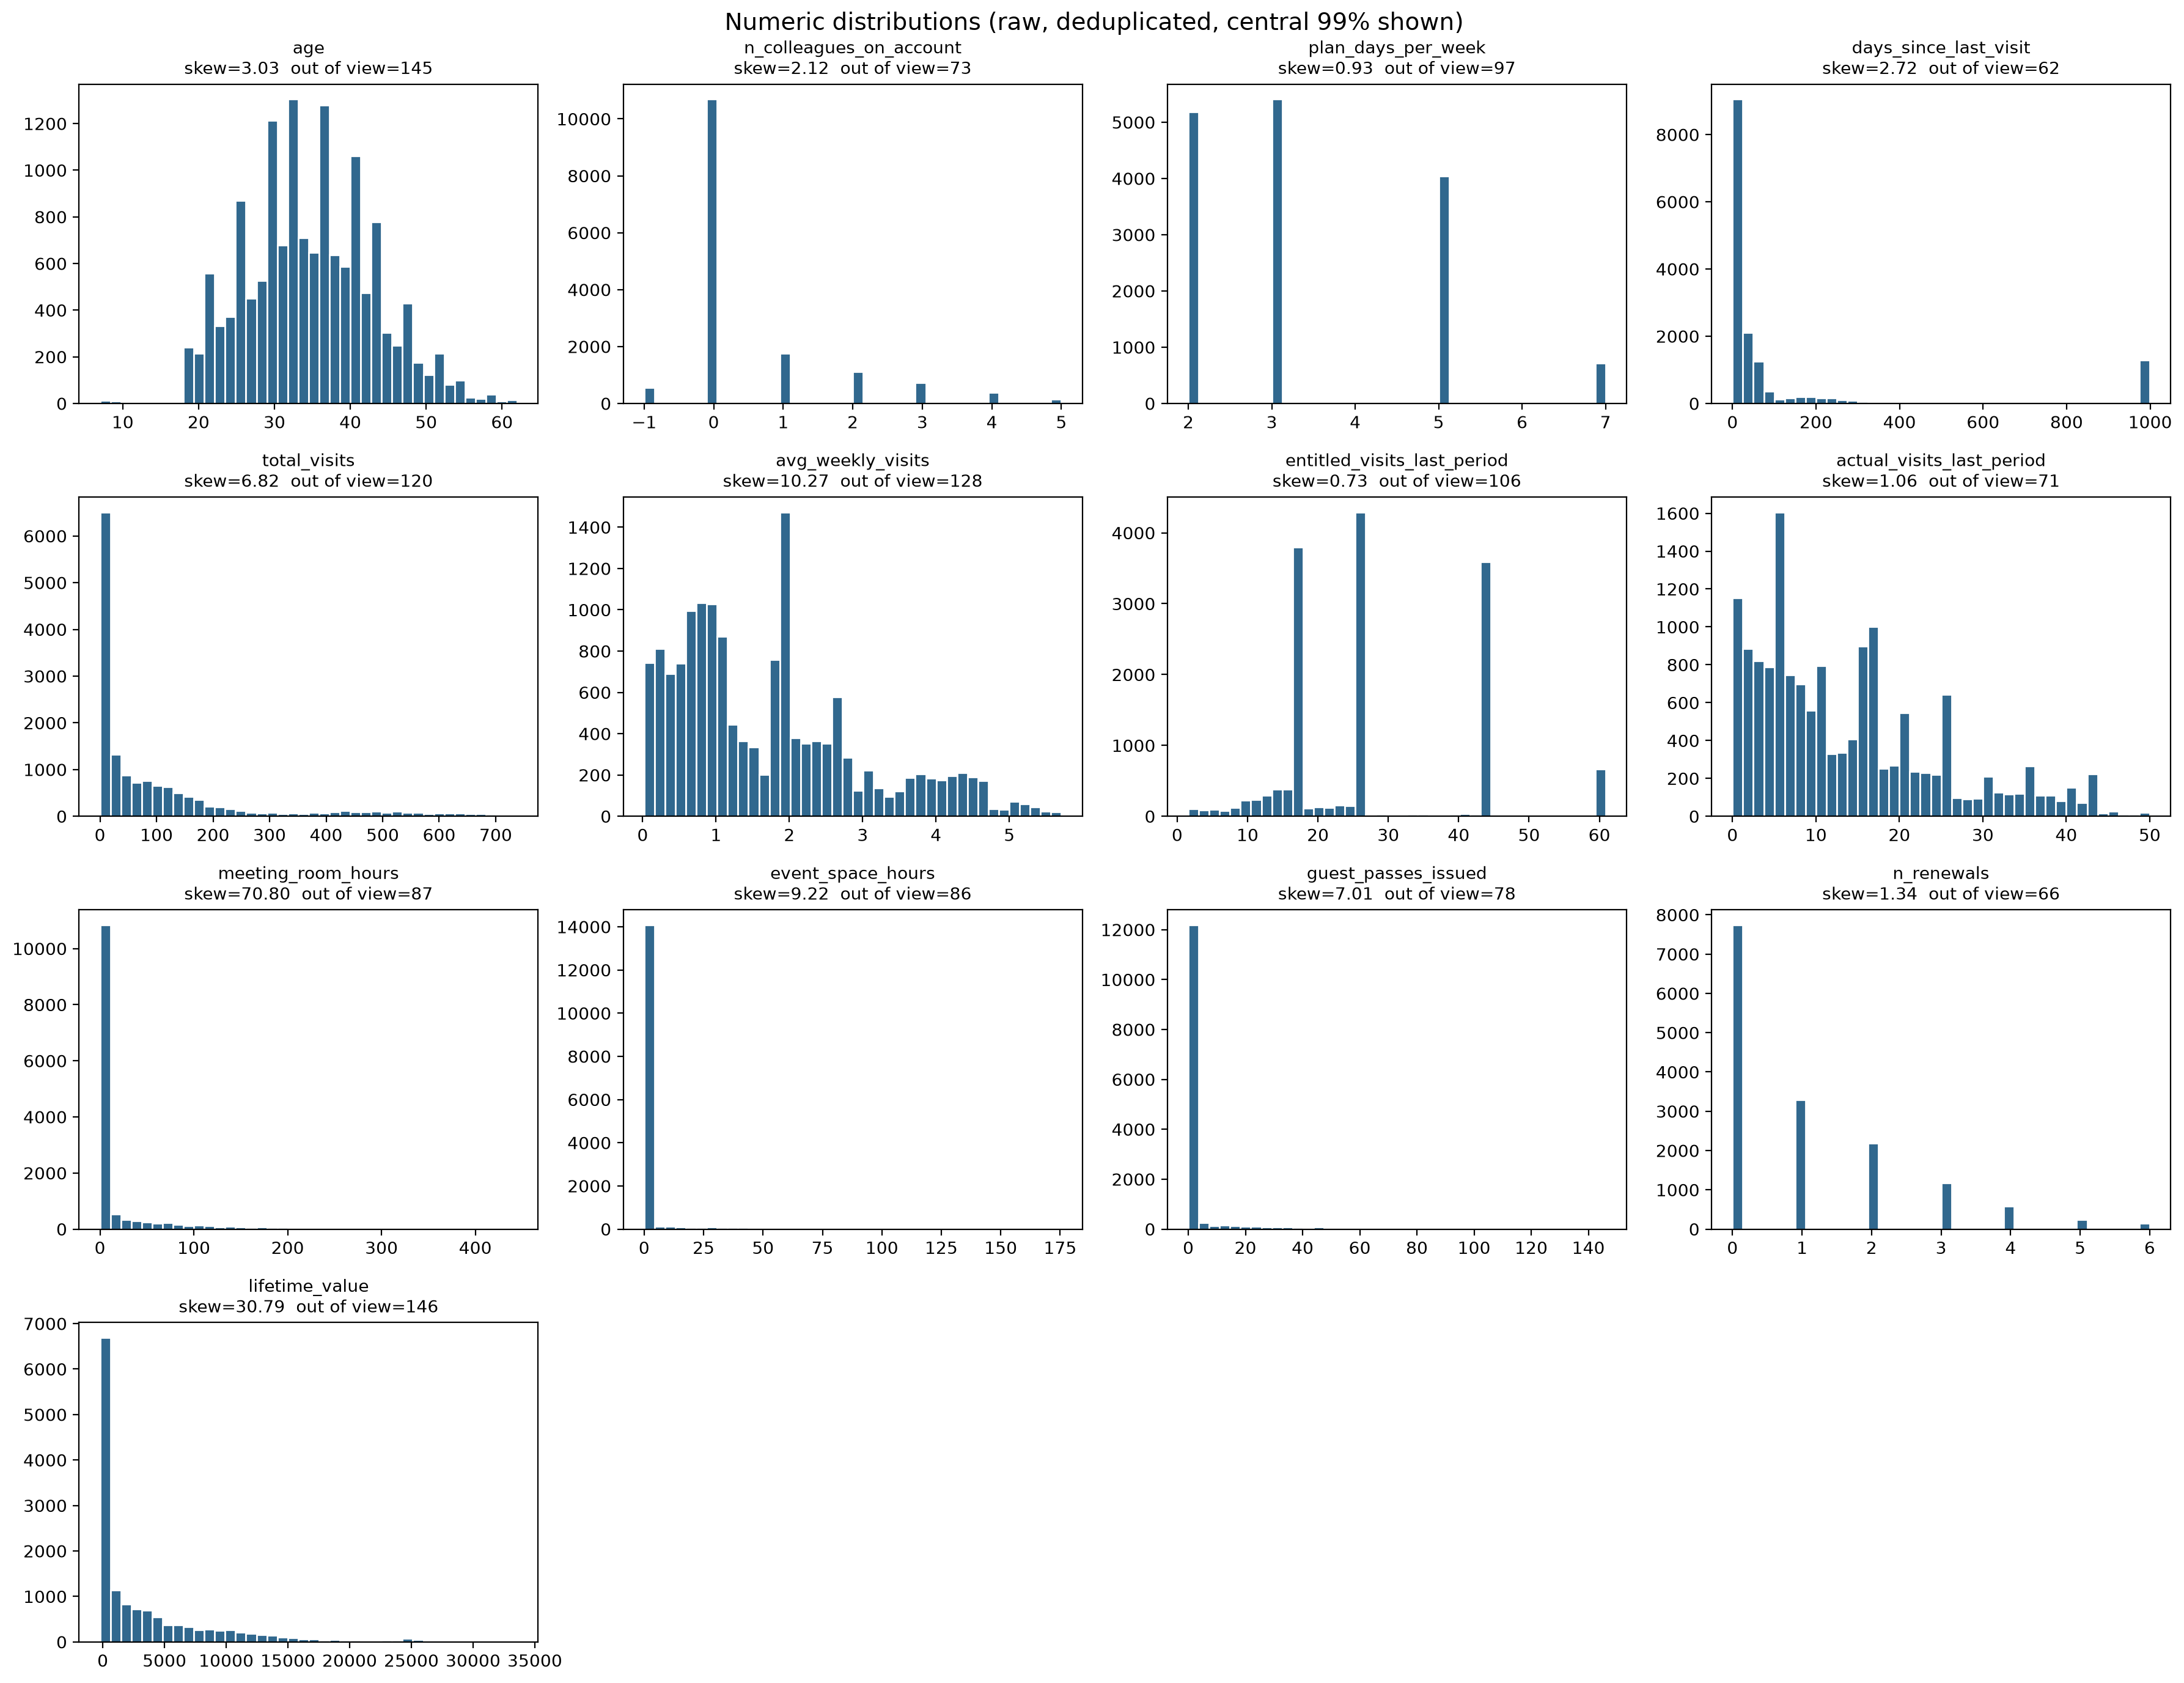

In [18]:
acdc = acdc.drop_duplicates()
acdc["lifetime_value"] = pd.to_numeric(acdc["lifetime_value"].astype(str).str.replace("€", "").str.replace(",", "").str.strip(), errors="coerce")

num_cols = ["age", "n_colleagues_on_account", "plan_days_per_week", "days_since_last_visit",
            "total_visits", "avg_weekly_visits", "entitled_visits_last_period",
            "actual_visits_last_period", "meeting_room_hours", "event_space_hours",
            "guest_passes_issued", "n_renewals", "lifetime_value"]

stats = pd.DataFrame({
    "missing": acdc[num_cols].isna().sum(),
    "min": acdc[num_cols].min(),
    "median": acdc[num_cols].median(),
    "mean": acdc[num_cols].mean(),
    "max": acdc[num_cols].max(),
    "skew": acdc[num_cols].skew(),
    "kurtosis": acdc[num_cols].kurt(),
    "pct_zero": (acdc[num_cols] == 0).mean() * 100,
    "n_negative": (acdc[num_cols] < 0).sum(),
}).round(2)
print(stats.to_string())
stats.to_csv("numeric_stats.csv")

fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, col in zip(axes.flat, num_cols):
    s = acdc[col].dropna()
    lo, hi = s.quantile([0.005, 0.995])
    s_clip = s[(s >= lo) & (s <= hi)]
    ax.hist(s_clip, bins=40, color=PALETTE[2], edgecolor="white")
    ax.set_title(f"{col}\nskew={s.skew():.2f}  out of view={len(s) - len(s_clip)}", fontsize=10)
for ax in axes.flat[len(num_cols):]:
    ax.axis("off")
fig.suptitle("Numeric distributions (raw, deduplicated, central 99% shown)", fontsize=14)
fig.tight_layout()
fig.savefig("numeric_distributions.png", dpi=110)

## Feature Engineering

New features are created from existing variables to capture member behaviour in a simpler and potentially more useful way for segmentation.

Two features are explored:
- **Visit utilization:** how much of the member's allowed visits were actually used.
- **Number of services used:** how many different additional services each member uses.

#### Visit utilization

In [19]:
acdc["visit_utilization"] = (
    acdc["actual_visits_last_period"] /
    acdc["entitled_visits_last_period"].replace(0, np.nan)
)

acdc["visit_utilization"].describe()

count    15440.000000
mean         0.517532
std          0.312207
min          0.000000
25%          0.238996
50%          0.517539
75%          0.804906
max          1.000000
Name: visit_utilization, dtype: float64

Member was allowed 20 visits, member actually used 10
- 10 / 20 = 0.5, they used 50% of their allowed visits 

Visit utilization measures the proportion of entitled visits that each member actually used. The average visit utilization is approximately 52%, meaning that members used, on average, about half of the visits available in their plan. Tere are members with very low and very high utilization, suggesting different levels of engagement with their membership plans.

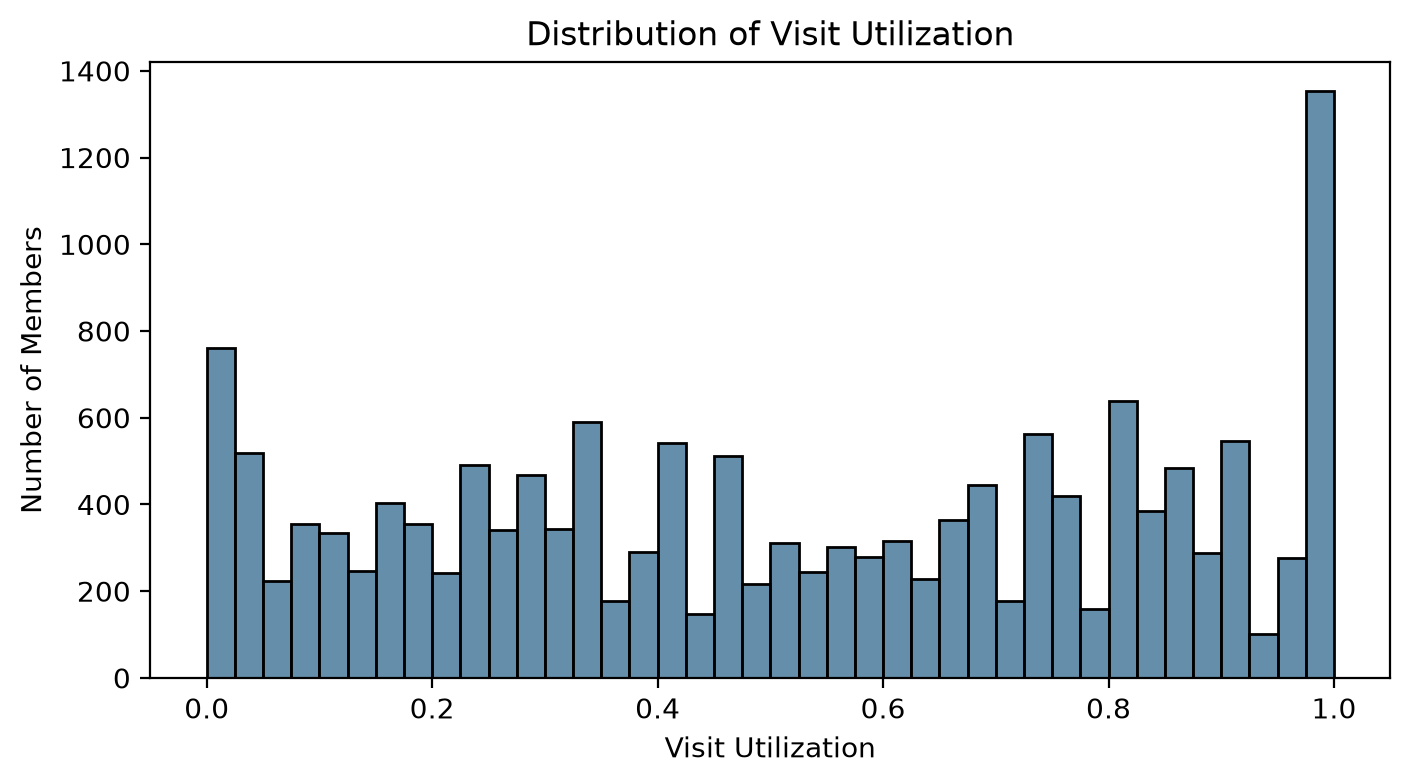

In [20]:
plt.figure(figsize=(8, 4))

sns.histplot(
    acdc["visit_utilization"].dropna(),
    bins=40,
    color=PALETTE[2]
)

plt.title("Distribution of Visit Utilization")
plt.xlabel("Visit Utilization")
plt.ylabel("Number of Members")

plt.show()

#### Number of Services Used

This feature counts how many different additional services each member uses.
It may help distinguish members who mainly use the basic workspace from members
who make broader use of ACDC's services.

In [21]:
service_cols = [
    "uses_meeting_rooms",
    "uses_event_space",
    "uses_guest_passes",
    "uses_print",
    "uses_mail_handling",
    "uses_phone_booths",
    "uses_day_passes",
    "uses_storage",
    "uses_bike_locker"
]

acdc["n_services_used"] = acdc[service_cols].sum(axis=1)

acdc["n_services_used"].value_counts().sort_index()

n_services_used
0    3087
1    4643
2    3236
3    2139
4    1395
5     690
6     223
7      34
8       3
Name: count, dtype: int64

The most common number of services used is 1, with 4,645 members. Most members use only a small number of additional services, while members using many different services are much less common. This may help distinguish between members with basic service usage and members with more engagement with ACDC's services.

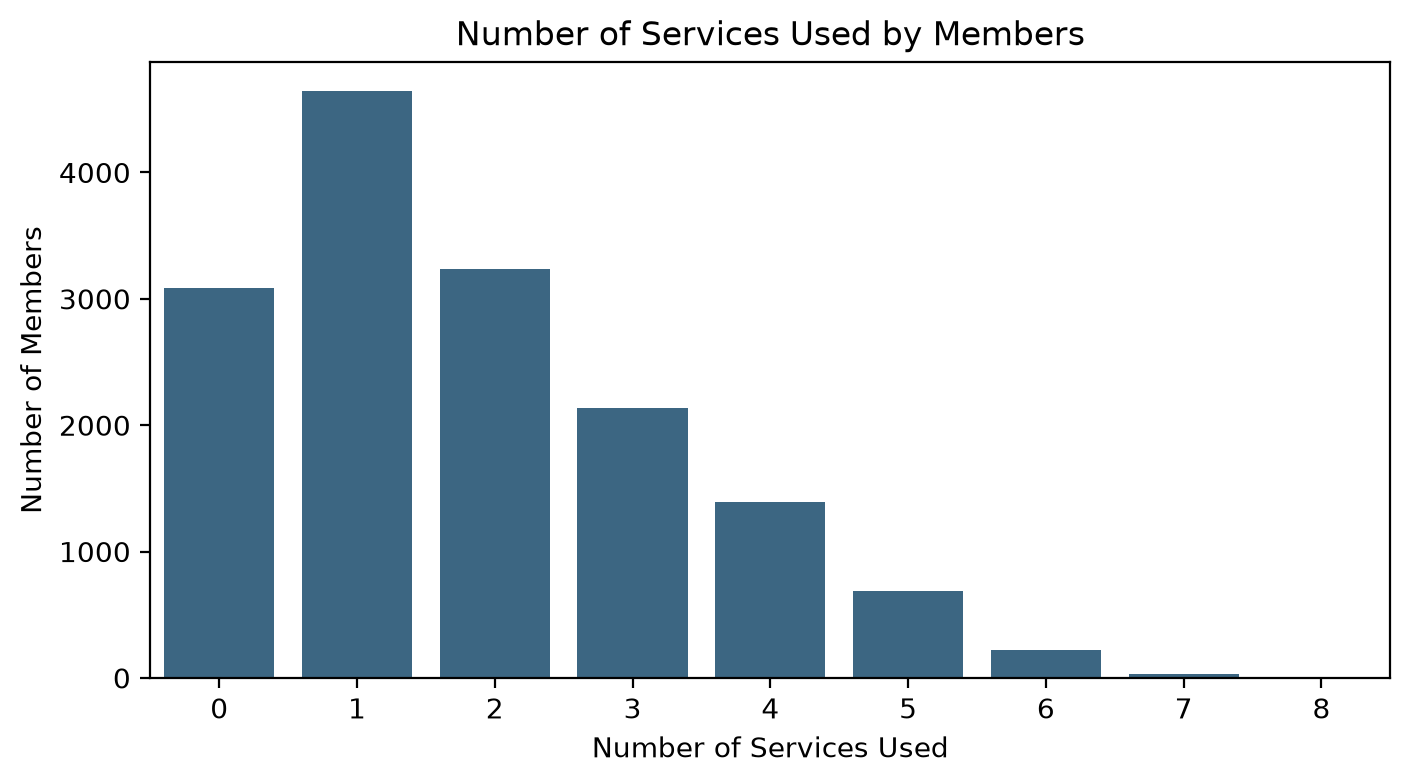

In [22]:
plt.figure(figsize=(8, 4))

sns.countplot(
    data=acdc,
    x="n_services_used",
    color=PALETTE[2]
)

plt.title("Number of Services Used by Members")
plt.xlabel("Number of Services Used")
plt.ylabel("Number of Members")

plt.show()

## Segmentation

### Geographical and Industrial Segmentation

In [23]:
country_mapping = {
    "portugal": "Portugal",
    "Portucal": "Portugal",
    "PT": "Portugal",
    
    "germany": "Germany",
    "DE": "Germany",
    "Deutschland": "Germany",
    
    "Spain": "Spain",
    "spain": "Spain",
    "Espana": "Spain",
    "España": "Spain",
    "ES": "Spain",
    
    "united kingdom": "United Kingdom",
    "United kingdom": "United Kingdom",
    "UK": "United Kingdom",
    "GB": "United Kingdom",
    "U.K.": "United Kingdom",
    
    "france": "France",
    "FR": "France",
    
    "netherlands": "Netherlands",
    "The Netherlands": "Netherlands",
    "Holland": "Netherlands",
    "NL": "Netherlands",
    
    "ireland": "Ireland",
    "IE": "Ireland",
    
    "other (europe)": "Other (Europe)"
}
acdc_cleaned =acdc.copy()
acdc_cleaned["clean_country"] = acdc["country"].astype(str).str.strip().map(country_mapping).fillna(acdc["country"].astype(str).str.title())

Most customers are Portuguese.

In [24]:
display(acdc_cleaned["clean_country"].value_counts(dropna=False))

clean_country
Portugal          10499
United Kingdom     1165
Germany             901
Spain               741
France              533
Netherlands         487
Other (Europe)      451
NaN                 429
Ireland             244
Name: count, dtype: int64

However, the box plots shows that Portuguese customers visit less frequently on a weekly average and withing the last period compared to German, Spanish, or UK customers.

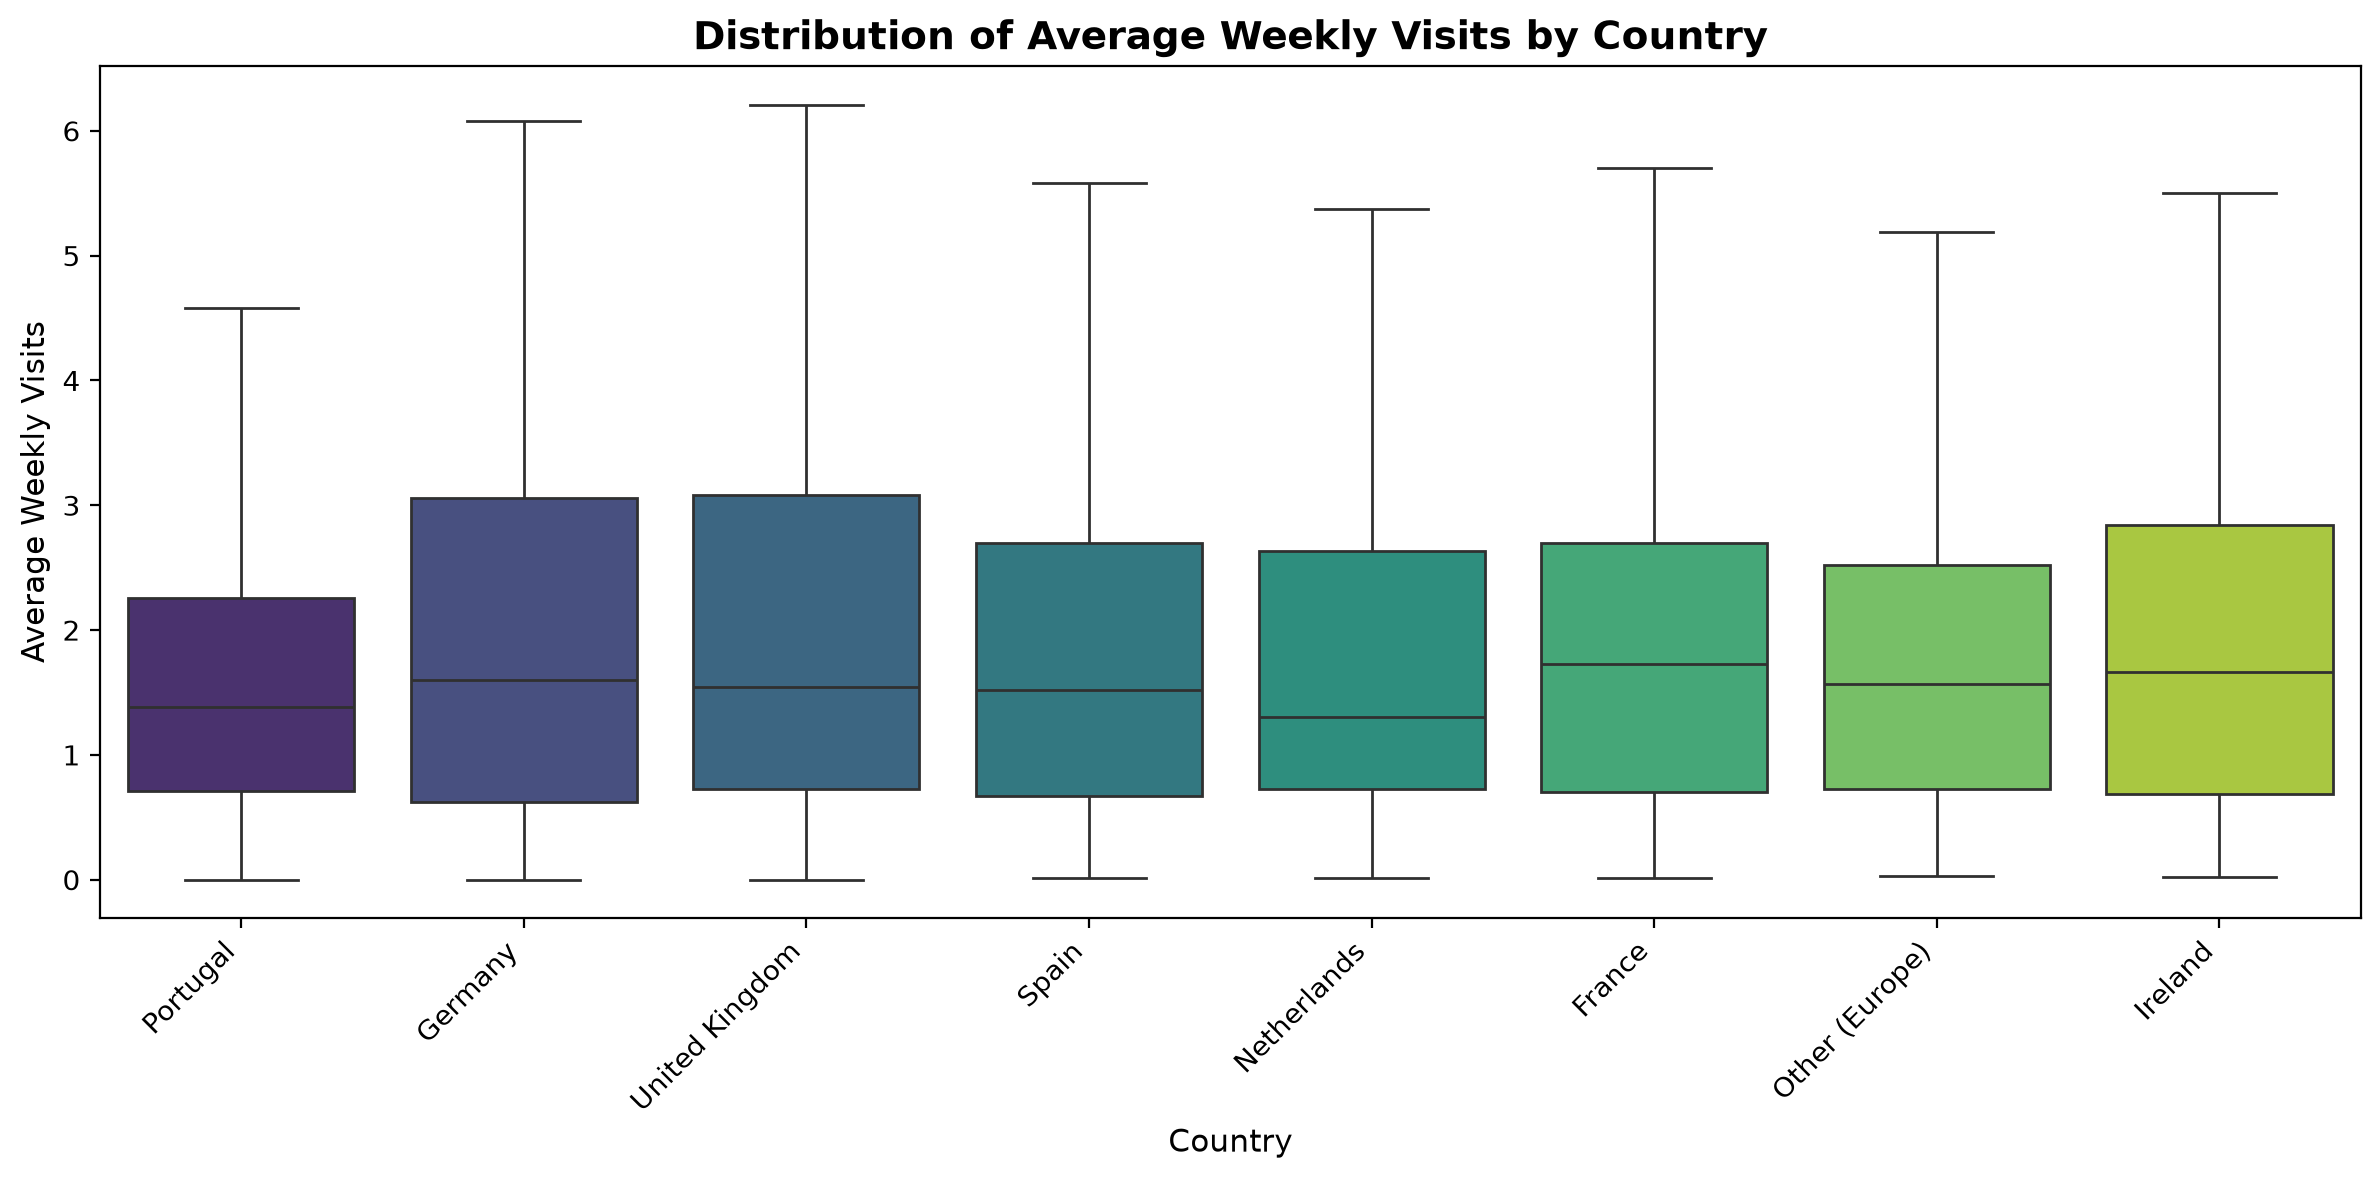

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns


plt.figure(figsize=(12, 6))

sns.boxplot(
    data=acdc_cleaned, 
    x="clean_country", 
    y="avg_weekly_visits", 
    palette="viridis",
    hue="clean_country",  
    legend=False,
    showfliers=False
)

plt.title("Distribution of Average Weekly Visits by Country", fontsize=14, fontweight="bold")
plt.xlabel("Country", fontsize=11)
plt.ylabel("Average Weekly Visits", fontsize=11)
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

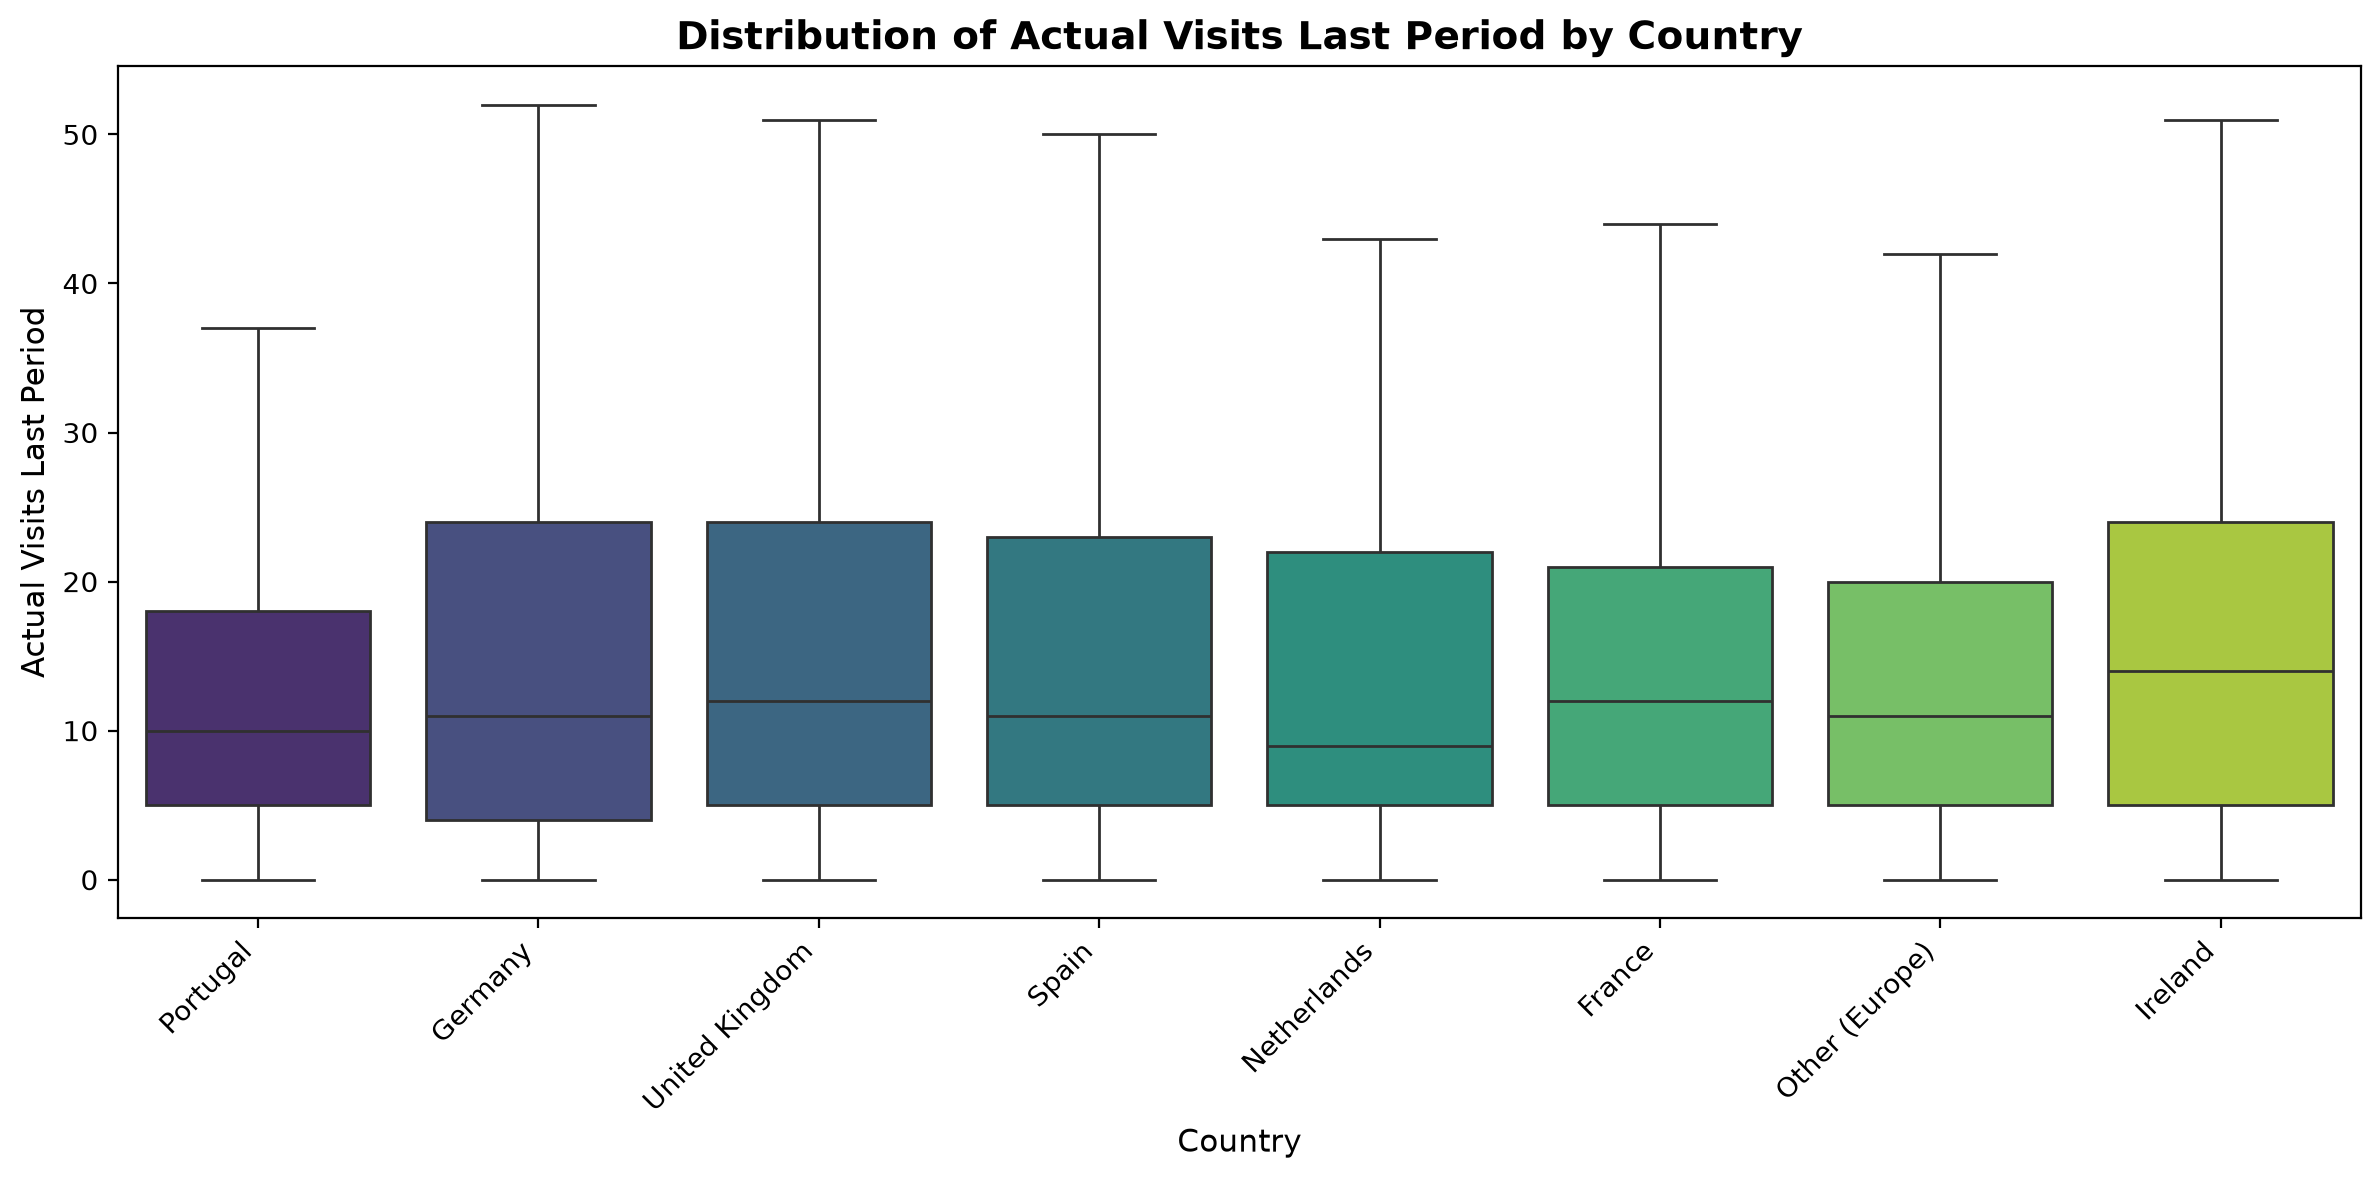

In [26]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=acdc_cleaned, 
    x="clean_country", 
    y="actual_visits_last_period", 
    palette="viridis",
    hue="clean_country",  
    legend=False,
    showfliers=False
)

plt.title("Distribution of Actual Visits Last Period by Country", fontsize=14, fontweight="bold")
plt.xlabel("Country", fontsize=11)
plt.ylabel("Actual Visits Last Period", fontsize=11)
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [27]:
plan_tier_mapping = {
    # Flex variants
    "flex": "Flex",
    "Flex": "Flex",
    "FLEX": "Flex",
    
    # Hot Desk variants
    "hot_desk": "Hot Desk",
    "HOT_DESK": "Hot Desk",
    "Hot Desk": "Hot Desk",
    "hotdesk": "Hot Desk",
    
    # Full Time variants
    "full_time": "Full Time",
    "FULL_TIME": "Full Time",
    "Full Time": "Full Time",
    "fulltime": "Full Time",
    
    # Dedicated Desk variants
    "dedicated_desk": "Dedicated Desk",
    "DEDICATED_DESK": "Dedicated Desk",
    "Dedicated Desk": "Dedicated Desk",
    "dedicateddesk": "Dedicated Desk",
    
    # Private Office variants
    "private_office": "Private Office",
    "PRIVATE_OFFICE": "Private Office",
    "Private Office": "Private Office",
    "privateoffice": "Private Office"
}
acdc_cleaned["clean_plan_tier"] = acdc["plan_tier"].astype(str).str.strip().map(plan_tier_mapping).fillna(acdc["plan_tier"].astype(str).str.title())

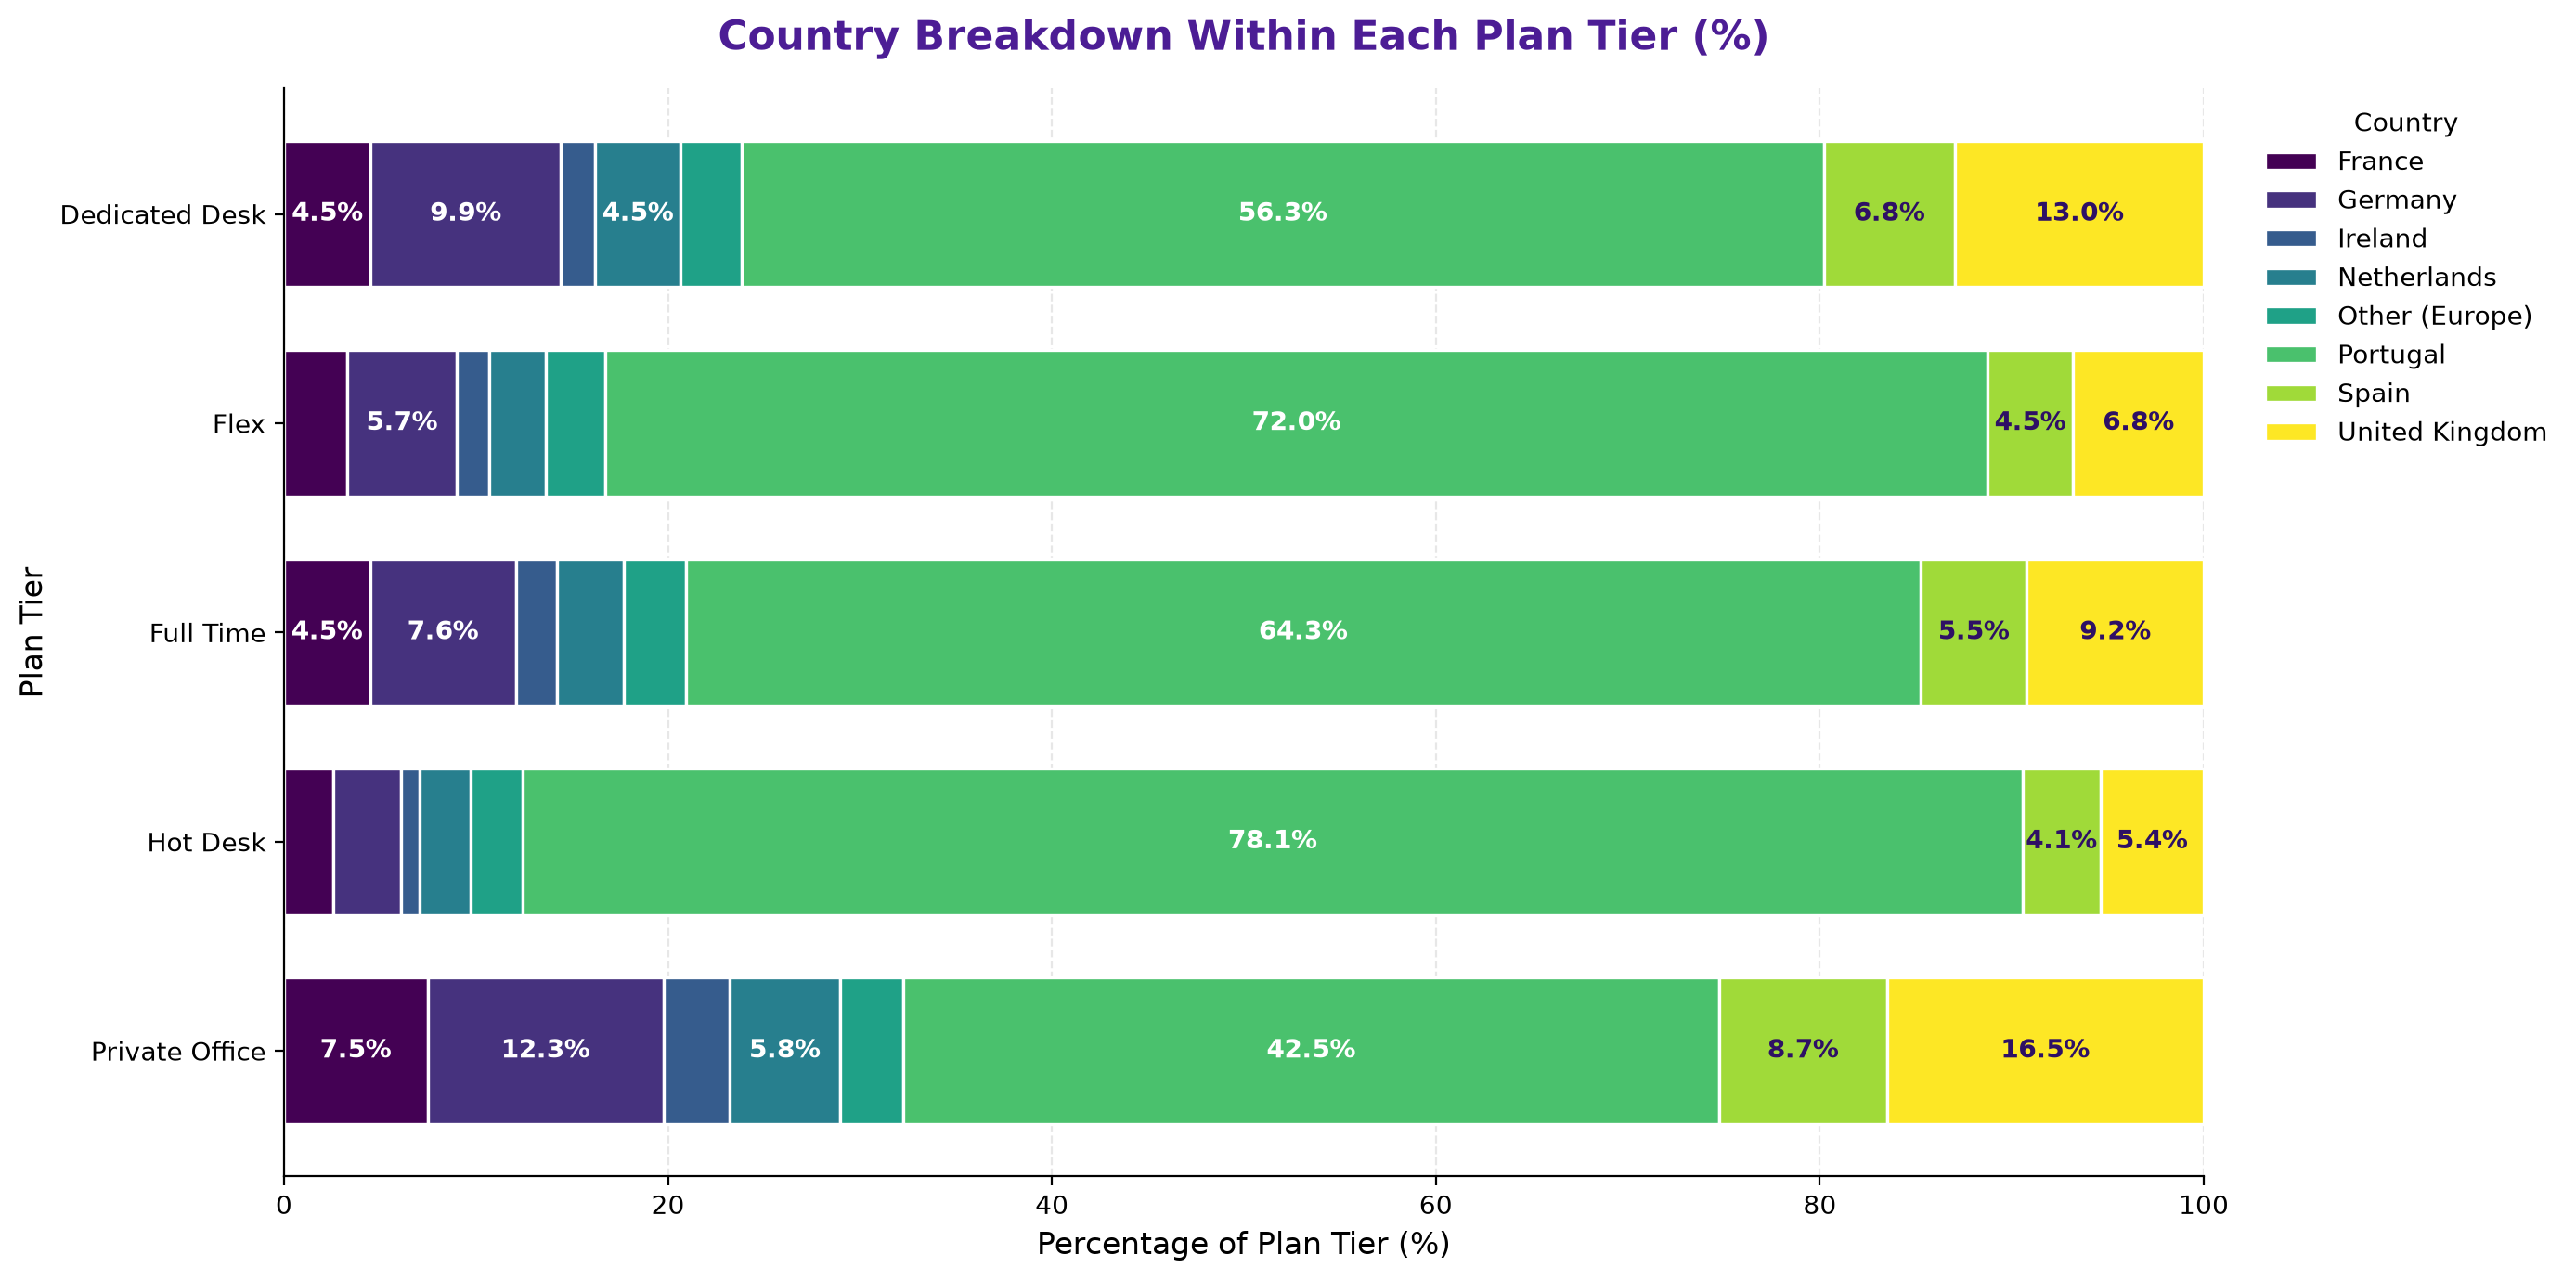

In [28]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import pandas as pd

# 1. Filter out missing values AND the text string "nan" / "Nan"
valid_data = acdc_cleaned.dropna(subset=["clean_country", "clean_plan_tier"])
valid_data = valid_data[
    (~valid_data["clean_country"].astype(str).str.lower().isin(["nan", "none", "nat"])) &
    (~valid_data["clean_plan_tier"].astype(str).str.lower().isin(["nan", "none", "nat"]))
]

# 2. Crosstab using the cleanly filtered data
cross_tab = pd.crosstab(
    valid_data["clean_plan_tier"],
    valid_data["clean_country"],
    normalize="index"
) * 100

# 3. Pink -> purple palette sampled to match the number of countries
n = cross_tab.shape[1]
cmap = plt.get_cmap("viridis")
palette = [cmap(i / max(n - 1, 1)) for i in range(n)]

# 4. Horizontal 100% stacked bar chart
ax = cross_tab.plot(
    kind="barh",
    stacked=True,
    figsize=(14, 7),
    color=palette,
    edgecolor="white",
    linewidth=1.2,
    width=0.7,
)

# 5. Percentage labels, with text color chosen for contrast against each segment
def text_color(rgba):
    r, g, b = rgba[:3]
    luminance = 0.299 * r + 0.587 * g + 0.114 * b
    return "#2E1065" if luminance > 0.6 else "white"

for c, col in zip(ax.containers, palette):
    labels = [f"{v:.1f}%" if v > 4 else "" for v in c.datavalues]
    ax.bar_label(
        c, 
        labels=labels, 
        label_type="center", 
        fontsize=10, 
        fontweight="bold", 
        color=text_color(col)
    )

# 6. Formatting
ax.set_title("Country Breakdown Within Each Plan Tier (%)", fontsize=16, fontweight="bold", color="#4C1D95", pad=15)
ax.set_xlabel("Percentage of Plan Tier (%)", fontsize=12)
ax.set_ylabel("Plan Tier", fontsize=12)
ax.set_xlim(0, 100)
ax.invert_yaxis()  # first plan tier at the top
ax.xaxis.grid(True, linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
    
ax.legend(title="Country", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

### Industry Segmentation

In [29]:
industry_mapping = {
    "information technology": "Information Technology",
    "Information technology": "Information Technology",
    "INFORMATION TECHNOLOGY": "Information Technology",
    "Information Technology": "Information Technology",
    "IT": "Information Technology",
    "Tech": "Information Technology",
    
    "consulting": "Consulting",
    "Consulting": "Consulting",
    "CONSULTING": "Consulting",
    
    "marketing & pr": "Marketing & PR",
    "Marketing & PR": "Marketing & PR",
    "MARKETING & PR": "Marketing & PR",
    "marketing & pr": "Marketing & PR",
    "Marketing & Pr": "Marketing & PR",
    "Marketing and PR": "Marketing & PR", 
    "Marketing/PR": "Marketing & PR",
    
    "design & creative": "Design & Creative",
    "Design & Creative": "Design & Creative",
    "DESIGN & CREATIVE": "Design & Creative",
    "Design/Creative": "Design & Creative",
    "Design and Creative": "Design & Creative",
    
    "finance": "Finance",
    "Finance": "Finance",
    "FINANCE": "Finance",
    
    "legal": "Legal",
    "Legal": "Legal",
    "LEGAL": "Legal",
    
    "education": "Education",
    "Education": "Education",
    "EDUCATION": "Education",
    
    "health": "Health",
    "Health": "Health",
    "HEALTH": "Health",
    
    "real estate": "Real Estate",
    "Real Estate": "Real Estate",
    "REAL ESTATE": "Real Estate",
    "RealEstate": "Real Estate",
    "Real-Estate": "Real Estate",
    
    "other": "Other",
    "Other": "Other",
    "OTHER": "Other",
    
    "unknown": "Unknown",
    "Unknown": "Unknown",
    "UNKNOWN": "Unknown"
}

acdc_cleaned["clean_industry"] = (
    acdc["industry"]
    .astype(str)
    .str.strip()
    .map(industry_mapping)
    .fillna(acdc["industry"].astype(str).str.title())
)
acdc_cleaned = acdc_cleaned[acdc_cleaned["clean_industry"] != "Unknown"]

Most customers are are in the Information Technology industry.

In [30]:
display(acdc_cleaned["clean_industry"].value_counts(dropna=False))

clean_industry
Information Technology    3557
Consulting                2055
Design & Creative         1974
Marketing & PR            1962
Finance                   1219
Other                     1175
Legal                      878
Education                  775
Health                     601
Real Estate                561
Name: count, dtype: int64

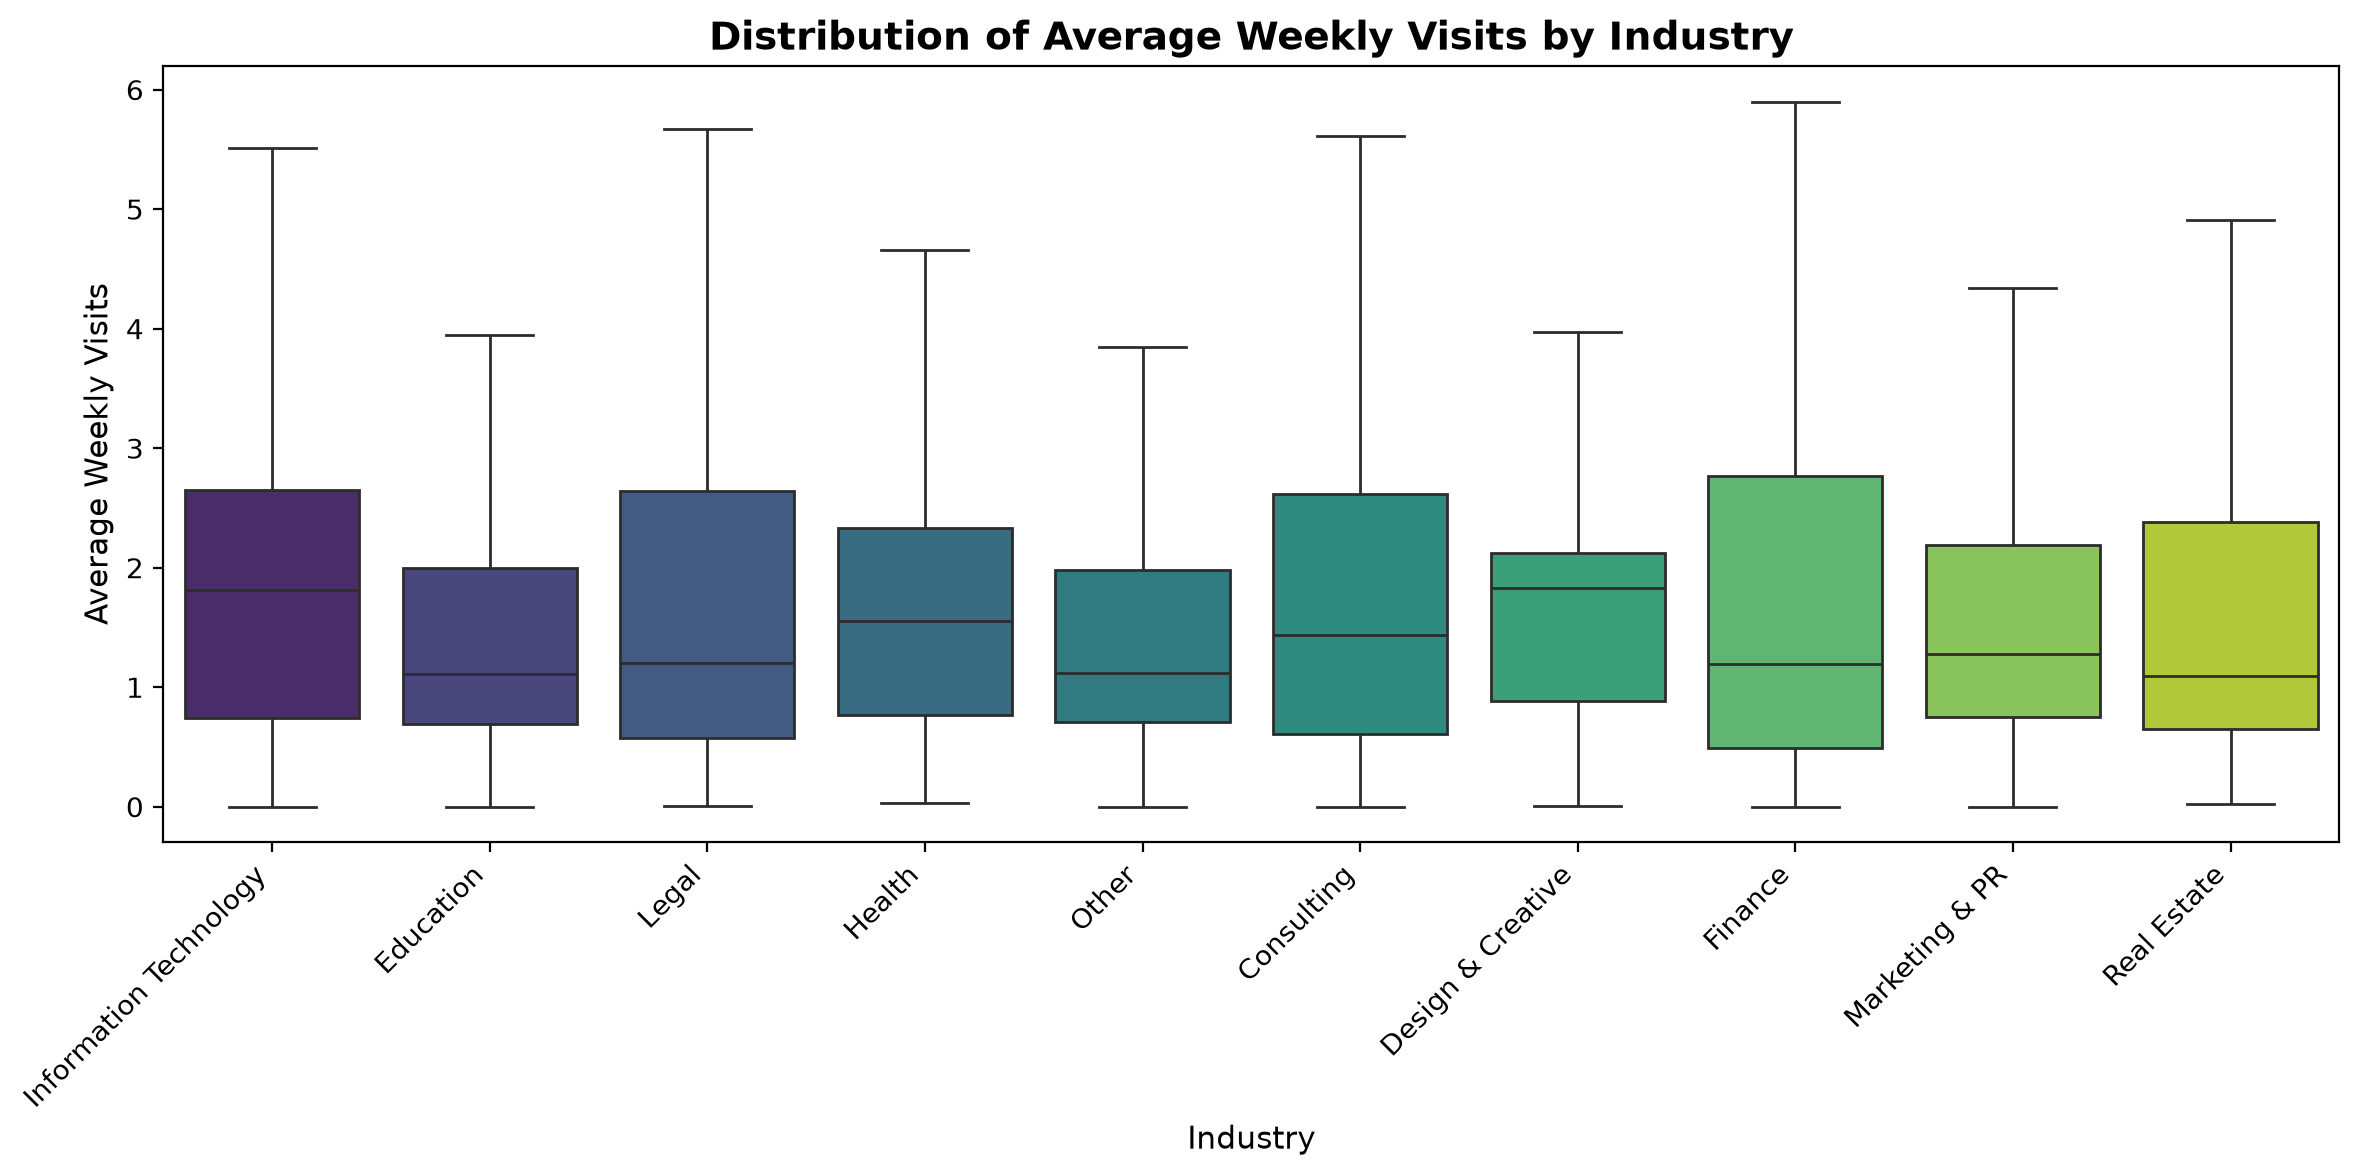

In [31]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=acdc_cleaned, 
    x="clean_industry", 
    y="avg_weekly_visits", 
    palette="viridis",
    hue="clean_industry",  
    legend=False,
    showfliers=False
)

plt.title("Distribution of Average Weekly Visits by Industry", fontsize=14, fontweight="bold")
plt.xlabel("Industry", fontsize=11)
plt.ylabel("Average Weekly Visits", fontsize=11)
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

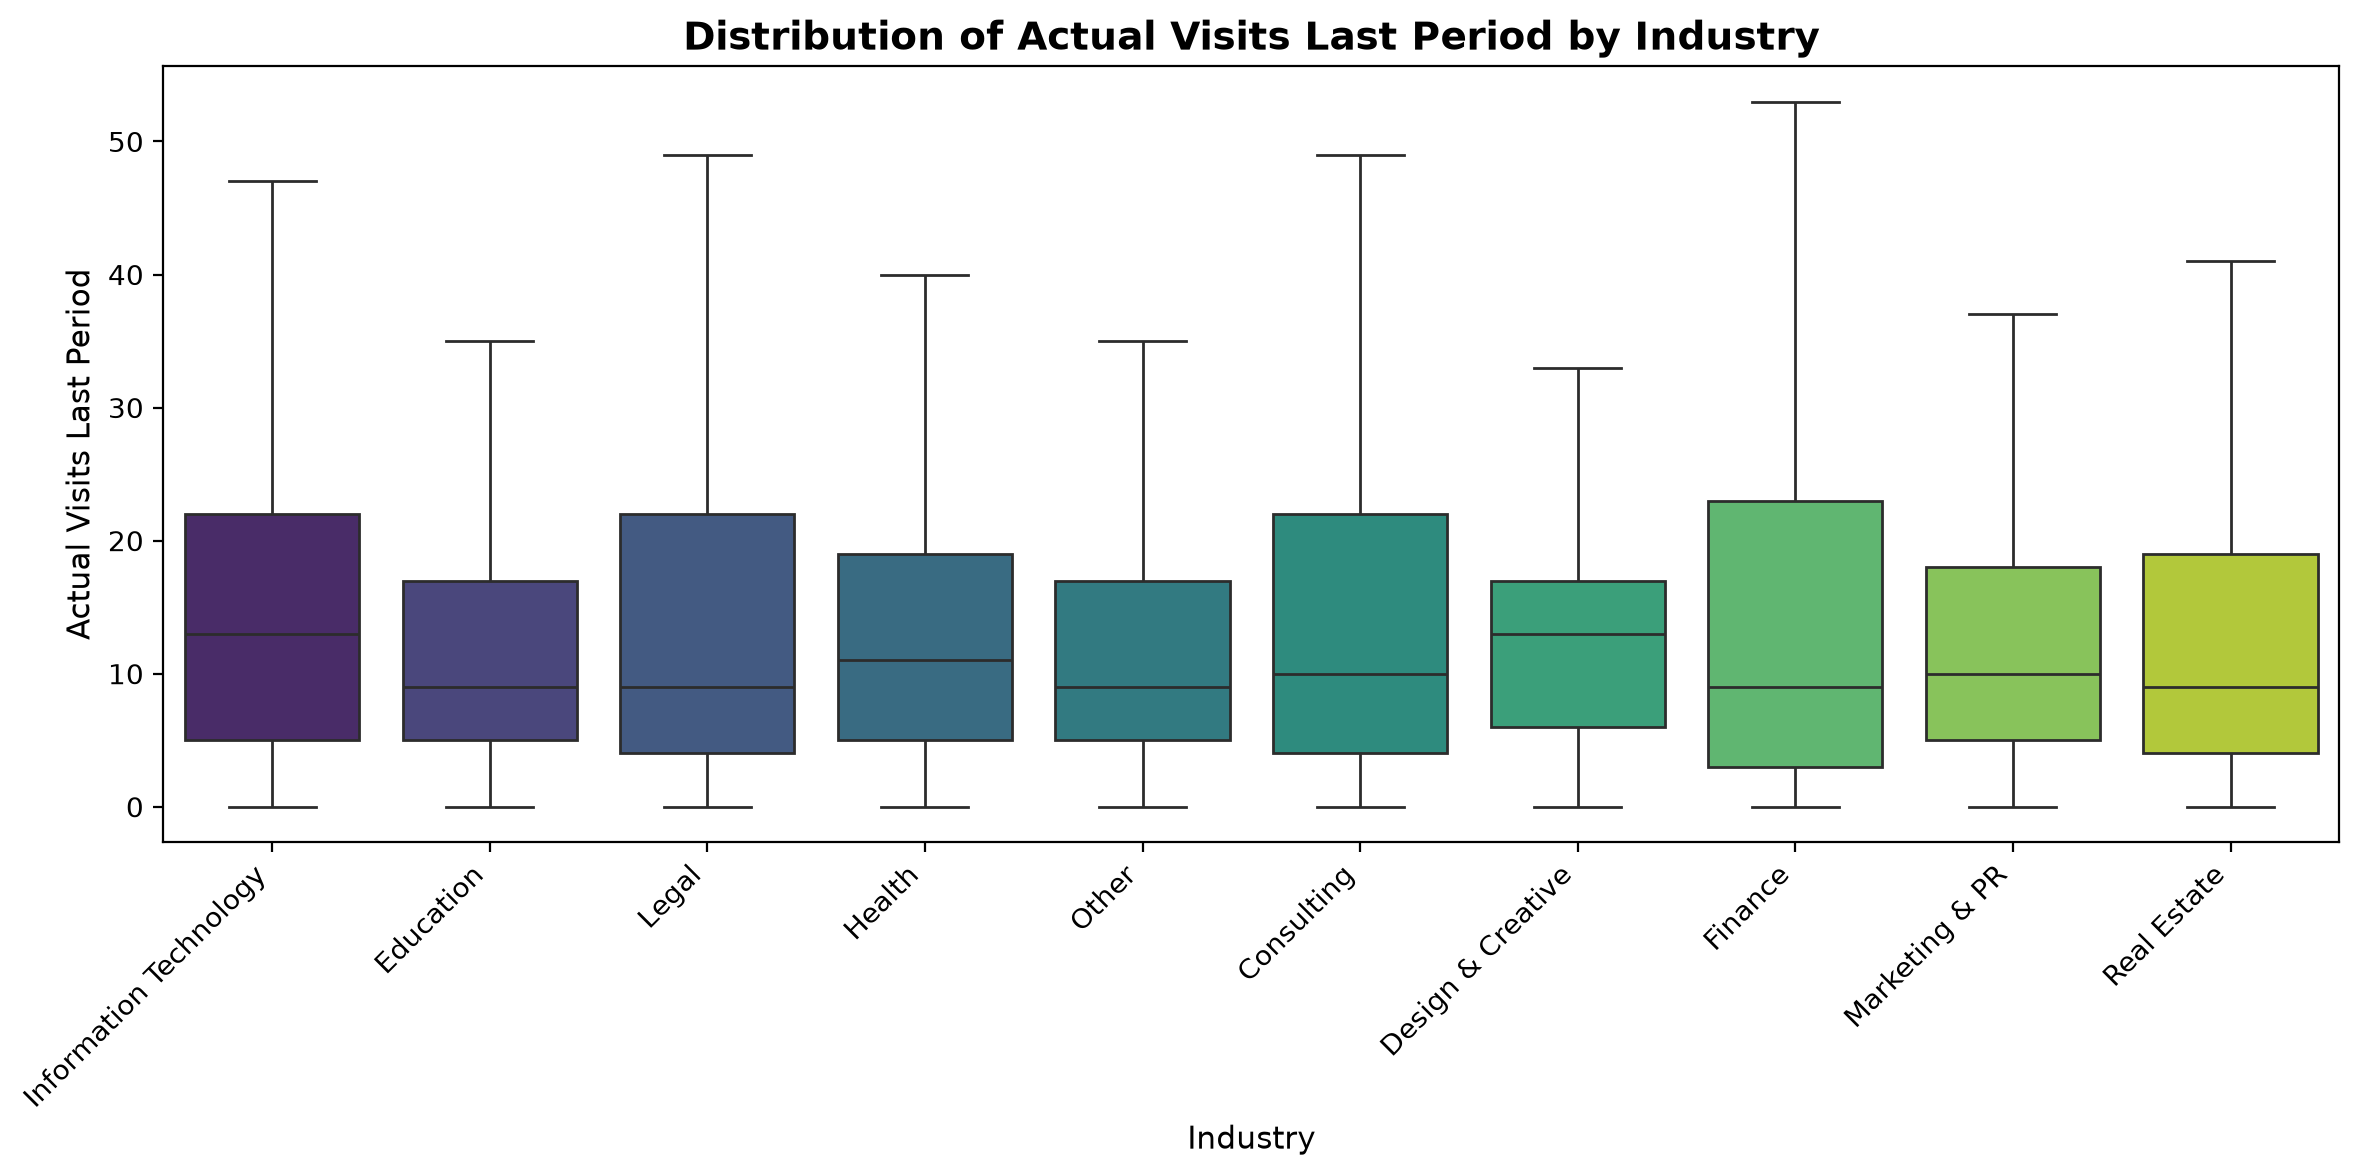

In [32]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=acdc_cleaned, 
    x="clean_industry", 
    y="actual_visits_last_period", 
    palette="viridis",
    hue="clean_industry",  
    legend=False,
    showfliers=False
)

plt.title("Distribution of Actual Visits Last Period by Industry", fontsize=14, fontweight="bold")
plt.xlabel("Industry", fontsize=11)
plt.ylabel("Actual Visits Last Period", fontsize=11)
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

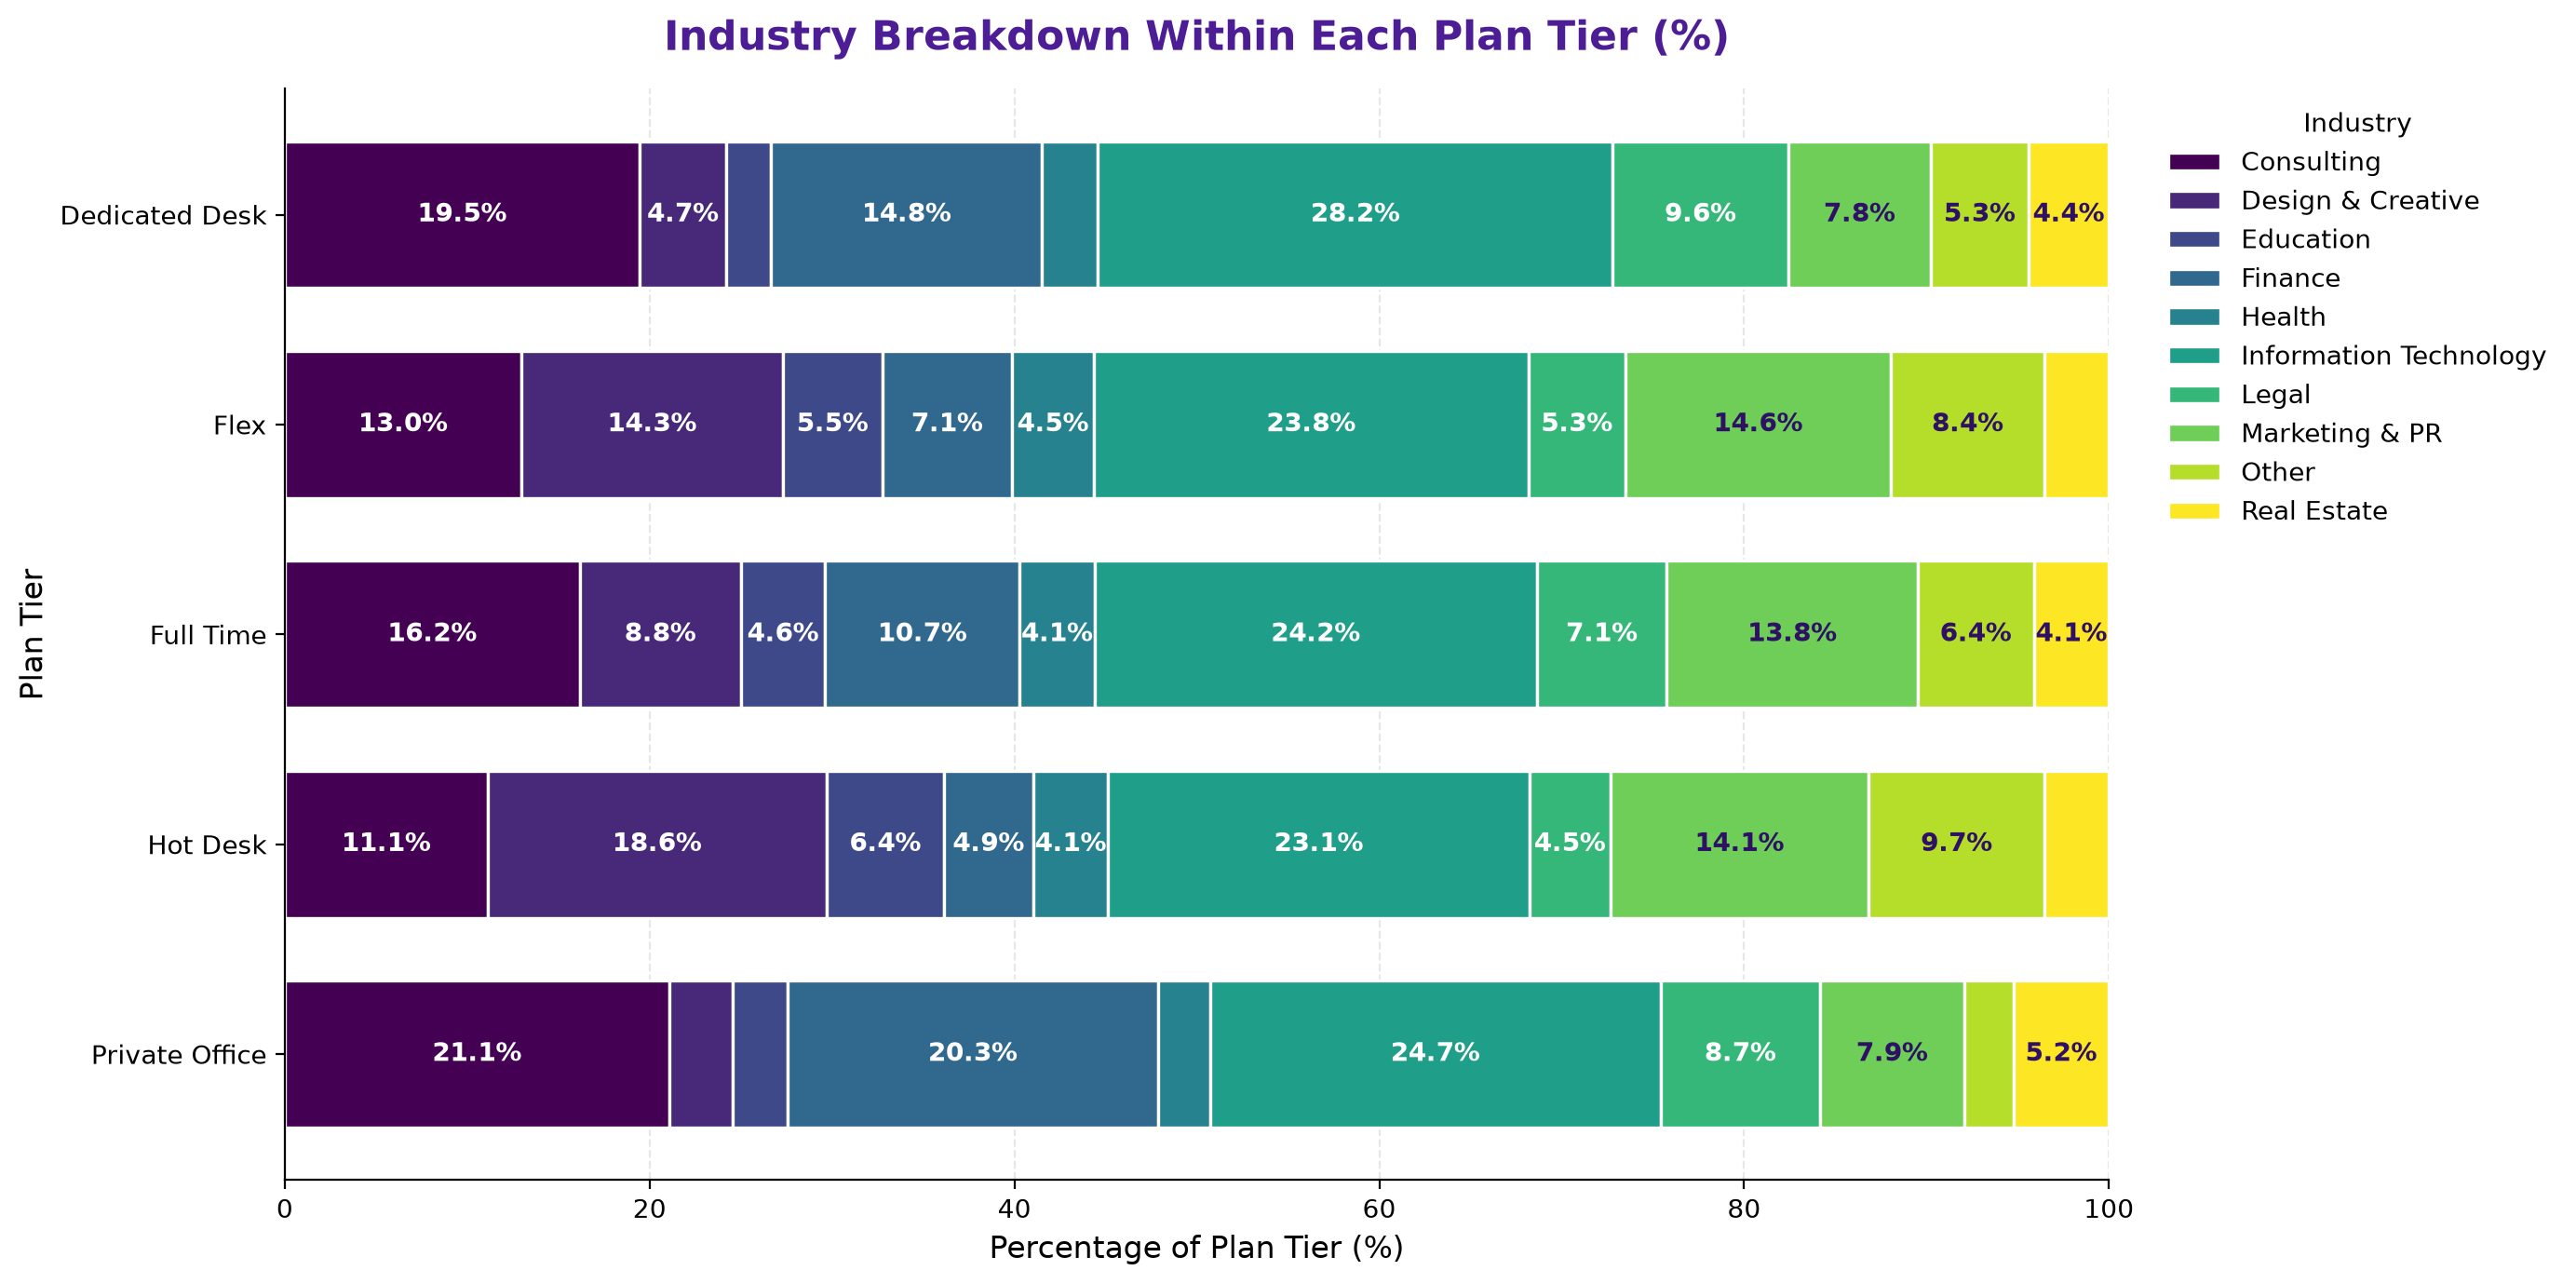

In [33]:
valid_data = acdc_cleaned.dropna(subset=["clean_industry", "clean_plan_tier"])
valid_data = valid_data[
    (~valid_data["clean_industry"].astype(str).str.lower().isin(["nan", "none", "nat"])) &
    (~valid_data["clean_plan_tier"].astype(str).str.lower().isin(["nan", "none", "nat"]))
]

cross_tab = pd.crosstab(
    valid_data["clean_plan_tier"],
    valid_data["clean_industry"],
    normalize="index"
) * 100

n = cross_tab.shape[1]
cmap = plt.get_cmap("viridis")
palette = [cmap(i / max(n - 1, 1)) for i in range(n)]

ax = cross_tab.plot(
    kind="barh",
    stacked=True,
    figsize=(14, 7),
    color=palette,
    edgecolor="white",
    linewidth=1.2,
    width=0.7,
)

def text_color(rgba):
    r, g, b = rgba[:3]
    luminance = 0.299 * r + 0.587 * g + 0.114 * b
    return "#2E1065" if luminance > 0.6 else "white"

for c, col in zip(ax.containers, palette):
    labels = [f"{v:.1f}%" if v > 4 else "" for v in c.datavalues]
    ax.bar_label(
        c, 
        labels=labels, 
        label_type="center", 
        fontsize=10, 
        fontweight="bold", 
        color=text_color(col)
    )

ax.set_title("Industry Breakdown Within Each Plan Tier (%)", fontsize=16, fontweight="bold", color="#4C1D95", pad=15)
ax.set_xlabel("Percentage of Plan Tier (%)", fontsize=12)
ax.set_ylabel("Plan Tier", fontsize=12)
ax.set_xlim(0, 100)
ax.invert_yaxis() 
ax.xaxis.grid(True, linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
    
ax.legend(title="Industry", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

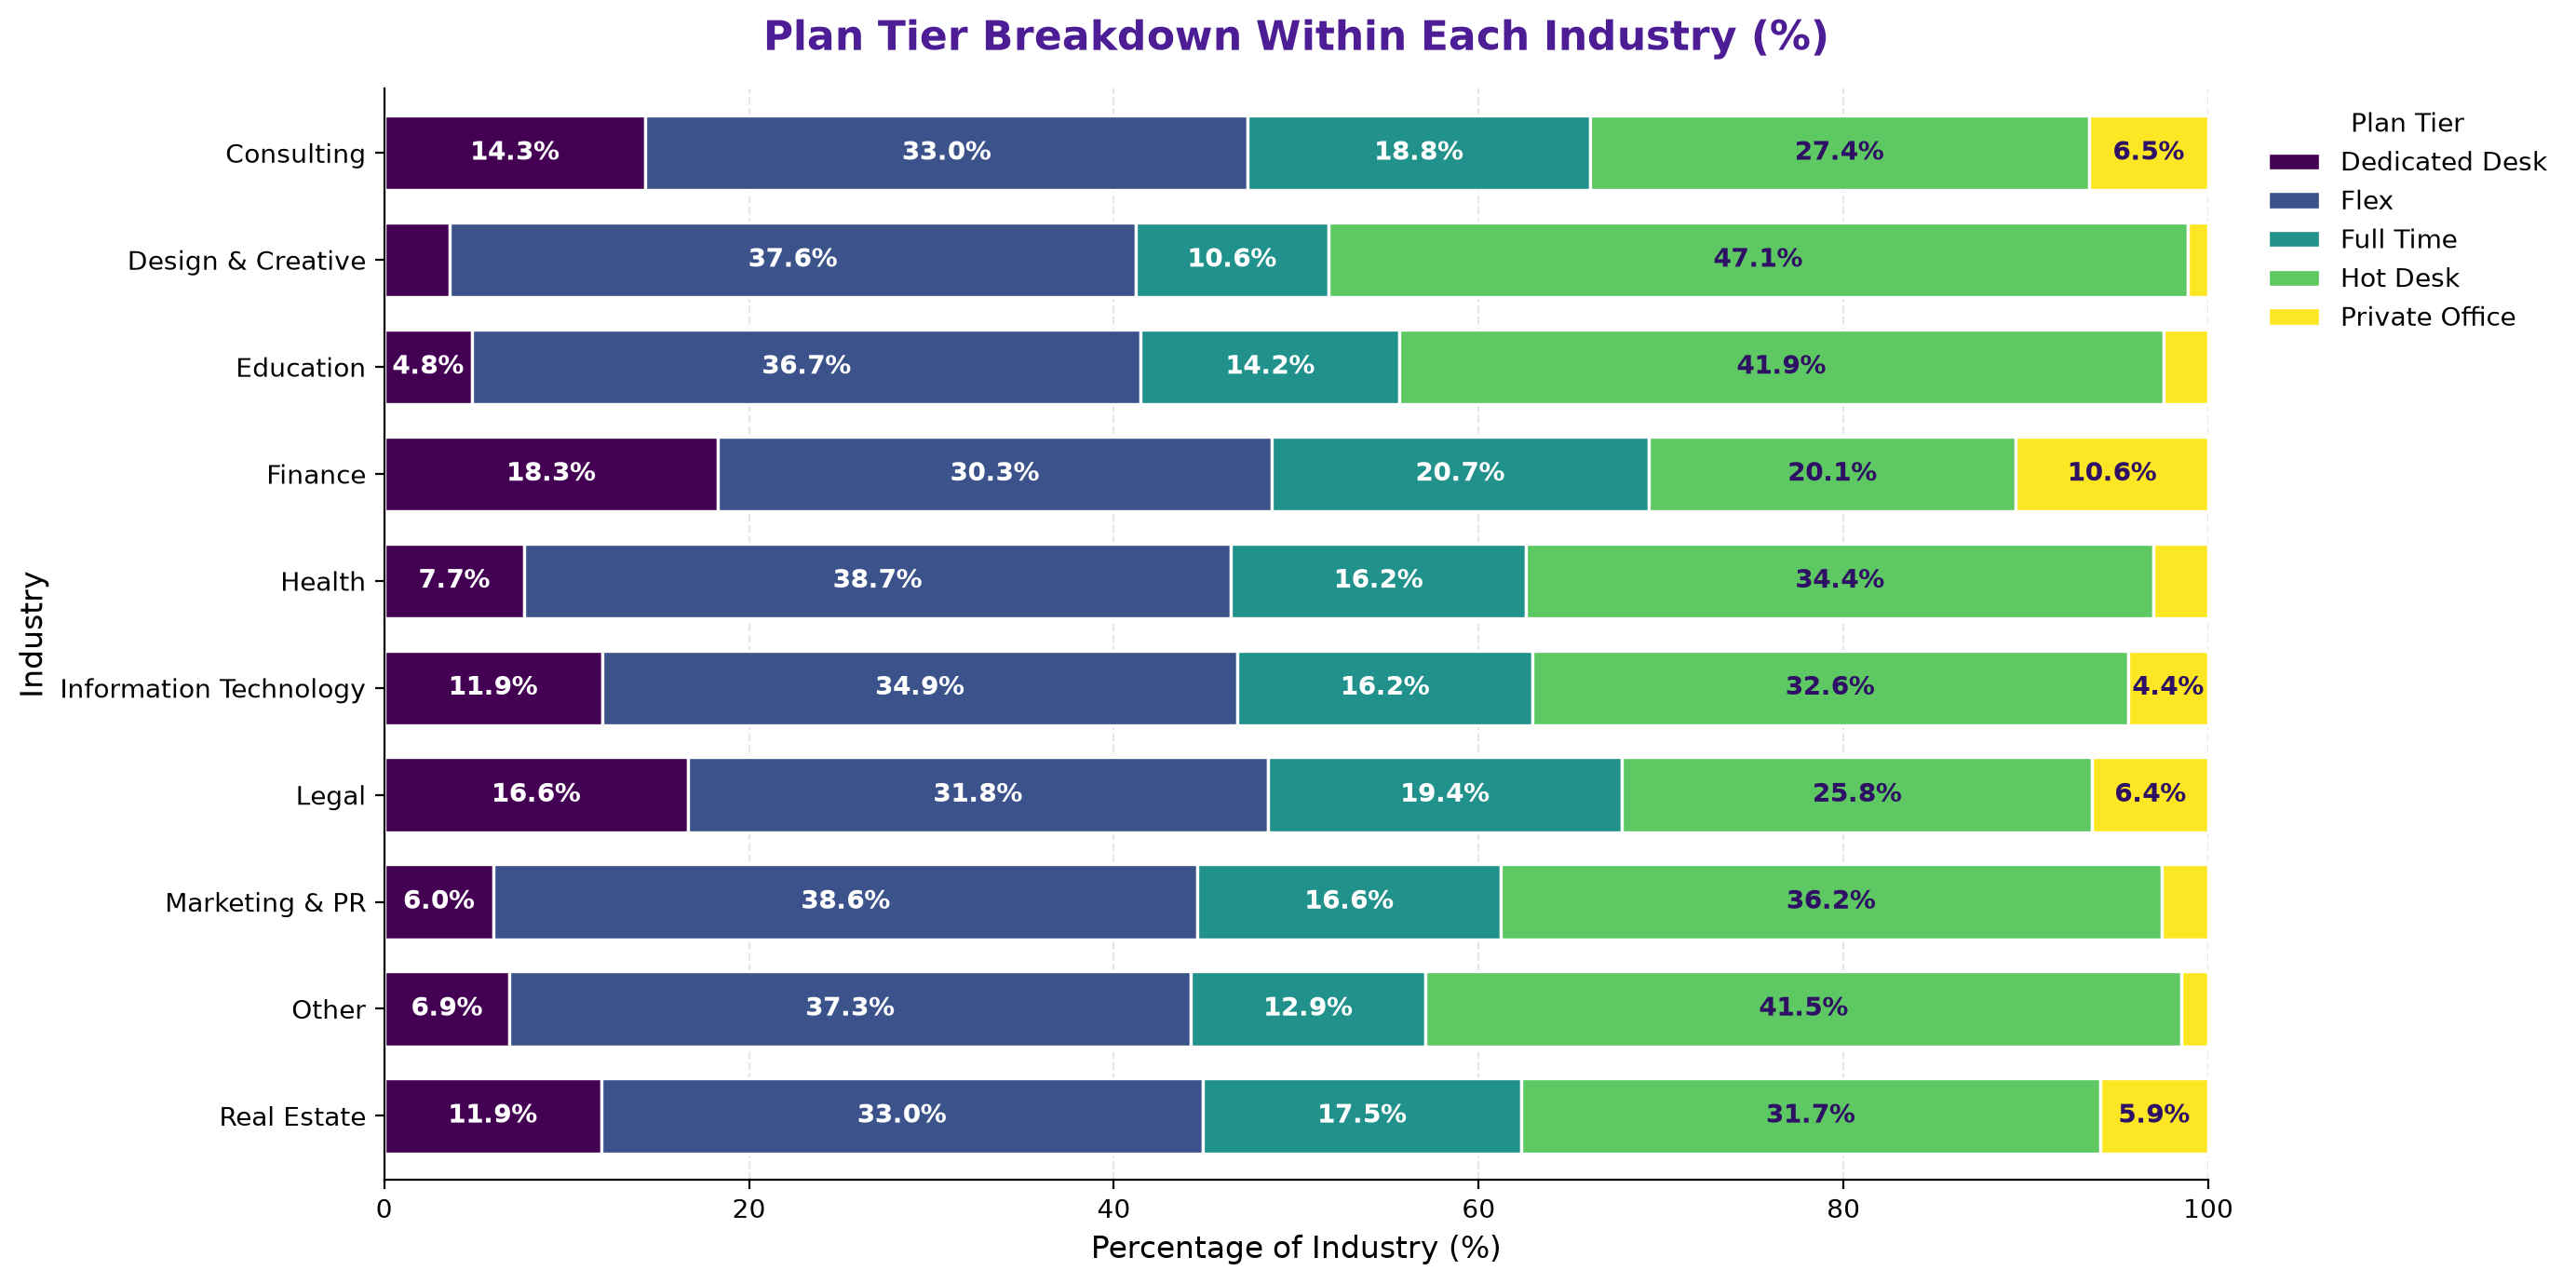

In [34]:
cross_tab = pd.crosstab(
    valid_data["clean_industry"],  
    valid_data["clean_plan_tier"], 
    normalize="index"             
) * 100

n = cross_tab.shape[1]
cmap = plt.get_cmap("viridis")
palette = [cmap(i / max(n - 1, 1)) for i in range(n)]

ax = cross_tab.plot(
    kind="barh",
    stacked=True,
    figsize=(14, 7),
    color=palette,
    edgecolor="white",
    linewidth=1.2,
    width=0.7,
)

def text_color(rgba):
    r, g, b = rgba[:3]
    luminance = 0.299 * r + 0.587 * g + 0.114 * b
    return "#2E1065" if luminance > 0.6 else "white"

for c, col in zip(ax.containers, palette):
    labels = [f"{v:.1f}%" if v > 4 else "" for v in c.datavalues]
    ax.bar_label(
        c, 
        labels=labels, 
        label_type="center", 
        fontsize=10, 
        fontweight="bold", 
        color=text_color(col)
    )

ax.set_title("Plan Tier Breakdown Within Each Industry (%)", fontsize=16, fontweight="bold", color="#4C1D95", pad=15)
ax.set_xlabel("Percentage of Industry (%)", fontsize=12)
ax.set_ylabel("Industry", fontsize=12)
ax.set_xlim(0, 100)
ax.invert_yaxis() 
ax.xaxis.grid(True, linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
    
ax.legend(title="Plan Tier", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

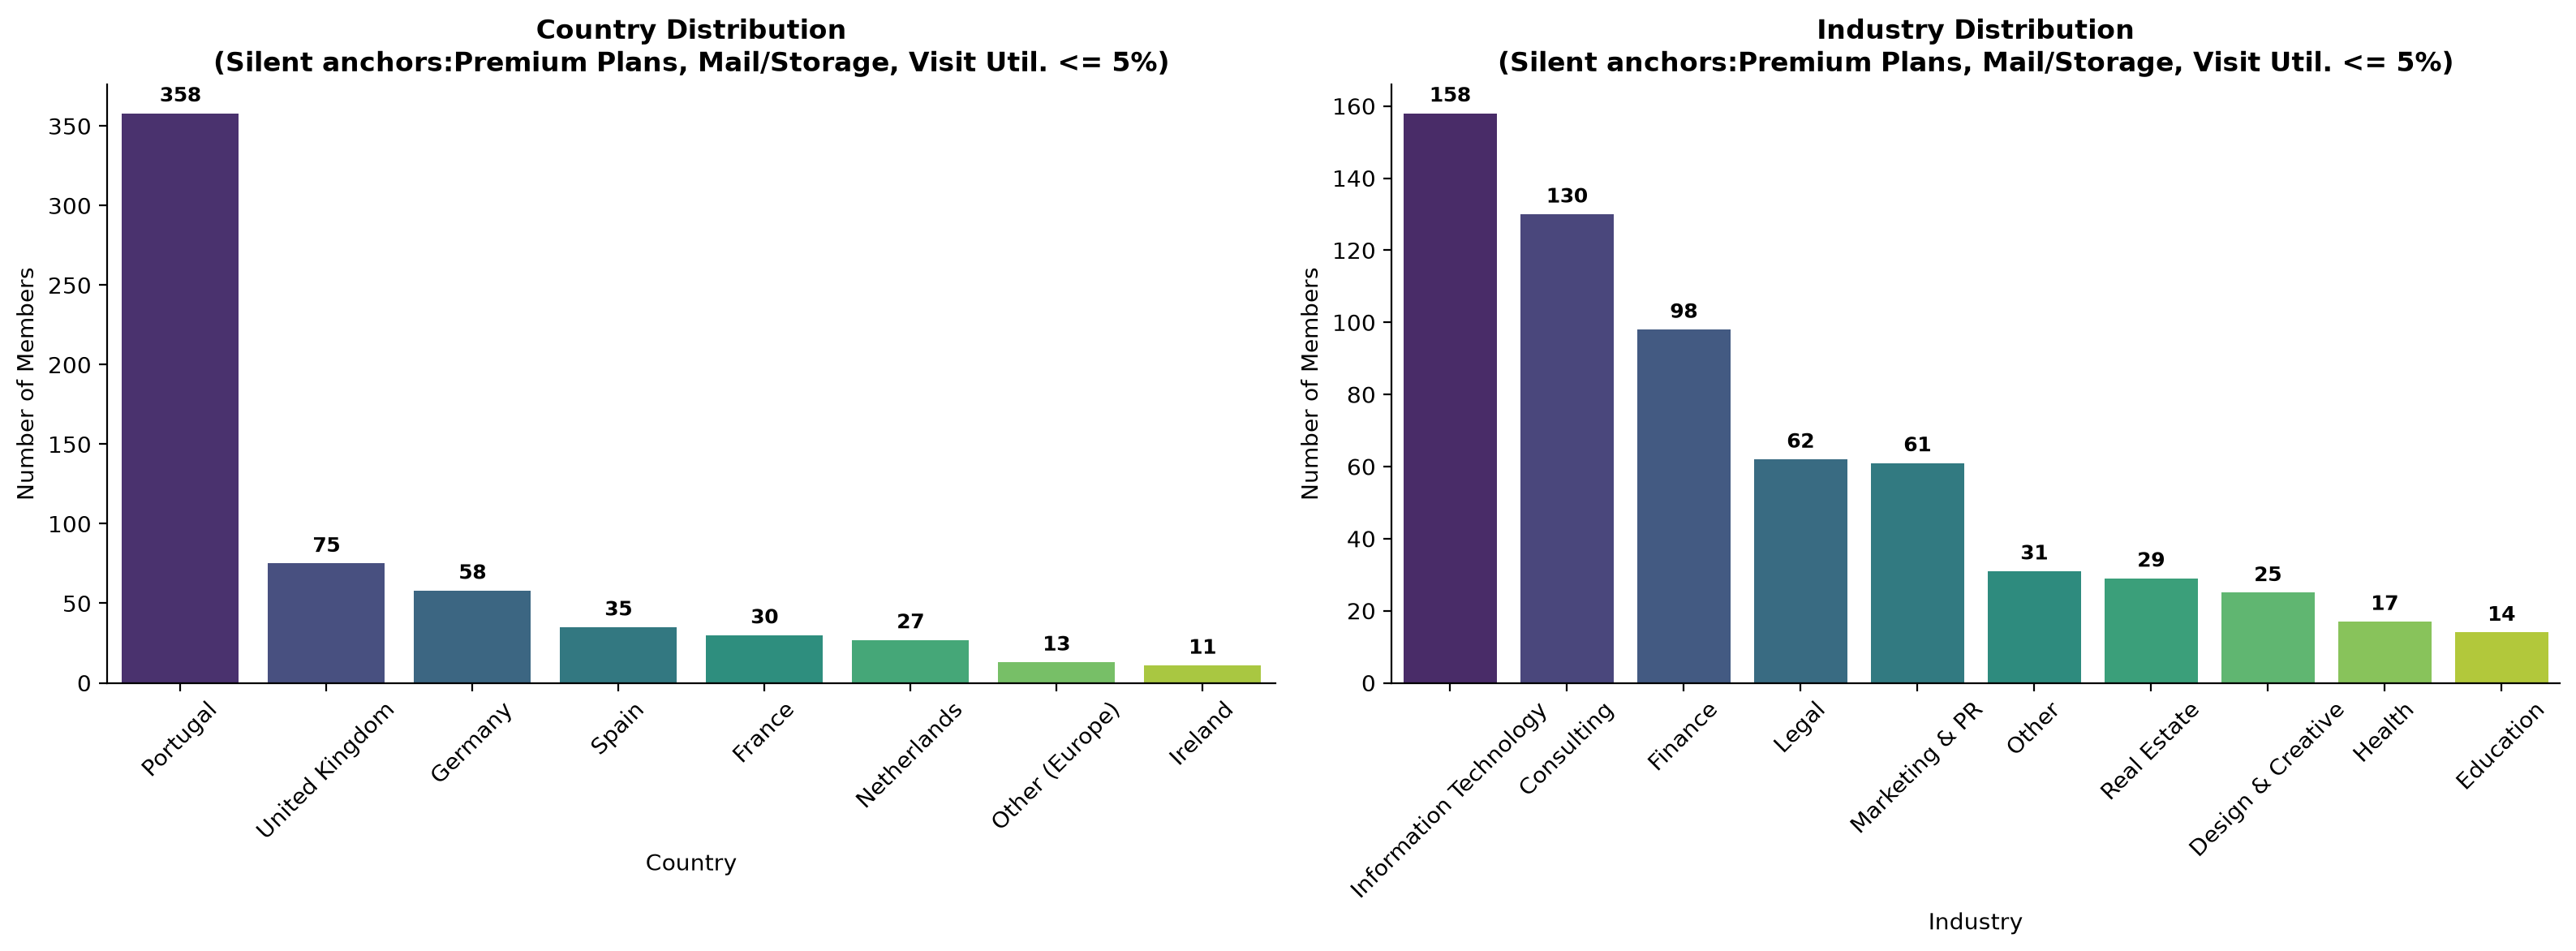

In [35]:
acdc_cohort2 = acdc_cleaned.copy()

if "visit_utilization" not in acdc_cohort2.columns:
    acdc_cohort2["visit_utilization"] = (
        acdc_cohort2["actual_visits_last_period"] / 
        acdc_cohort2["entitled_visits_last_period"].replace(0, np.nan)
    )


premium_tiers = ["Full Time", "Dedicated Desk", "Private Office"]
cond_tier_p2 = acdc_cohort2["clean_plan_tier"].isin(premium_tiers)

cond_services_p2 = (acdc_cohort2["uses_mail_handling"] == True) | (acdc_cohort2["uses_storage"] == True)

cond_utilization_p2 = acdc_cohort2["visit_utilization"] <= 0.05

cohort_members = acdc_cohort2[cond_tier_p2 & cond_services_p2 & cond_utilization_p2]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

country_counts_p2 = cohort_members["clean_country"].value_counts().reset_index()
country_counts_p2.columns = ["country", "count"]

ax1 = sns.barplot(
    data=country_counts_p2, 
    x="country", 
    y="count", 
    palette="viridis",
    hue="country",
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Country Distribution\n(Silent anchors:Premium Plans, Mail/Storage, Visit Util. <= 5%)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Country", fontsize=10)
axes[0].set_ylabel("Number of Members", fontsize=10)
axes[0].tick_params(axis='x', rotation=45)

for p in ax1.patches:
    height = p.get_height()
    if height > 0:
        ax1.annotate(f'{int(height)}',
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', 
                     fontsize=9, fontweight='bold',
                     xytext=(0, 3), textcoords='offset points')

industry_counts_p2 = cohort_members["clean_industry"].value_counts().reset_index()
industry_counts_p2.columns = ["industry", "count"]

ax2 = sns.barplot(
    data=industry_counts_p2, 
    x="industry", 
    y="count", 
    palette="viridis",
    hue="industry",
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Industry Distribution\n(Silent anchors:Premium Plans, Mail/Storage, Visit Util. <= 5%)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Industry", fontsize=10)
axes[1].set_ylabel("Number of Members", fontsize=10)
axes[1].tick_params(axis='x', rotation=45)

for p in ax2.patches:
    height = p.get_height()
    if height > 0:
        ax2.annotate(f'{int(height)}',
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', 
                     fontsize=9, fontweight='bold',
                     xytext=(0, 3), textcoords='offset points')

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

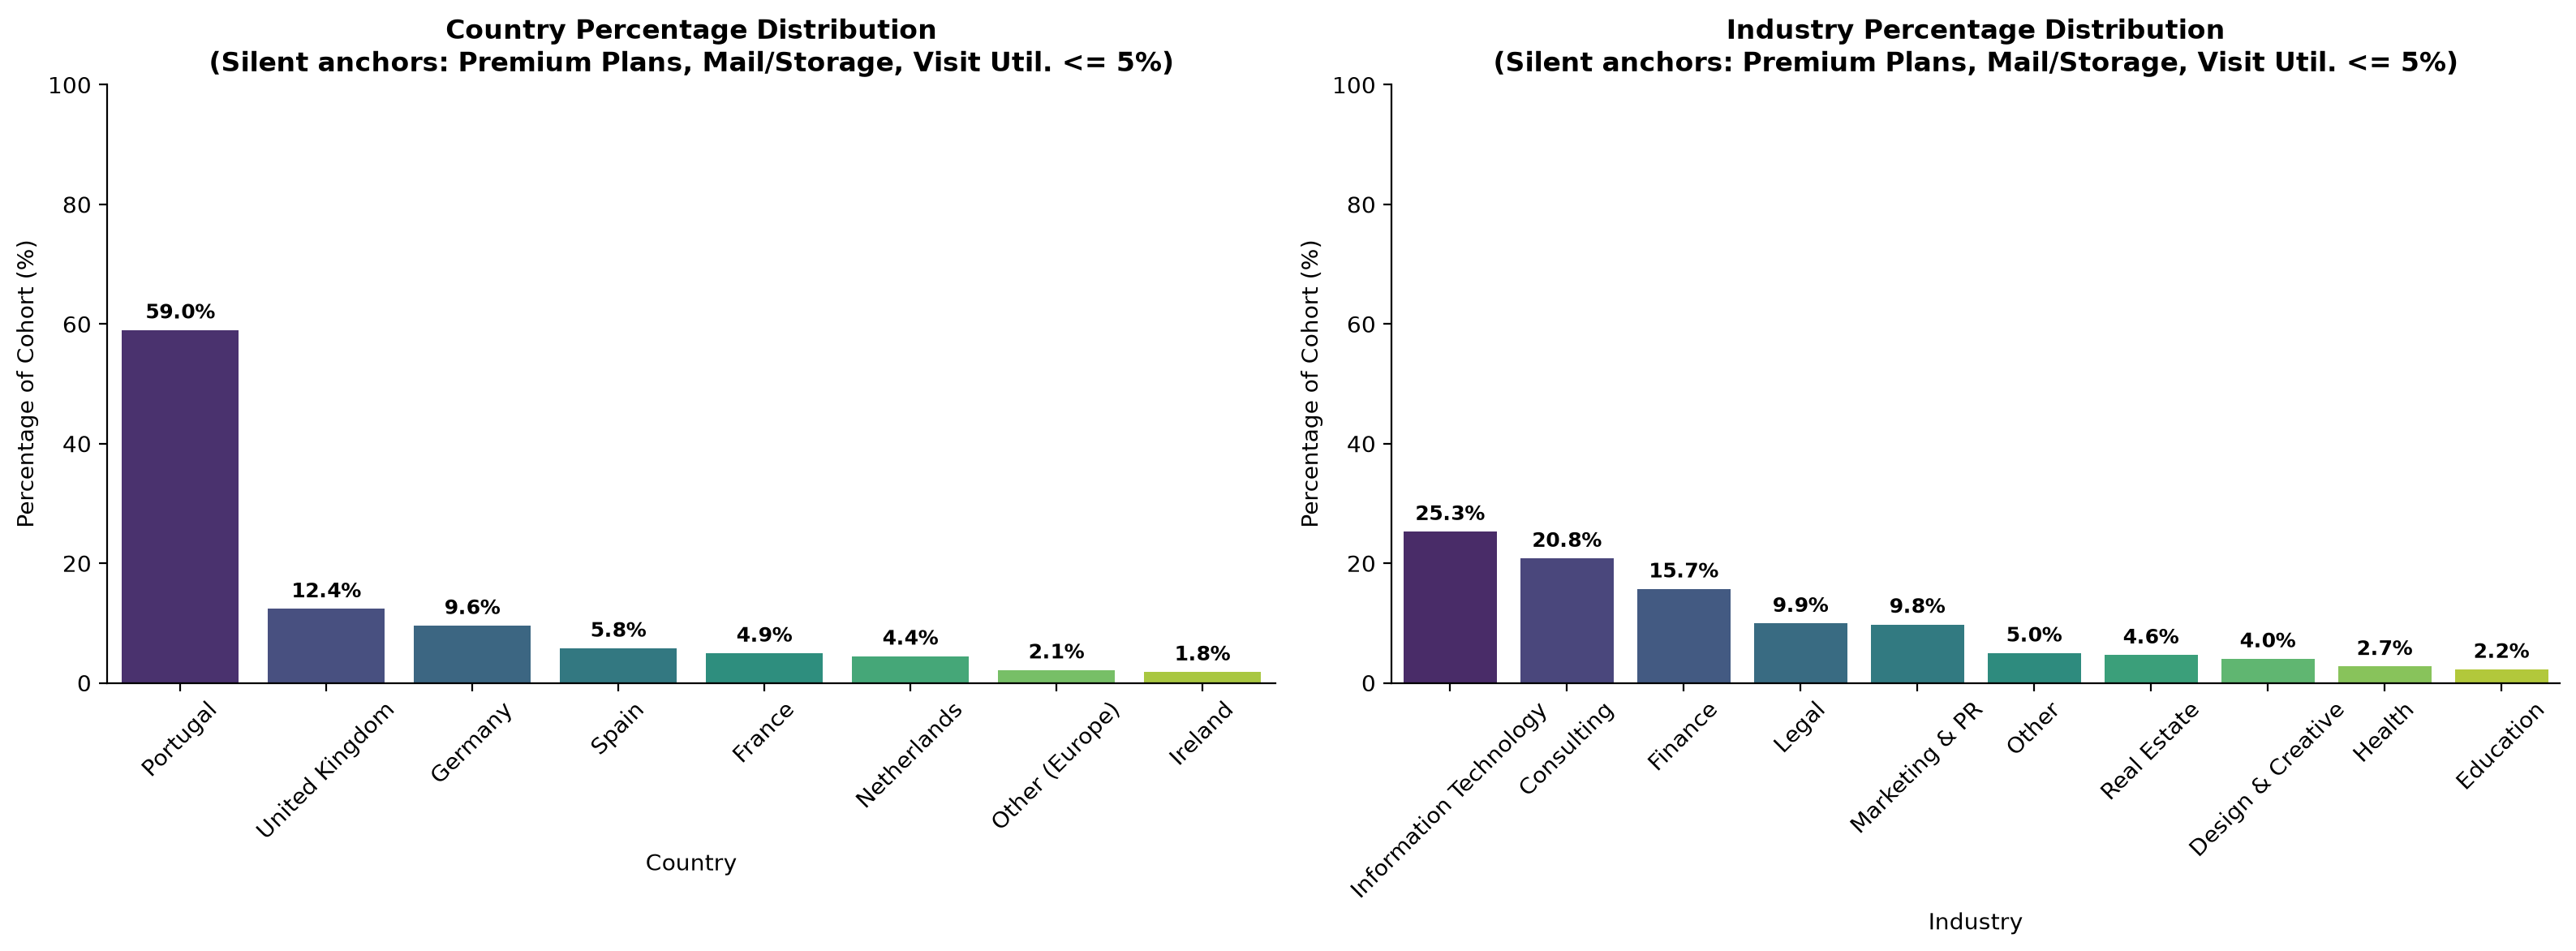

In [36]:
# 1. Copy dataframe and ensure visit utilization is computed
acdc_cohort2_pct = acdc_cleaned.copy()

if "visit_utilization" not in acdc_cohort2_pct.columns:
    acdc_cohort2_pct["visit_utilization"] = (
        acdc_cohort2_pct["actual_visits_last_period"] / 
        acdc_cohort2_pct["entitled_visits_last_period"].replace(0, np.nan)
    )

# 2. Apply the cohort conditions
premium_tiers = ["Full Time", "Dedicated Desk", "Private Office"]
cond_tier_p2 = acdc_cohort2_pct["clean_plan_tier"].isin(premium_tiers)
cond_services_p2 = (acdc_cohort2_pct["uses_mail_handling"] == True) | (acdc_cohort2_pct["uses_storage"] == True)
cond_utilization_p2 = acdc_cohort2_pct["visit_utilization"] <= 0.05

cohort_members = acdc_cohort2_pct[cond_tier_p2 & cond_services_p2 & cond_utilization_p2]

# 3. Set up a 1x2 subplot grid
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Plot 1: Country Percentage Distribution ---
country_pct = (cohort_members["clean_country"].value_counts(normalize=True) * 100).reset_index()
country_pct.columns = ["country", "percentage"]

ax1 = sns.barplot(
    data=country_pct, 
    x="country", 
    y="percentage", 
    palette="viridis",
    hue="country",
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Country Percentage Distribution\n(Silent anchors: Premium Plans, Mail/Storage, Visit Util. <= 5%)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Country", fontsize=10)
axes[0].set_ylabel("Percentage of Cohort (%)", fontsize=10)
axes[0].set_ylim(0, 100)
axes[0].tick_params(axis='x', rotation=45)

for p in ax1.patches:
    height = p.get_height()
    if height > 0:
        ax1.annotate(f'{height:.1f}%',
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', 
                     fontsize=9, fontweight='bold',
                     xytext=(0, 3), textcoords='offset points')

# --- Plot 2: Industry Percentage Distribution ---
industry_pct = (cohort_members["clean_industry"].value_counts(normalize=True) * 100).reset_index()
industry_pct.columns = ["industry", "percentage"]

ax2 = sns.barplot(
    data=industry_pct, 
    x="industry", 
    y="percentage", 
    palette="viridis",
    hue="industry",
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Industry Percentage Distribution\n(Silent anchors: Premium Plans, Mail/Storage, Visit Util. <= 5%)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Industry", fontsize=10)
axes[1].set_ylabel("Percentage of Cohort (%)", fontsize=10)
axes[1].set_ylim(0, 100)
axes[1].tick_params(axis='x', rotation=45)

for p in ax2.patches:
    height = p.get_height()
    if height > 0:
        ax2.annotate(f'{height:.1f}%',
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', 
                     fontsize=9, fontweight='bold',
                     xytext=(0, 3), textcoords='offset points')

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

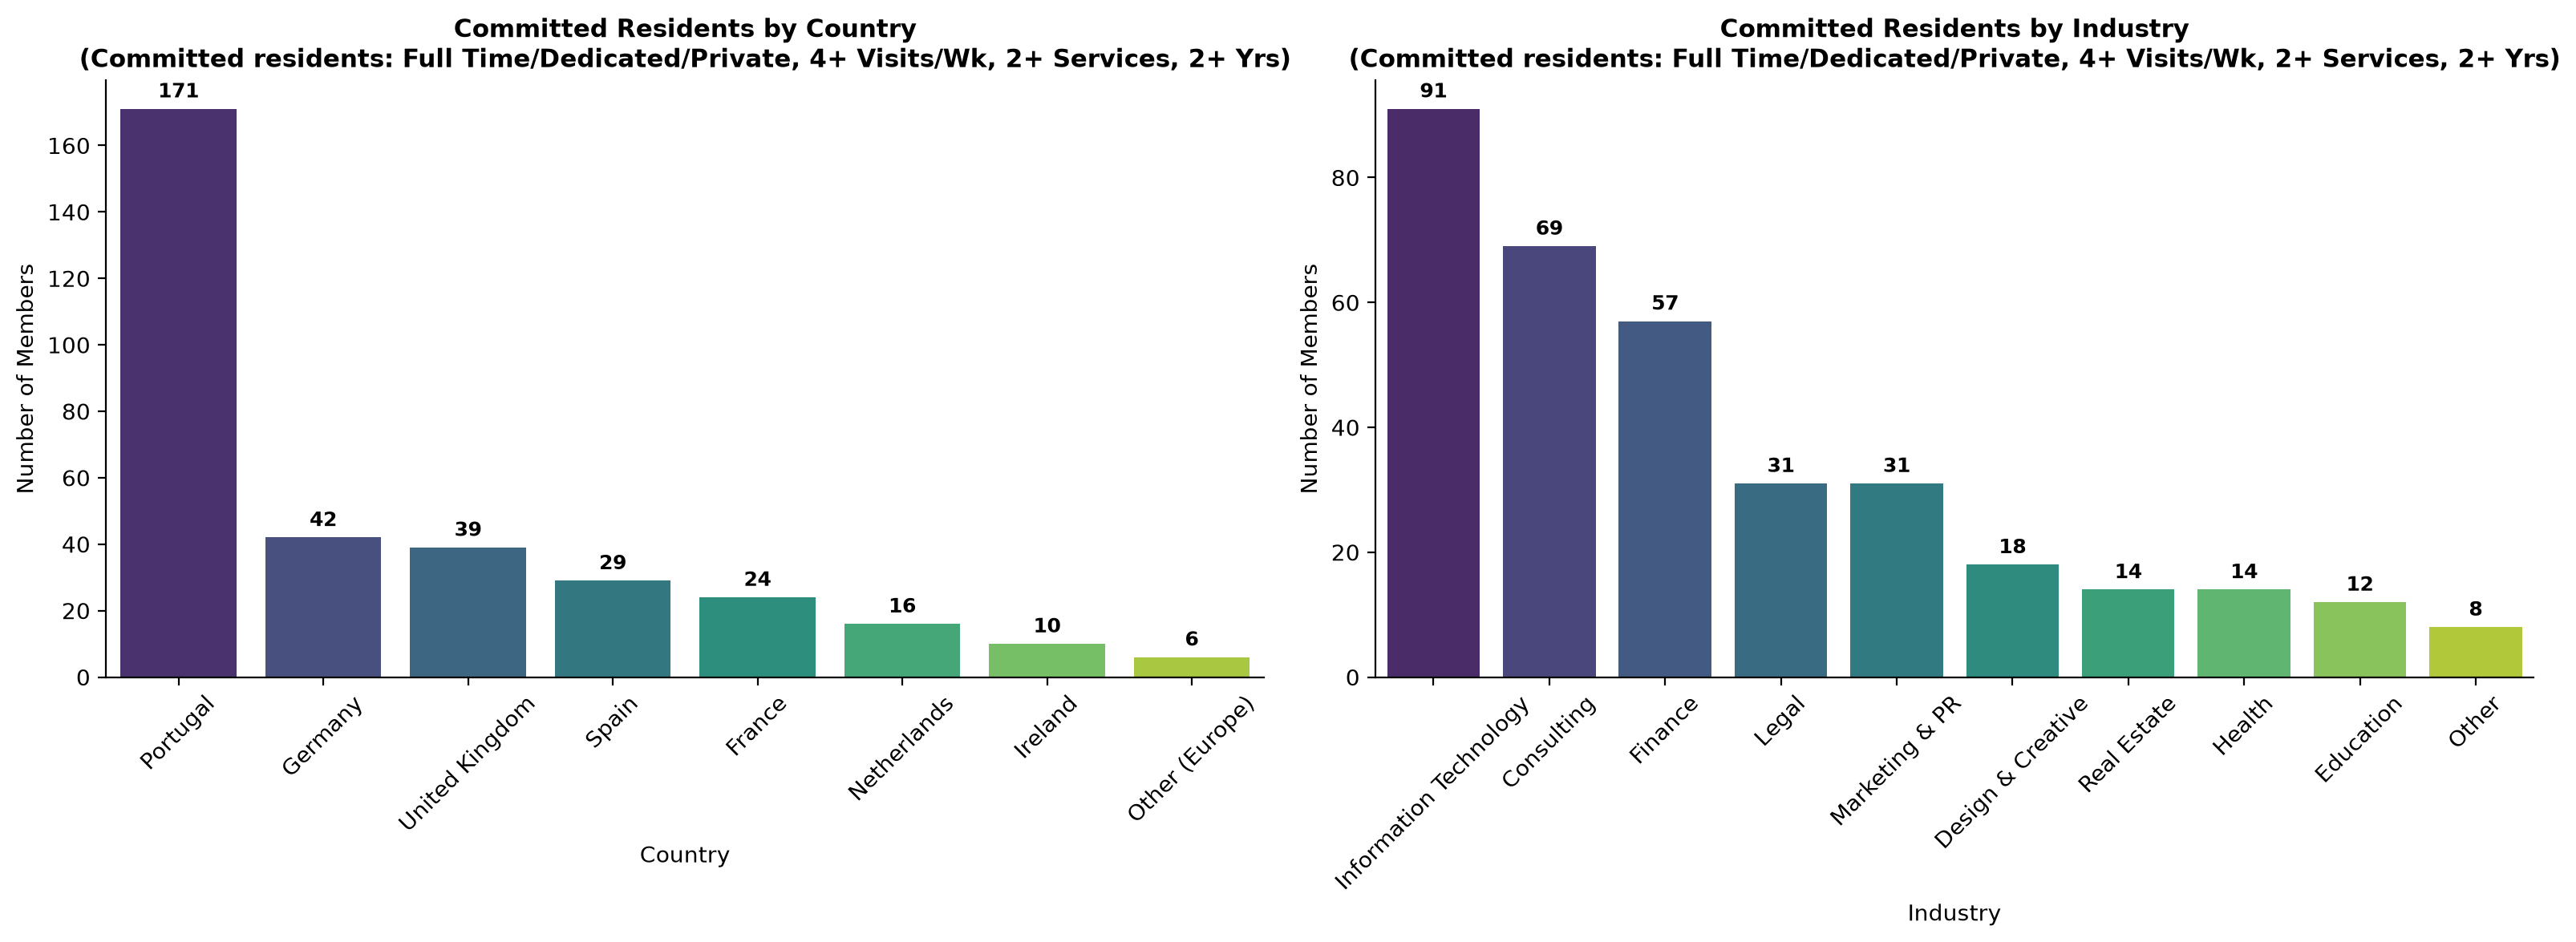

In [37]:
acdc_filtered = acdc_cleaned.copy()
start_dt = pd.to_datetime(acdc_filtered["membership_start"], errors='coerce', dayfirst=True)
end_dt = pd.to_datetime(acdc_filtered["membership_end"], errors='coerce', dayfirst=True)
last_swipe_dt = pd.to_datetime(acdc_filtered["last_badge_swipe"], errors='coerce', dayfirst=False)
effective_end_dt = end_dt.where((end_dt.notna()) & (end_dt.dt.year > 1970), last_swipe_dt)
acdc_filtered["membership_duration_days"] = (effective_end_dt - start_dt).dt.days

target_tiers = ["Full Time", "Dedicated Desk", "Private Office"]
cond_tier = acdc_filtered["clean_plan_tier"].isin(target_tiers)
cond_visits = acdc_filtered["avg_weekly_visits"] >= 4

service_cols = [
    "uses_meeting_rooms", "uses_event_space", "uses_guest_passes", 
    "uses_print", "uses_mail_handling", "uses_phone_booths", 
    "uses_day_passes", "uses_storage", "uses_bike_locker"
]
acdc_filtered["n_services_used"] = acdc_filtered[service_cols].sum(axis=1)
cond_services = acdc_filtered["n_services_used"] > 1
cond_duration = acdc_filtered["membership_duration_days"] >= 730

qualified_members = acdc_filtered[cond_tier & cond_visits & cond_services & cond_duration]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

country_counts = qualified_members["clean_country"].value_counts().reset_index()
country_counts.columns = ["country", "count"]

ax1 = sns.barplot(
    data=country_counts, 
    x="country", 
    y="count", 
    palette="viridis",
    hue="country",
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Committed Residents by Country\n(Committed residents: Full Time/Dedicated/Private, 4+ Visits/Wk, 2+ Services, 2+ Yrs)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Country", fontsize=10)
axes[0].set_ylabel("Number of Members", fontsize=10)
axes[0].tick_params(axis='x', rotation=45)

for p in ax1.patches:
    height = p.get_height()
    if height > 0:
        ax1.annotate(f'{int(height)}',
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', 
                     fontsize=9, fontweight='bold',
                     xytext=(0, 3), textcoords='offset points')

industry_counts = qualified_members["clean_industry"].value_counts().reset_index()
industry_counts.columns = ["industry", "count"]

ax2 = sns.barplot(
    data=industry_counts, 
    x="industry", 
    y="count", 
    palette="viridis",
    hue="industry",
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Committed Residents by Industry\n(Committed residents: Full Time/Dedicated/Private, 4+ Visits/Wk, 2+ Services, 2+ Yrs)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Industry", fontsize=10)
axes[1].set_ylabel("Number of Members", fontsize=10)
axes[1].tick_params(axis='x', rotation=45)

for p in ax2.patches:
    height = p.get_height()
    if height > 0:
        ax2.annotate(f'{int(height)}',
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', 
                     fontsize=9, fontweight='bold',
                     xytext=(0, 3), textcoords='offset points')

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

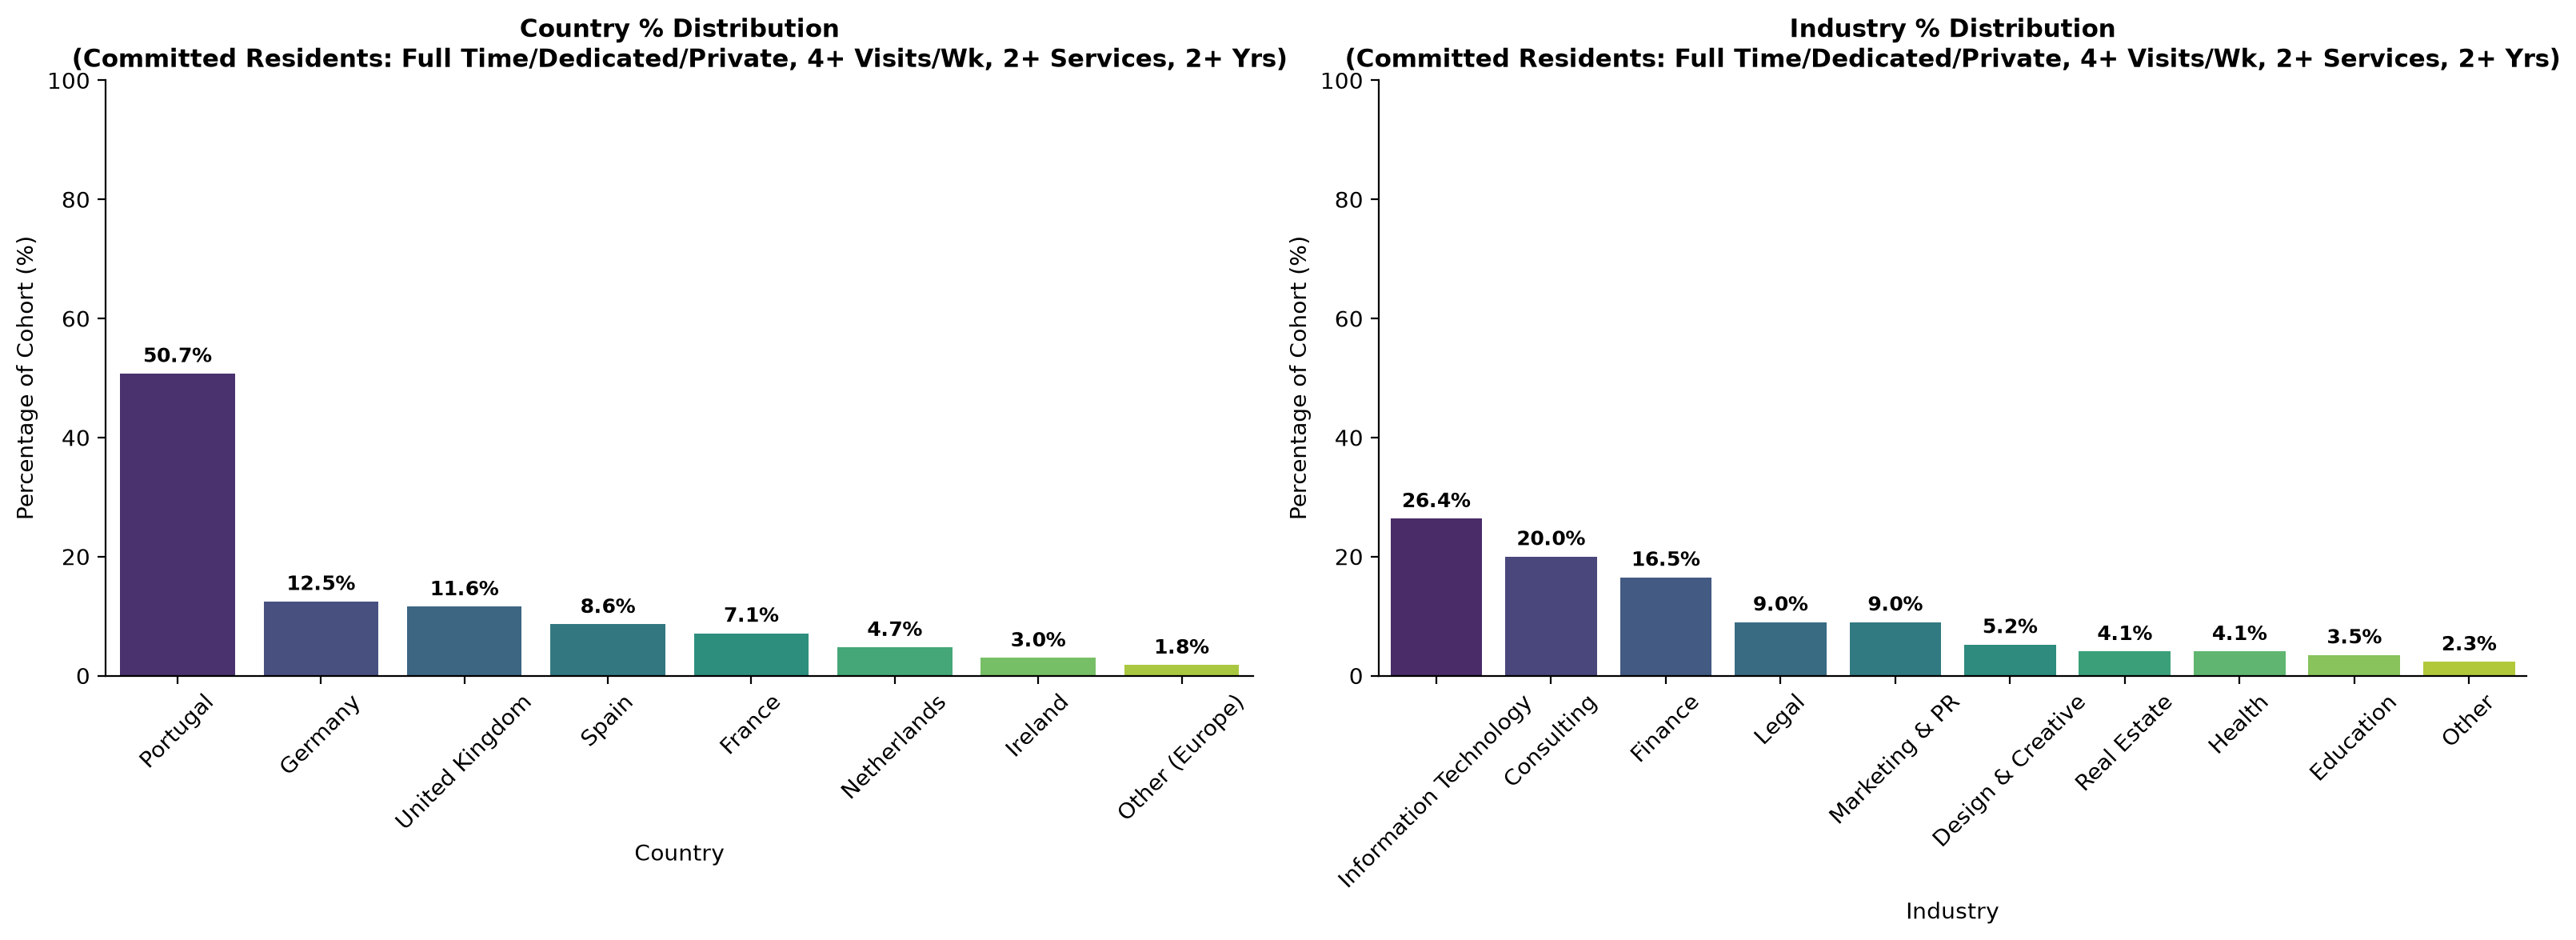

In [38]:
# 1. Copy dataframe and calculate membership duration
acdc_filtered_pct = acdc_cleaned.copy()
start_dt = pd.to_datetime(acdc_filtered_pct["membership_start"], errors='coerce', dayfirst=True)
end_dt = pd.to_datetime(acdc_filtered_pct["membership_end"], errors='coerce', dayfirst=True)
last_swipe_dt = pd.to_datetime(acdc_filtered_pct["last_badge_swipe"], errors='coerce', dayfirst=False)
effective_end_dt = end_dt.where((end_dt.notna()) & (end_dt.dt.year > 1970), last_swipe_dt)
acdc_filtered_pct["membership_duration_days"] = (effective_end_dt - start_dt).dt.days

# 2. Apply all conditions for "Committed Residents"
target_tiers = ["Full Time", "Dedicated Desk", "Private Office"]
cond_tier = acdc_filtered_pct["clean_plan_tier"].isin(target_tiers)
cond_visits = acdc_filtered_pct["avg_weekly_visits"] >= 4

service_cols = [
    "uses_meeting_rooms", "uses_event_space", "uses_guest_passes", 
    "uses_print", "uses_mail_handling", "uses_phone_booths", 
    "uses_day_passes", "uses_storage", "uses_bike_locker"
]
acdc_filtered_pct["n_services_used"] = acdc_filtered_pct[service_cols].sum(axis=1)
cond_services = acdc_filtered_pct["n_services_used"] > 1
cond_duration = acdc_filtered_pct["membership_duration_days"] >= 730

qualified_members = acdc_filtered_pct[cond_tier & cond_visits & cond_services & cond_duration]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

country_pct = (qualified_members["clean_country"].value_counts(normalize=True) * 100).reset_index()
country_pct.columns = ["country", "percentage"]

ax1 = sns.barplot(
    data=country_pct, 
    x="country", 
    y="percentage", 
    palette="viridis",
    hue="country",
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Country % Distribution\n(Committed Residents: Full Time/Dedicated/Private, 4+ Visits/Wk, 2+ Services, 2+ Yrs)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Country", fontsize=10)
axes[0].set_ylabel("Percentage of Cohort (%)", fontsize=10)
axes[0].set_ylim(0, 100)
axes[0].tick_params(axis='x', rotation=45)

for p in ax1.patches:
    height = p.get_height()
    if height > 0:
        ax1.annotate(f'{height:.1f}%',
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', 
                     fontsize=9, fontweight='bold',
                     xytext=(0, 3), textcoords='offset points')

industry_pct = (qualified_members["clean_industry"].value_counts(normalize=True) * 100).reset_index()
industry_pct.columns = ["industry", "percentage"]

ax2 = sns.barplot(
    data=industry_pct, 
    x="industry", 
    y="percentage", 
    palette="viridis",
    hue="industry",
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Industry % Distribution\n(Committed Residents: Full Time/Dedicated/Private, 4+ Visits/Wk, 2+ Services, 2+ Yrs)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Industry", fontsize=10)
axes[1].set_ylabel("Percentage of Cohort (%)", fontsize=10)
axes[1].set_ylim(0, 100)
axes[1].tick_params(axis='x', rotation=45)

for p in ax2.patches:
    height = p.get_height()
    if height > 0:
        ax2.annotate(f'{height:.1f}%',
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', 
                     fontsize=9, fontweight='bold',
                     xytext=(0, 3), textcoords='offset points')

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

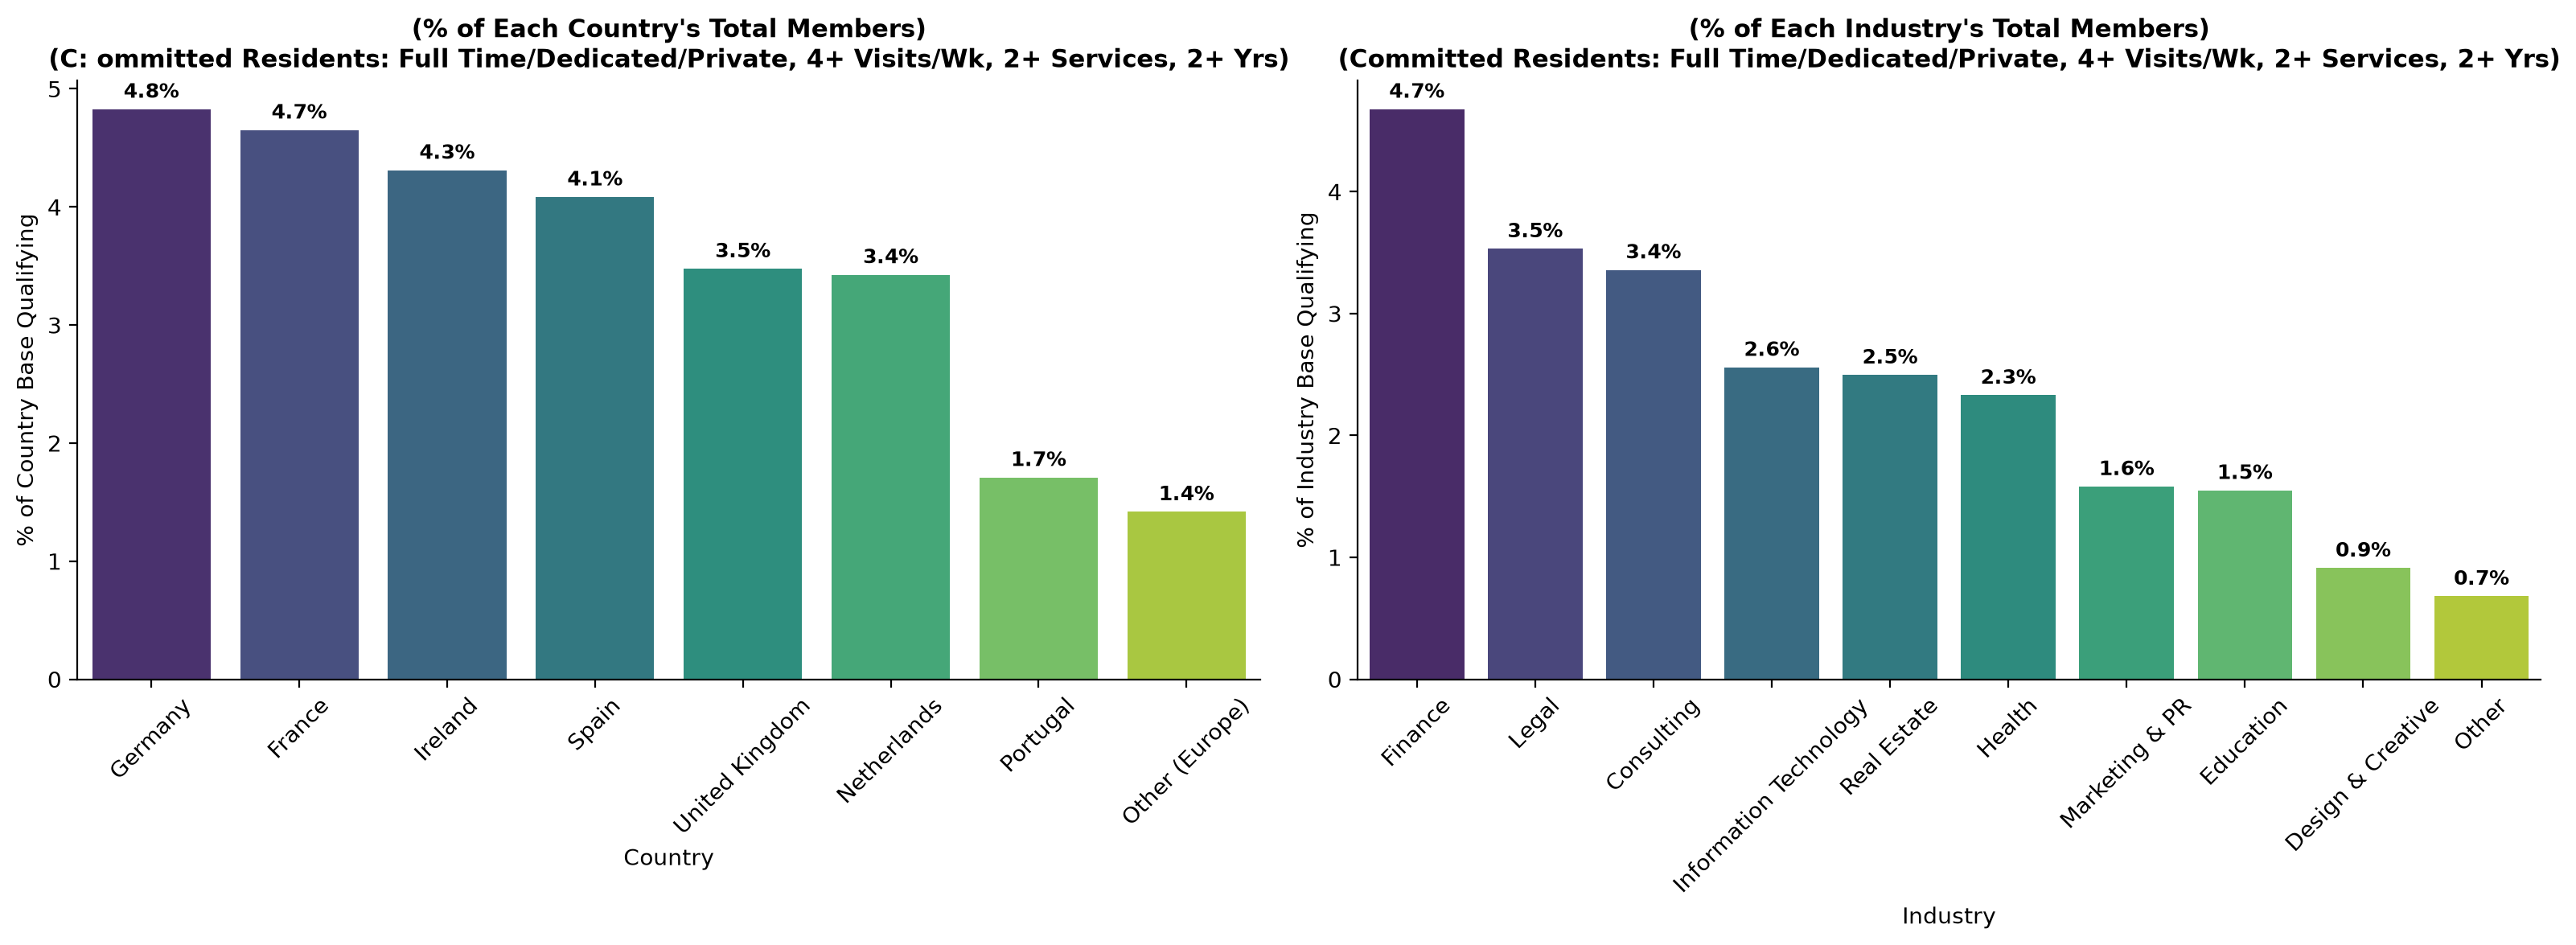

In [39]:
acdc_filtered_rate = acdc_cleaned.copy()
start_dt = pd.to_datetime(acdc_filtered_rate["membership_start"], errors='coerce', dayfirst=True)
end_dt = pd.to_datetime(acdc_filtered_rate["membership_end"], errors='coerce', dayfirst=True)
last_swipe_dt = pd.to_datetime(acdc_filtered_rate["last_badge_swipe"], errors='coerce', dayfirst=False)
effective_end_dt = end_dt.where((end_dt.notna()) & (end_dt.dt.year > 1970), last_swipe_dt)
acdc_filtered_rate["membership_duration_days"] = (effective_end_dt - start_dt).dt.days

target_tiers = ["Full Time", "Dedicated Desk", "Private Office"]
cond_tier = acdc_filtered_rate["clean_plan_tier"].isin(target_tiers)
cond_visits = acdc_filtered_rate["avg_weekly_visits"] >= 4

service_cols = [
    "uses_meeting_rooms", "uses_event_space", "uses_guest_passes", 
    "uses_print", "uses_mail_handling", "uses_phone_booths", 
    "uses_day_passes", "uses_storage", "uses_bike_locker"
]
acdc_filtered_rate["n_services_used"] = acdc_filtered_rate[service_cols].sum(axis=1)
cond_services = acdc_filtered_rate["n_services_used"] > 1
cond_duration = acdc_filtered_rate["membership_duration_days"] >= 730

qualified_members = acdc_filtered_rate[cond_tier & cond_visits & cond_services & cond_duration]

country_total = acdc_cleaned["clean_country"].value_counts()
cohort_country_counts = qualified_members["clean_country"].value_counts()
country_rate = (cohort_country_counts / country_total * 100).dropna().reset_index()
country_rate.columns = ["country", "percentage"]
country_rate = country_rate.sort_values(by="percentage", ascending=False)

industry_total = acdc_cleaned["clean_industry"].value_counts()
cohort_industry_counts = qualified_members["clean_industry"].value_counts()
industry_rate = (cohort_industry_counts / industry_total * 100).dropna().reset_index()
industry_rate.columns = ["industry", "percentage"]
industry_rate = industry_rate.sort_values(by="percentage", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax1 = sns.barplot(
    data=country_rate, 
    x="country", 
    y="percentage", 
    palette="viridis",
    hue="country",
    legend=False,
    ax=axes[0]
)
axes[0].set_title("(% of Each Country's Total Members)\n(C: ommitted Residents: Full Time/Dedicated/Private, 4+ Visits/Wk, 2+ Services, 2+ Yrs)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Country", fontsize=10)
axes[0].set_ylabel("% of Country Base Qualifying", fontsize=10)
axes[0].tick_params(axis='x', rotation=45)

for p in ax1.patches:
    height = p.get_height()
    if height > 0:
        ax1.annotate(f'{height:.1f}%',
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', 
                     fontsize=9, fontweight='bold',
                     xytext=(0, 3), textcoords='offset points')

# --- Plot 2: Industry Rate Distribution ---
ax2 = sns.barplot(
    data=industry_rate, 
    x="industry", 
    y="percentage", 
    palette="viridis",
    hue="industry",
    legend=False,
    ax=axes[1]
)
axes[1].set_title("(% of Each Industry's Total Members)\n(Committed Residents: Full Time/Dedicated/Private, 4+ Visits/Wk, 2+ Services, 2+ Yrs)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Industry", fontsize=10)
axes[1].set_ylabel("% of Industry Base Qualifying", fontsize=10)
axes[1].tick_params(axis='x', rotation=45)

for p in ax2.patches:
    height = p.get_height()
    if height > 0:
        ax2.annotate(f'{height:.1f}%',
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', 
                     fontsize=9, fontweight='bold',
                     xytext=(0, 3), textcoords='offset points')

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

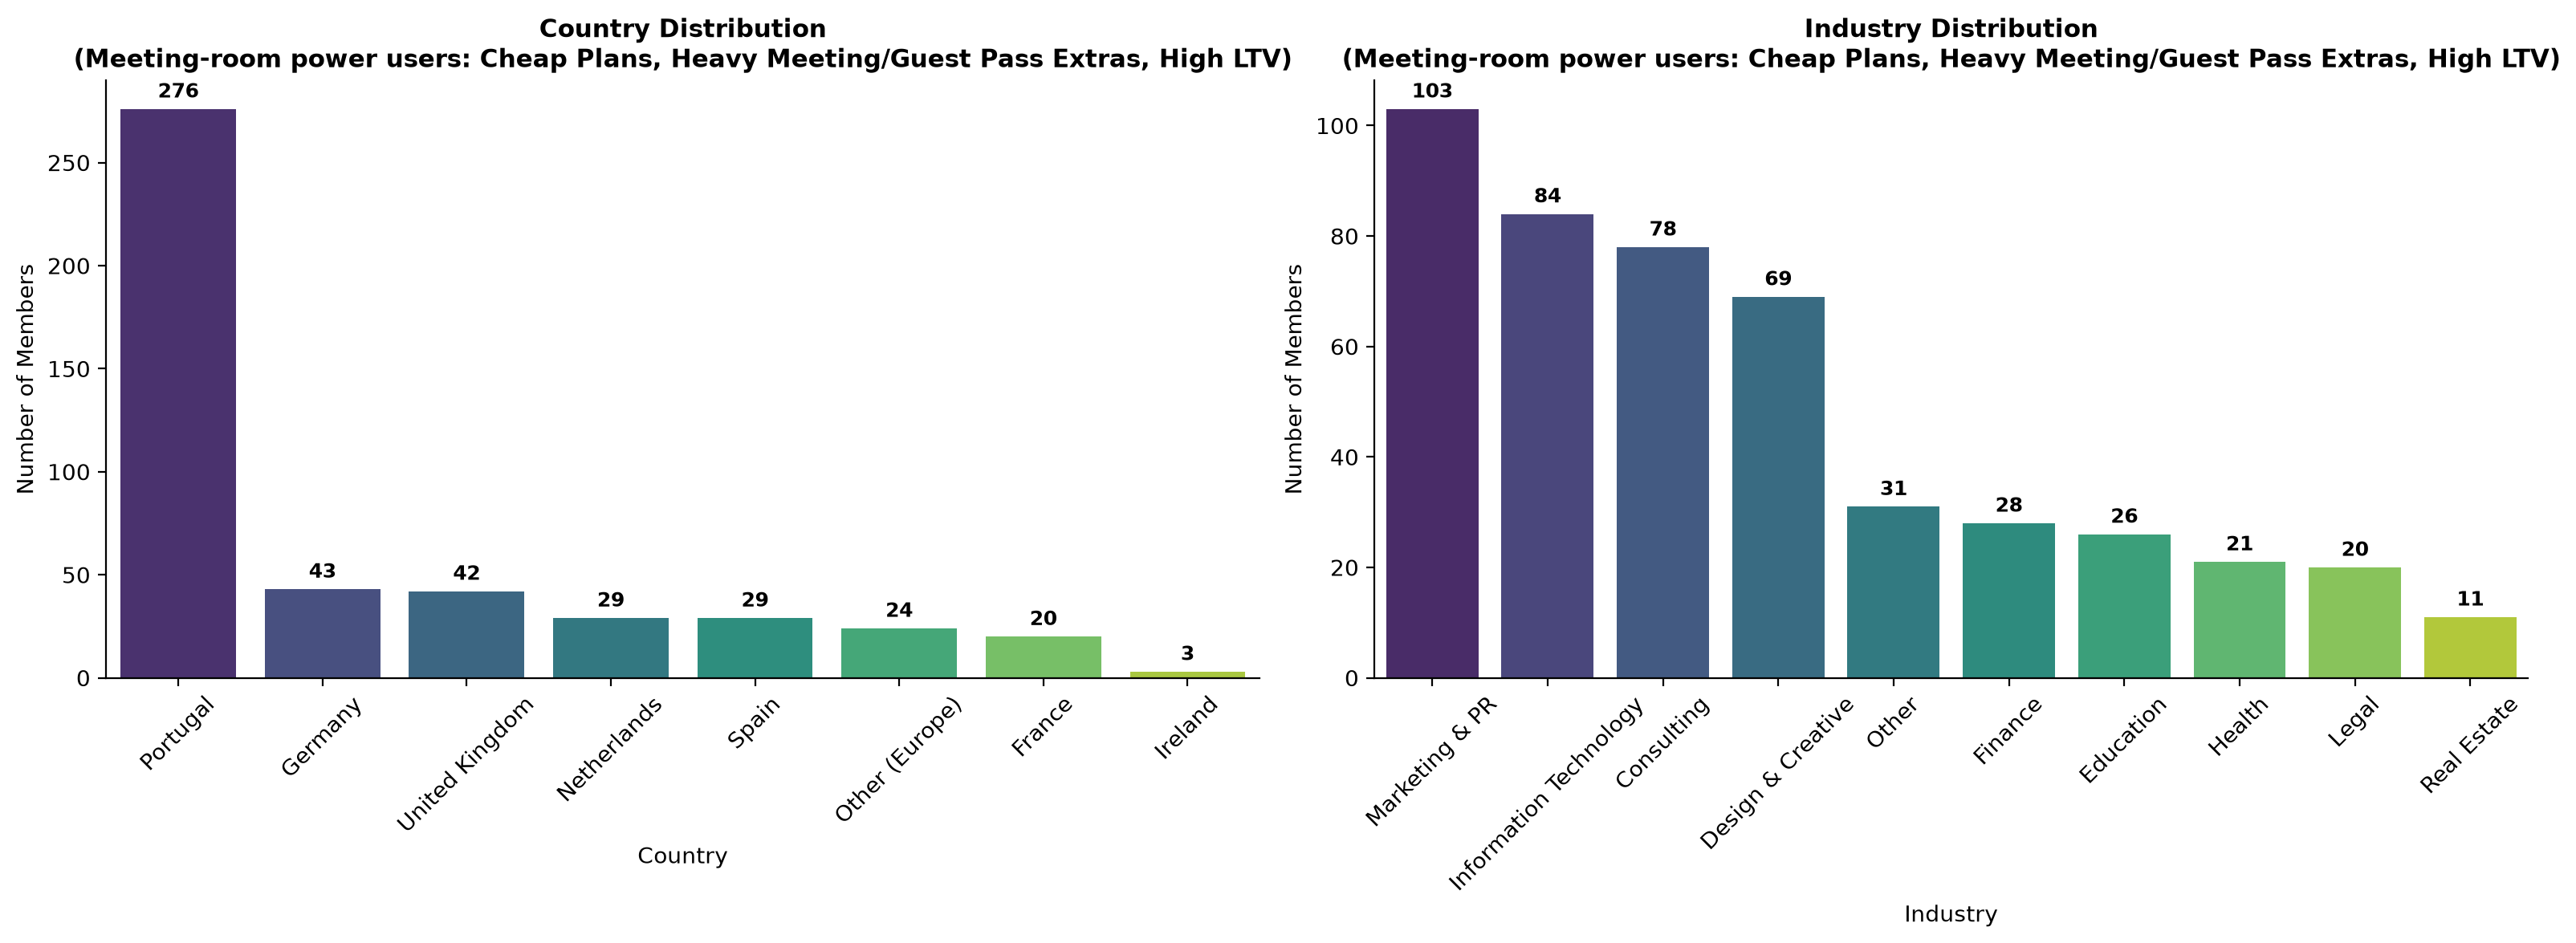

In [40]:
acdc_cohort3 = acdc_cleaned.copy()

if acdc_cohort3["lifetime_value"].dtype == object:
    acdc_cohort3["lifetime_value"] = pd.to_numeric(
        acdc_cohort3["lifetime_value"].astype(str).str.replace("€", "").str.replace(",", "").str.strip(), 
        errors="coerce"
    )

cheap_tiers = ["Flex", "Hot Desk"]
cond_tier_p3 = acdc_cohort3["clean_plan_tier"].isin(cheap_tiers)

cond_heavy_usage = (acdc_cohort3["meeting_room_hours"] > 0) & (acdc_cohort3["guest_passes_issued"] > 0)

cond_extras_p3 = acdc_cohort3["lifetime_value"] >= (acdc_cohort3["lifetime_value"].median() * 2.5)

cohort3_members = acdc_cohort3[cond_tier_p3 & cond_heavy_usage & cond_extras_p3]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

country_counts_p3 = cohort3_members["clean_country"].value_counts().reset_index()
country_counts_p3.columns = ["country", "count"]

ax1 = sns.barplot(
    data=country_counts_p3, 
    x="country", 
    y="count", 
    palette="viridis",
    hue="country",
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Country Distribution\n(Meeting-room power users: Cheap Plans, Heavy Meeting/Guest Pass Extras, High LTV)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Country", fontsize=10)
axes[0].set_ylabel("Number of Members", fontsize=10)
axes[0].tick_params(axis='x', rotation=45)

for p in ax1.patches:
    height = p.get_height()
    if height > 0:
        ax1.annotate(f'{int(height)}',
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', 
                     fontsize=9, fontweight='bold',
                     xytext=(0, 3), textcoords='offset points')

industry_counts_p3 = cohort3_members["clean_industry"].value_counts().reset_index()
industry_counts_p3.columns = ["industry", "count"]

ax2 = sns.barplot(
    data=industry_counts_p3, 
    x="industry", 
    y="count", 
    palette="viridis",
    hue="industry",
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Industry Distribution\n(Meeting-room power users: Cheap Plans, Heavy Meeting/Guest Pass Extras, High LTV)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Industry", fontsize=10)
axes[1].set_ylabel("Number of Members", fontsize=10)
axes[1].tick_params(axis='x', rotation=45)

for p in ax2.patches:
    height = p.get_height()
    if height > 0:
        ax2.annotate(f'{int(height)}',
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', 
                     fontsize=9, fontweight='bold',
                     xytext=(0, 3), textcoords='offset points')

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

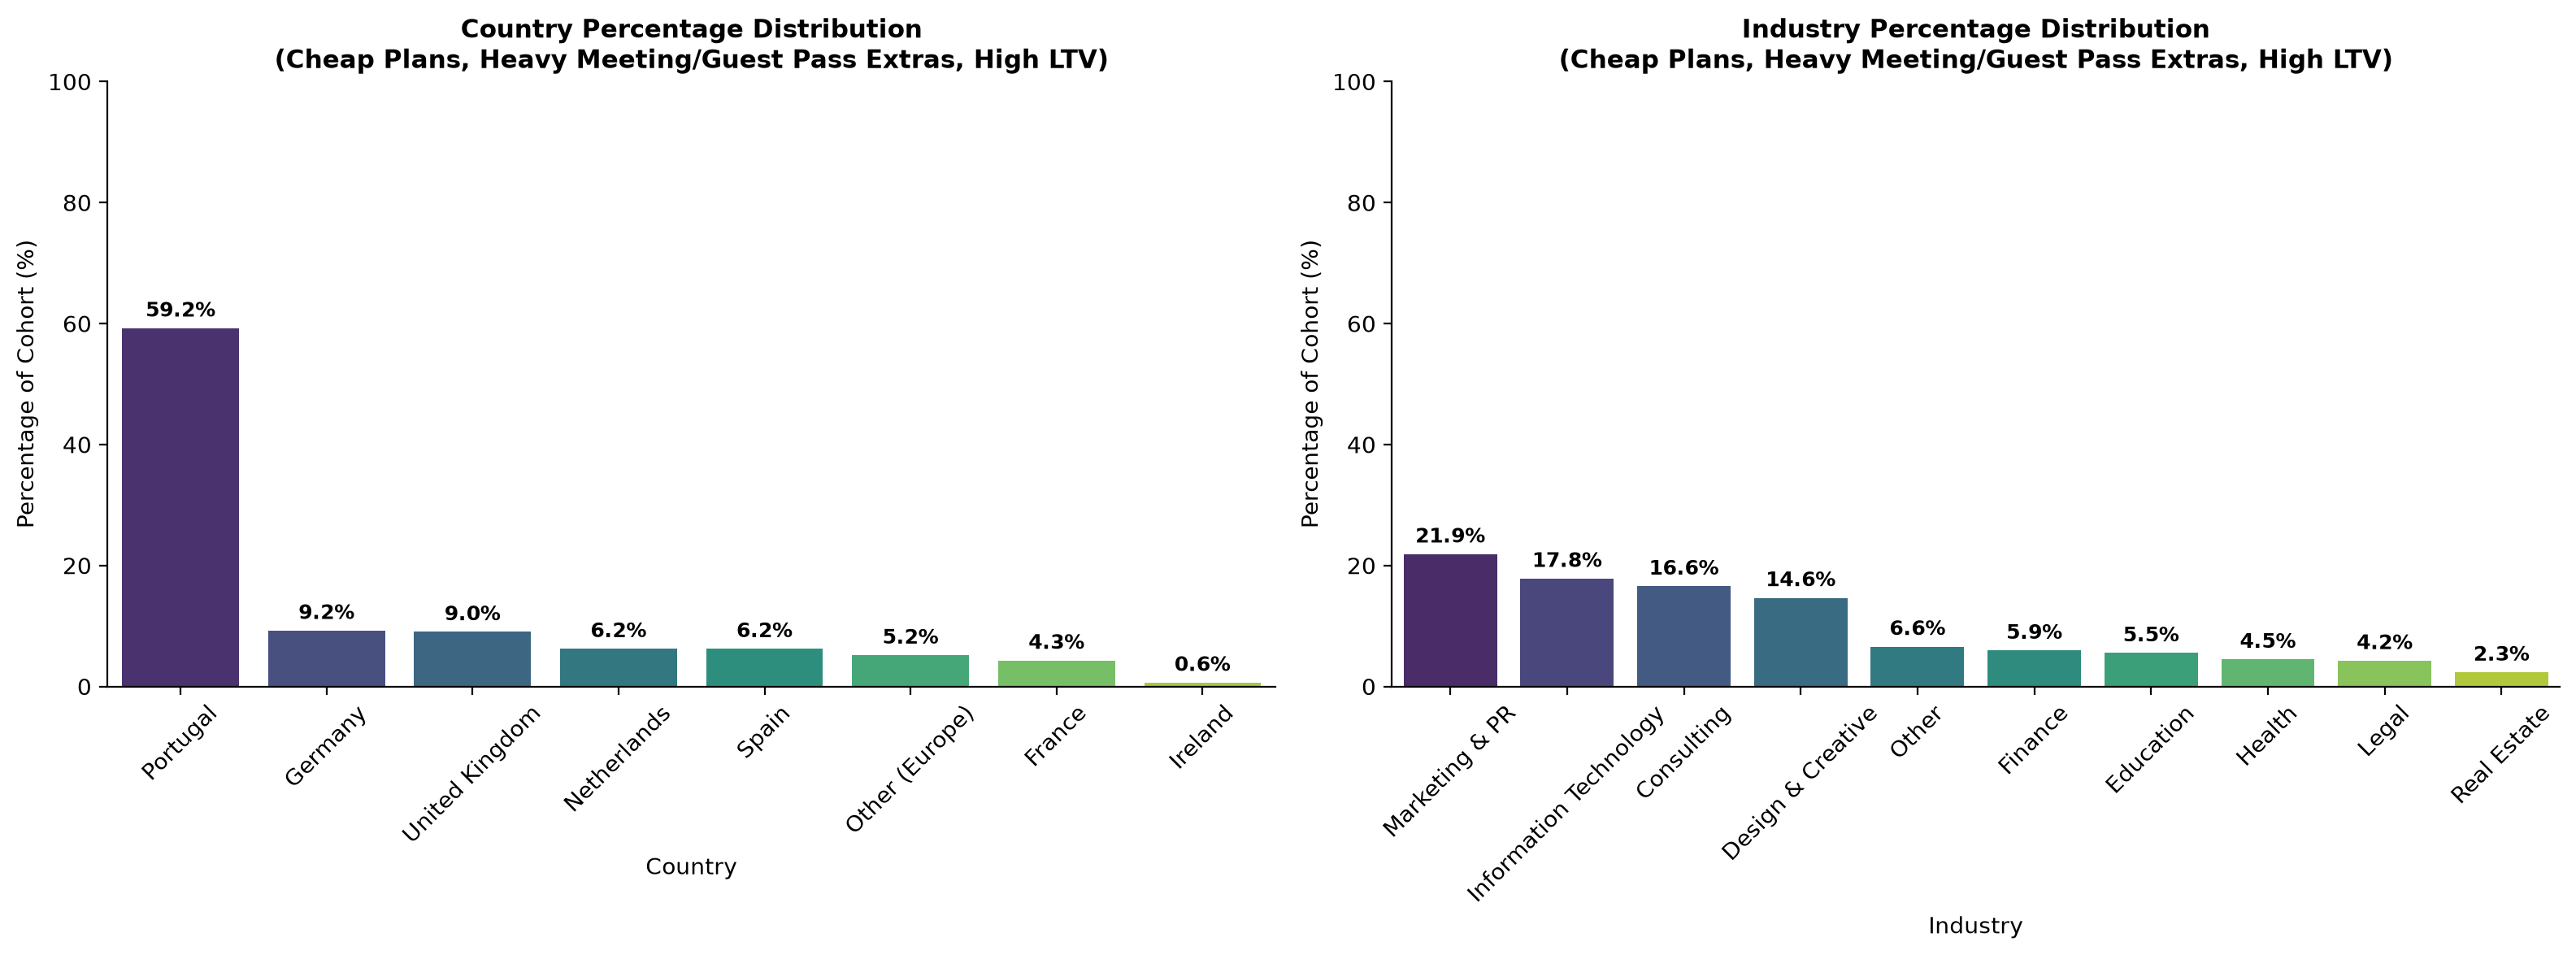

In [41]:
acdc_cohort3_pct = acdc_cleaned.copy()

if acdc_cohort3_pct["lifetime_value"].dtype == object:
    acdc_cohort3_pct["lifetime_value"] = pd.to_numeric(
        acdc_cohort3_pct["lifetime_value"].astype(str).str.replace("€", "").str.replace(",", "").str.strip(), 
        errors="coerce"
    )

cheap_tiers = ["Flex", "Hot Desk"]
cond_tier_p3 = acdc_cohort3_pct["clean_plan_tier"].isin(cheap_tiers)
cond_heavy_usage = (acdc_cohort3_pct["meeting_room_hours"] > 0) & (acdc_cohort3_pct["guest_passes_issued"] > 0)
cond_extras_p3 = acdc_cohort3_pct["lifetime_value"] >= (acdc_cohort3_pct["lifetime_value"].median() * 2.5)

cohort3_members = acdc_cohort3_pct[cond_tier_p3 & cond_heavy_usage & cond_extras_p3]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

country_pct = (cohort3_members["clean_country"].value_counts(normalize=True) * 100).reset_index()
country_pct.columns = ["country", "percentage"]

ax1 = sns.barplot(
    data=country_pct, 
    x="country", 
    y="percentage", 
    palette="viridis",
    hue="country",
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Country Percentage Distribution\n(Cheap Plans, Heavy Meeting/Guest Pass Extras, High LTV)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Country", fontsize=10)
axes[0].set_ylabel("Percentage of Cohort (%)", fontsize=10)
axes[0].set_ylim(0, 100)
axes[0].tick_params(axis='x', rotation=45)

for p in ax1.patches:
    height = p.get_height()
    if height > 0:
        ax1.annotate(f'{height:.1f}%',
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', 
                     fontsize=9, fontweight='bold',
                     xytext=(0, 3), textcoords='offset points')

industry_pct = (cohort3_members["clean_industry"].value_counts(normalize=True) * 100).reset_index()
industry_pct.columns = ["industry", "percentage"]

ax2 = sns.barplot(
    data=industry_pct, 
    x="industry", 
    y="percentage", 
    palette="viridis",
    hue="industry",
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Industry Percentage Distribution\n(Cheap Plans, Heavy Meeting/Guest Pass Extras, High LTV)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Industry", fontsize=10)
axes[1].set_ylabel("Percentage of Cohort (%)", fontsize=10)
axes[1].set_ylim(0, 100)
axes[1].tick_params(axis='x', rotation=45)

for p in ax2.patches:
    height = p.get_height()
    if height > 0:
        ax2.annotate(f'{height:.1f}%',
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', 
                     fontsize=9, fontweight='bold',
                     xytext=(0, 3), textcoords='offset points')

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

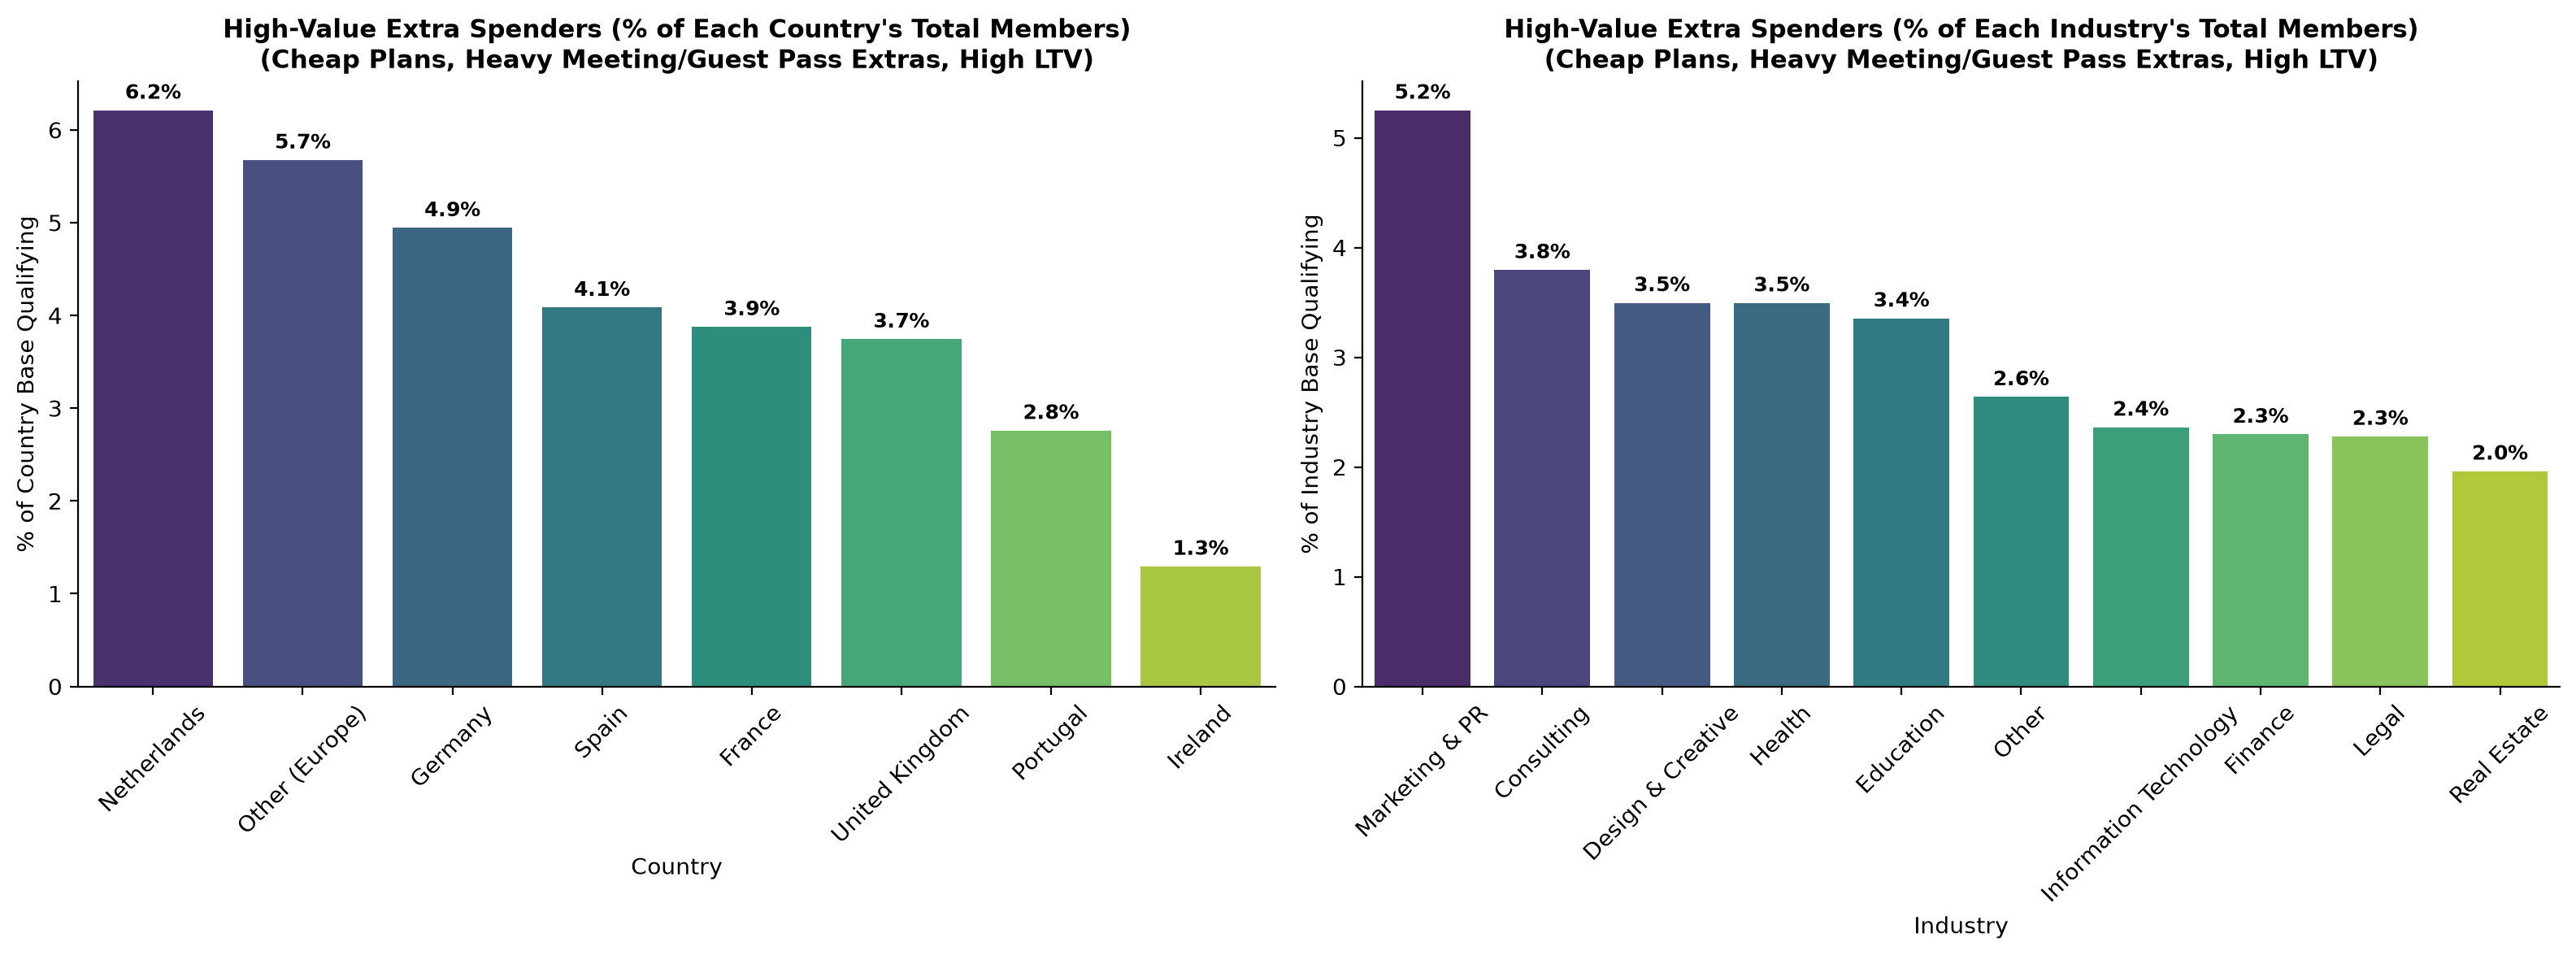

In [42]:
acdc_cohort3_rate = acdc_cleaned.copy()

if acdc_cohort3_rate["lifetime_value"].dtype == object:
    acdc_cohort3_rate["lifetime_value"] = pd.to_numeric(
        acdc_cohort3_rate["lifetime_value"].astype(str).str.replace("€", "").str.replace(",", "").str.strip(), 
        errors="coerce"
    )

cheap_tiers = ["Flex", "Hot Desk"]
cond_tier_p3 = acdc_cohort3_rate["clean_plan_tier"].isin(cheap_tiers)
cond_heavy_usage = (acdc_cohort3_rate["meeting_room_hours"] > 0) & (acdc_cohort3_rate["guest_passes_issued"] > 0)
cond_extras_p3 = acdc_cohort3_rate["lifetime_value"] >= (acdc_cohort3_rate["lifetime_value"].median() * 2.5)

cohort3_members = acdc_cohort3_rate[cond_tier_p3 & cond_heavy_usage & cond_extras_p3]

country_total = acdc_cleaned["clean_country"].value_counts()
cohort_country_counts = cohort3_members["clean_country"].value_counts()
country_rate = (cohort_country_counts / country_total * 100).dropna().reset_index()
country_rate.columns = ["country", "percentage"]
country_rate = country_rate.sort_values(by="percentage", ascending=False)

industry_total = acdc_cleaned["clean_industry"].value_counts()
cohort_industry_counts = cohort3_members["clean_industry"].value_counts()
industry_rate = (cohort_industry_counts / industry_total * 100).dropna().reset_index()
industry_rate.columns = ["industry", "percentage"]
industry_rate = industry_rate.sort_values(by="percentage", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax1 = sns.barplot(
    data=country_rate, 
    x="country", 
    y="percentage", 
    palette="viridis",
    hue="country",
    legend=False,
    ax=axes[0]
)
axes[0].set_title("High-Value Extra Spenders (% of Each Country's Total Members)\n(Cheap Plans, Heavy Meeting/Guest Pass Extras, High LTV)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Country", fontsize=10)
axes[0].set_ylabel("% of Country Base Qualifying", fontsize=10)
axes[0].tick_params(axis='x', rotation=45)

for p in ax1.patches:
    height = p.get_height()
    if height > 0:
        ax1.annotate(f'{height:.1f}%',
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', 
                     fontsize=9, fontweight='bold',
                     xytext=(0, 3), textcoords='offset points')

ax2 = sns.barplot(
    data=industry_rate, 
    x="industry", 
    y="percentage", 
    palette="viridis",
    hue="industry",
    legend=False,
    ax=axes[1]
)
axes[1].set_title("High-Value Extra Spenders (% of Each Industry's Total Members)\n(Cheap Plans, Heavy Meeting/Guest Pass Extras, High LTV)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Industry", fontsize=10)
axes[1].set_ylabel("% of Industry Base Qualifying", fontsize=10)
axes[1].tick_params(axis='x', rotation=45)

for p in ax2.patches:
    height = p.get_height()
    if height > 0:
        ax2.annotate(f'{height:.1f}%',
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', 
                     fontsize=9, fontweight='bold',
                     xytext=(0, 3), textcoords='offset points')

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

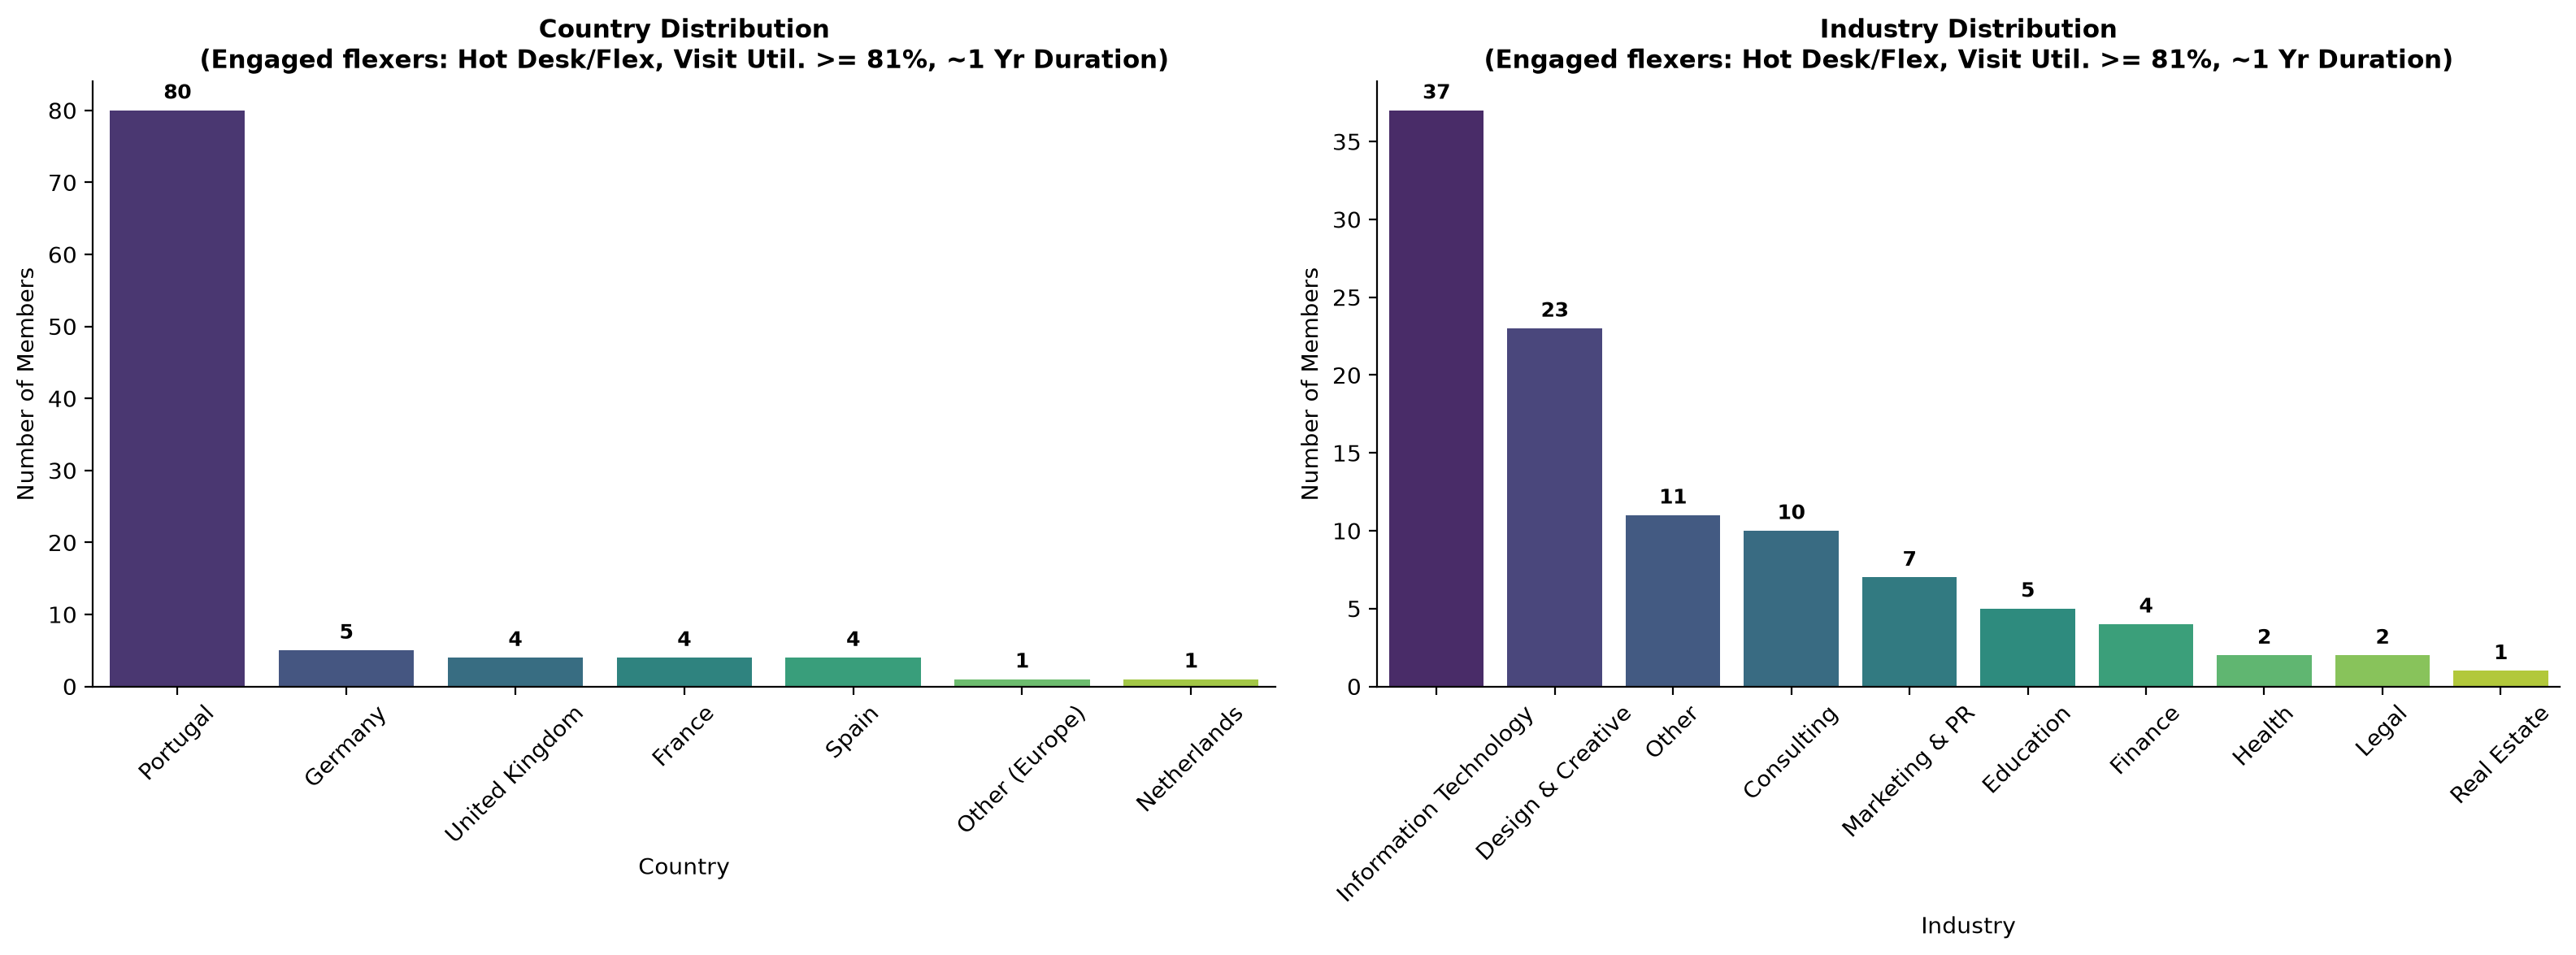

In [43]:
acdc_cohort4 = acdc_cleaned.copy()

if "visit_utilization" not in acdc_cohort4.columns:
    acdc_cohort4["visit_utilization"] = (
        acdc_cohort4["actual_visits_last_period"] / 
        acdc_cohort4["entitled_visits_last_period"].replace(0, np.nan)
    )

start_dt = pd.to_datetime(acdc_cohort4["membership_start"], errors='coerce', dayfirst=True)
end_dt = pd.to_datetime(acdc_cohort4["membership_end"], errors='coerce', dayfirst=True)
last_swipe_dt = pd.to_datetime(acdc_cohort4["last_badge_swipe"], errors='coerce', dayfirst=False)
effective_end_dt = end_dt.where((end_dt.notna()) & (end_dt.dt.year > 1970), last_swipe_dt)
acdc_cohort4["membership_duration_days"] = (effective_end_dt - start_dt).dt.days


cheap_tiers = ["Flex", "Hot Desk"]
cond_tier_p4 = acdc_cohort4["clean_plan_tier"].isin(cheap_tiers)

cond_utilization_p4 = acdc_cohort4["visit_utilization"] >= 0.81

cond_duration_p4 = (acdc_cohort4["membership_duration_days"] >= 330) & (acdc_cohort4["membership_duration_days"] <= 400)

cohort4_members = acdc_cohort4[cond_tier_p4 & cond_utilization_p4 & cond_duration_p4]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

country_counts_p4 = cohort4_members["clean_country"].value_counts().reset_index()
country_counts_p4.columns = ["country", "count"]

ax1 = sns.barplot(
    data=country_counts_p4, 
    x="country", 
    y="count", 
    palette="viridis",
    hue="country",
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Country Distribution\n(Engaged flexers: Hot Desk/Flex, Visit Util. >= 81%, ~1 Yr Duration)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Country", fontsize=10)
axes[0].set_ylabel("Number of Members", fontsize=10)
axes[0].tick_params(axis='x', rotation=45)

for p in ax1.patches:
    height = p.get_height()
    if height > 0:
        ax1.annotate(f'{int(height)}',
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', 
                     fontsize=9, fontweight='bold',
                     xytext=(0, 3), textcoords='offset points')

industry_counts_p4 = cohort4_members["clean_industry"].value_counts().reset_index()
industry_counts_p4.columns = ["industry", "count"]

ax2 = sns.barplot(
    data=industry_counts_p4, 
    x="industry", 
    y="count", 
    palette="viridis",
    hue="industry",
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Industry Distribution\n(Engaged flexers: Hot Desk/Flex, Visit Util. >= 81%, ~1 Yr Duration)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Industry", fontsize=10)
axes[1].set_ylabel("Number of Members", fontsize=10)
axes[1].tick_params(axis='x', rotation=45)

for p in ax2.patches:
    height = p.get_height()
    if height > 0:
        ax2.annotate(f'{int(height)}',
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', 
                     fontsize=9, fontweight='bold',
                     xytext=(0, 3), textcoords='offset points')

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

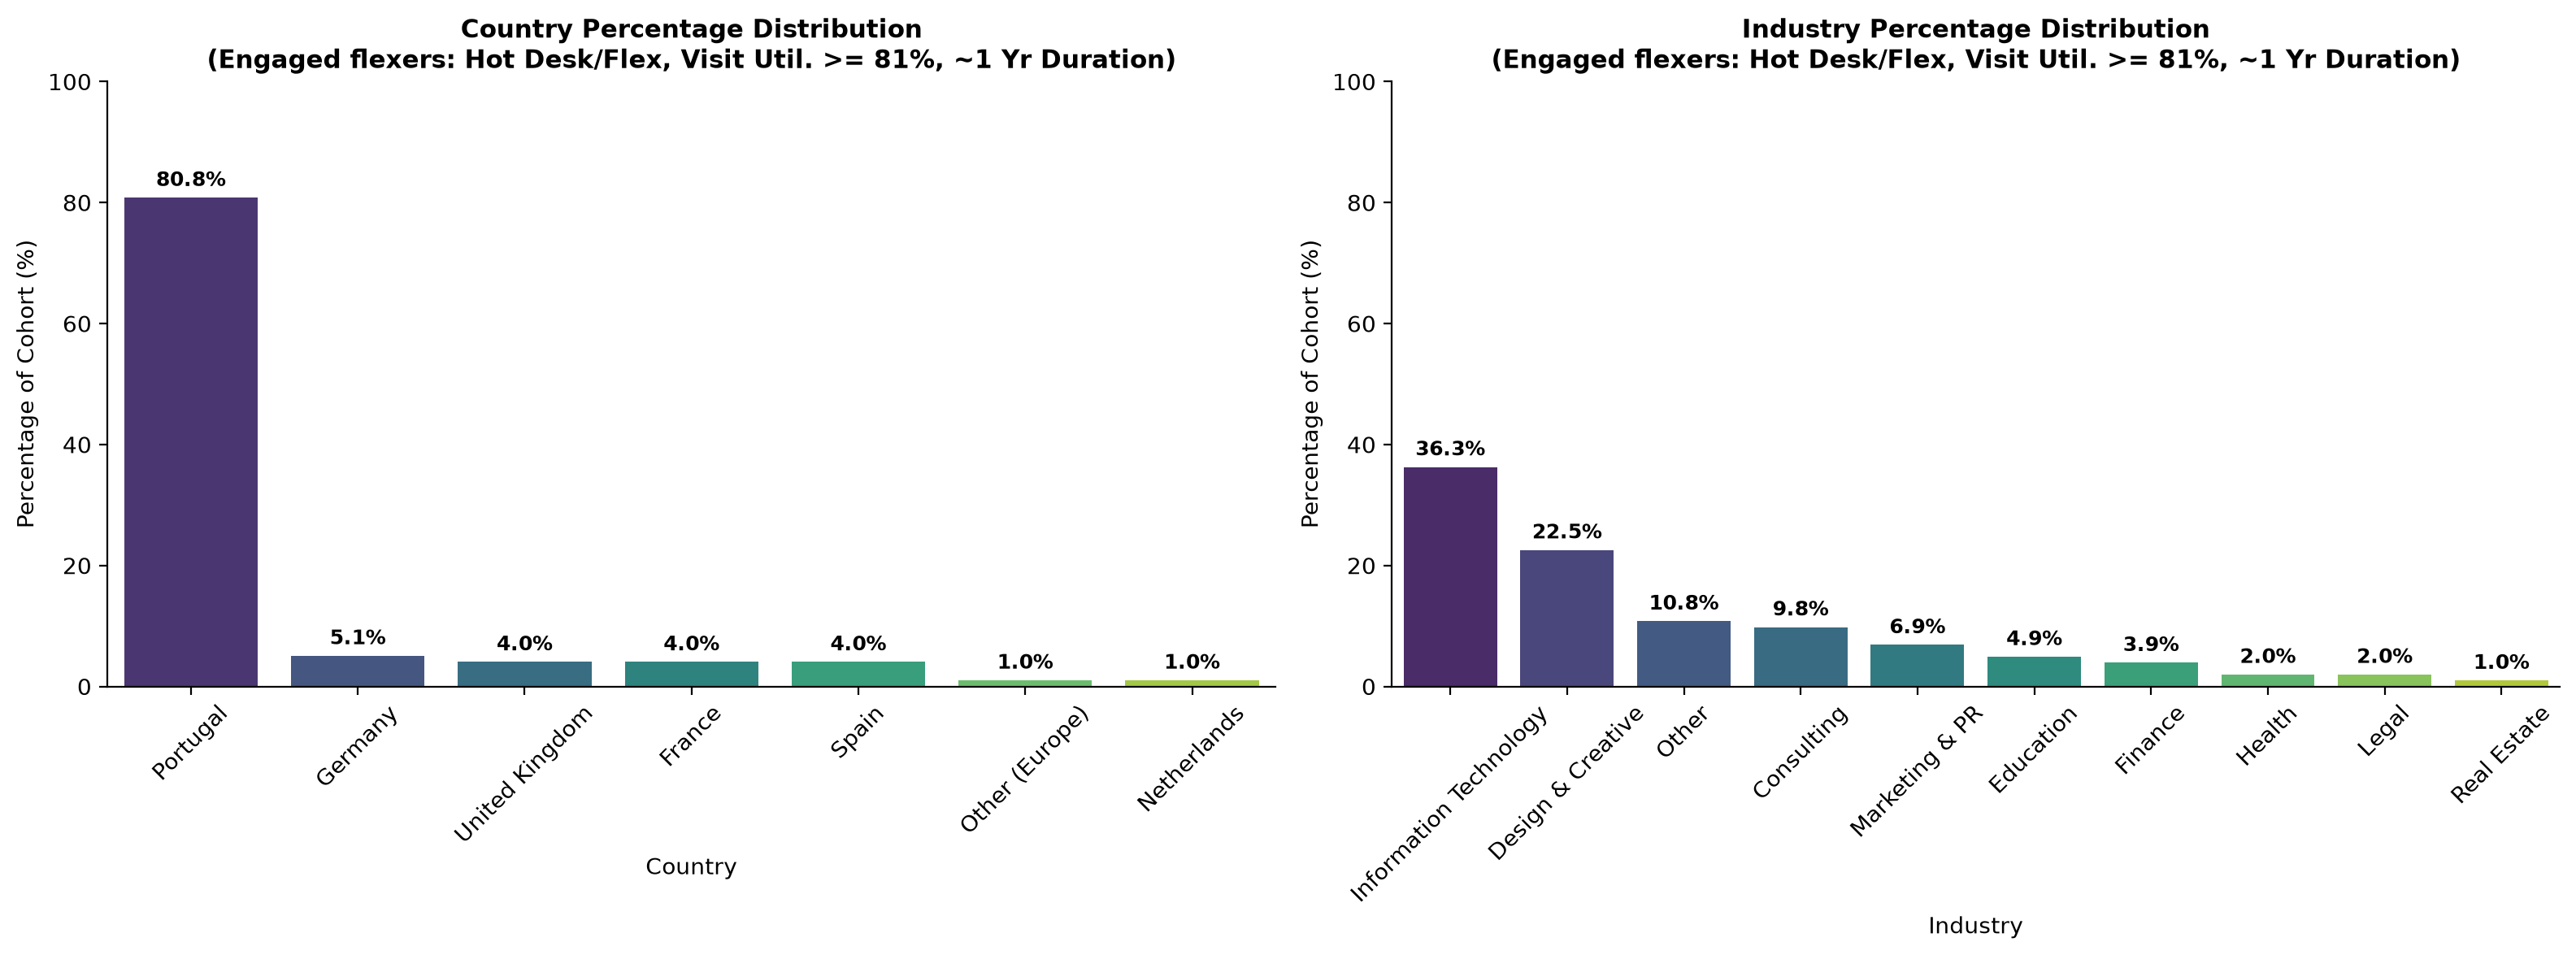

In [44]:
acdc_cohort4_pct = acdc_cleaned.copy()

if "visit_utilization" not in acdc_cohort4_pct.columns:
    acdc_cohort4_pct["visit_utilization"] = (
        acdc_cohort4_pct["actual_visits_last_period"] / 
        acdc_cohort4_pct["entitled_visits_last_period"].replace(0, np.nan)
    )

start_dt = pd.to_datetime(acdc_cohort4_pct["membership_start"], errors='coerce', dayfirst=True)
end_dt = pd.to_datetime(acdc_cohort4_pct["membership_end"], errors='coerce', dayfirst=True)
last_swipe_dt = pd.to_datetime(acdc_cohort4_pct["last_badge_swipe"], errors='coerce', dayfirst=False)
effective_end_dt = end_dt.where((end_dt.notna()) & (end_dt.dt.year > 1970), last_swipe_dt)
acdc_cohort4_pct["membership_duration_days"] = (effective_end_dt - start_dt).dt.days

cheap_tiers = ["Flex", "Hot Desk"]
cond_tier_p4 = acdc_cohort4_pct["clean_plan_tier"].isin(cheap_tiers)
cond_utilization_p4 = acdc_cohort4_pct["visit_utilization"] >= 0.81
cond_duration_p4 = (acdc_cohort4_pct["membership_duration_days"] >= 330) & (acdc_cohort4_pct["membership_duration_days"] <= 400)

cohort4_members = acdc_cohort4_pct[cond_tier_p4 & cond_utilization_p4 & cond_duration_p4]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

country_pct = (cohort4_members["clean_country"].value_counts(normalize=True) * 100).reset_index()
country_pct.columns = ["country", "percentage"]

ax1 = sns.barplot(
    data=country_pct, 
    x="country", 
    y="percentage", 
    palette="viridis",
    hue="country",
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Country Percentage Distribution\n(Engaged flexers: Hot Desk/Flex, Visit Util. >= 81%, ~1 Yr Duration)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Country", fontsize=10)
axes[0].set_ylabel("Percentage of Cohort (%)", fontsize=10)
axes[0].set_ylim(0, 100)
axes[0].tick_params(axis='x', rotation=45)

for p in ax1.patches:
    height = p.get_height()
    if height > 0:
        ax1.annotate(f'{height:.1f}%',
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', 
                     fontsize=9, fontweight='bold',
                     xytext=(0, 3), textcoords='offset points')

industry_pct = (cohort4_members["clean_industry"].value_counts(normalize=True) * 100).reset_index()
industry_pct.columns = ["industry", "percentage"]

ax2 = sns.barplot(
    data=industry_pct, 
    x="industry", 
    y="percentage", 
    palette="viridis",
    hue="industry",
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Industry Percentage Distribution\n(Engaged flexers: Hot Desk/Flex, Visit Util. >= 81%, ~1 Yr Duration)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Industry", fontsize=10)
axes[1].set_ylabel("Percentage of Cohort (%)", fontsize=10)
axes[1].set_ylim(0, 100)
axes[1].tick_params(axis='x', rotation=45)

for p in ax2.patches:
    height = p.get_height()
    if height > 0:
        ax2.annotate(f'{height:.1f}%',
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', 
                     fontsize=9, fontweight='bold',
                     xytext=(0, 3), textcoords='offset points')

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

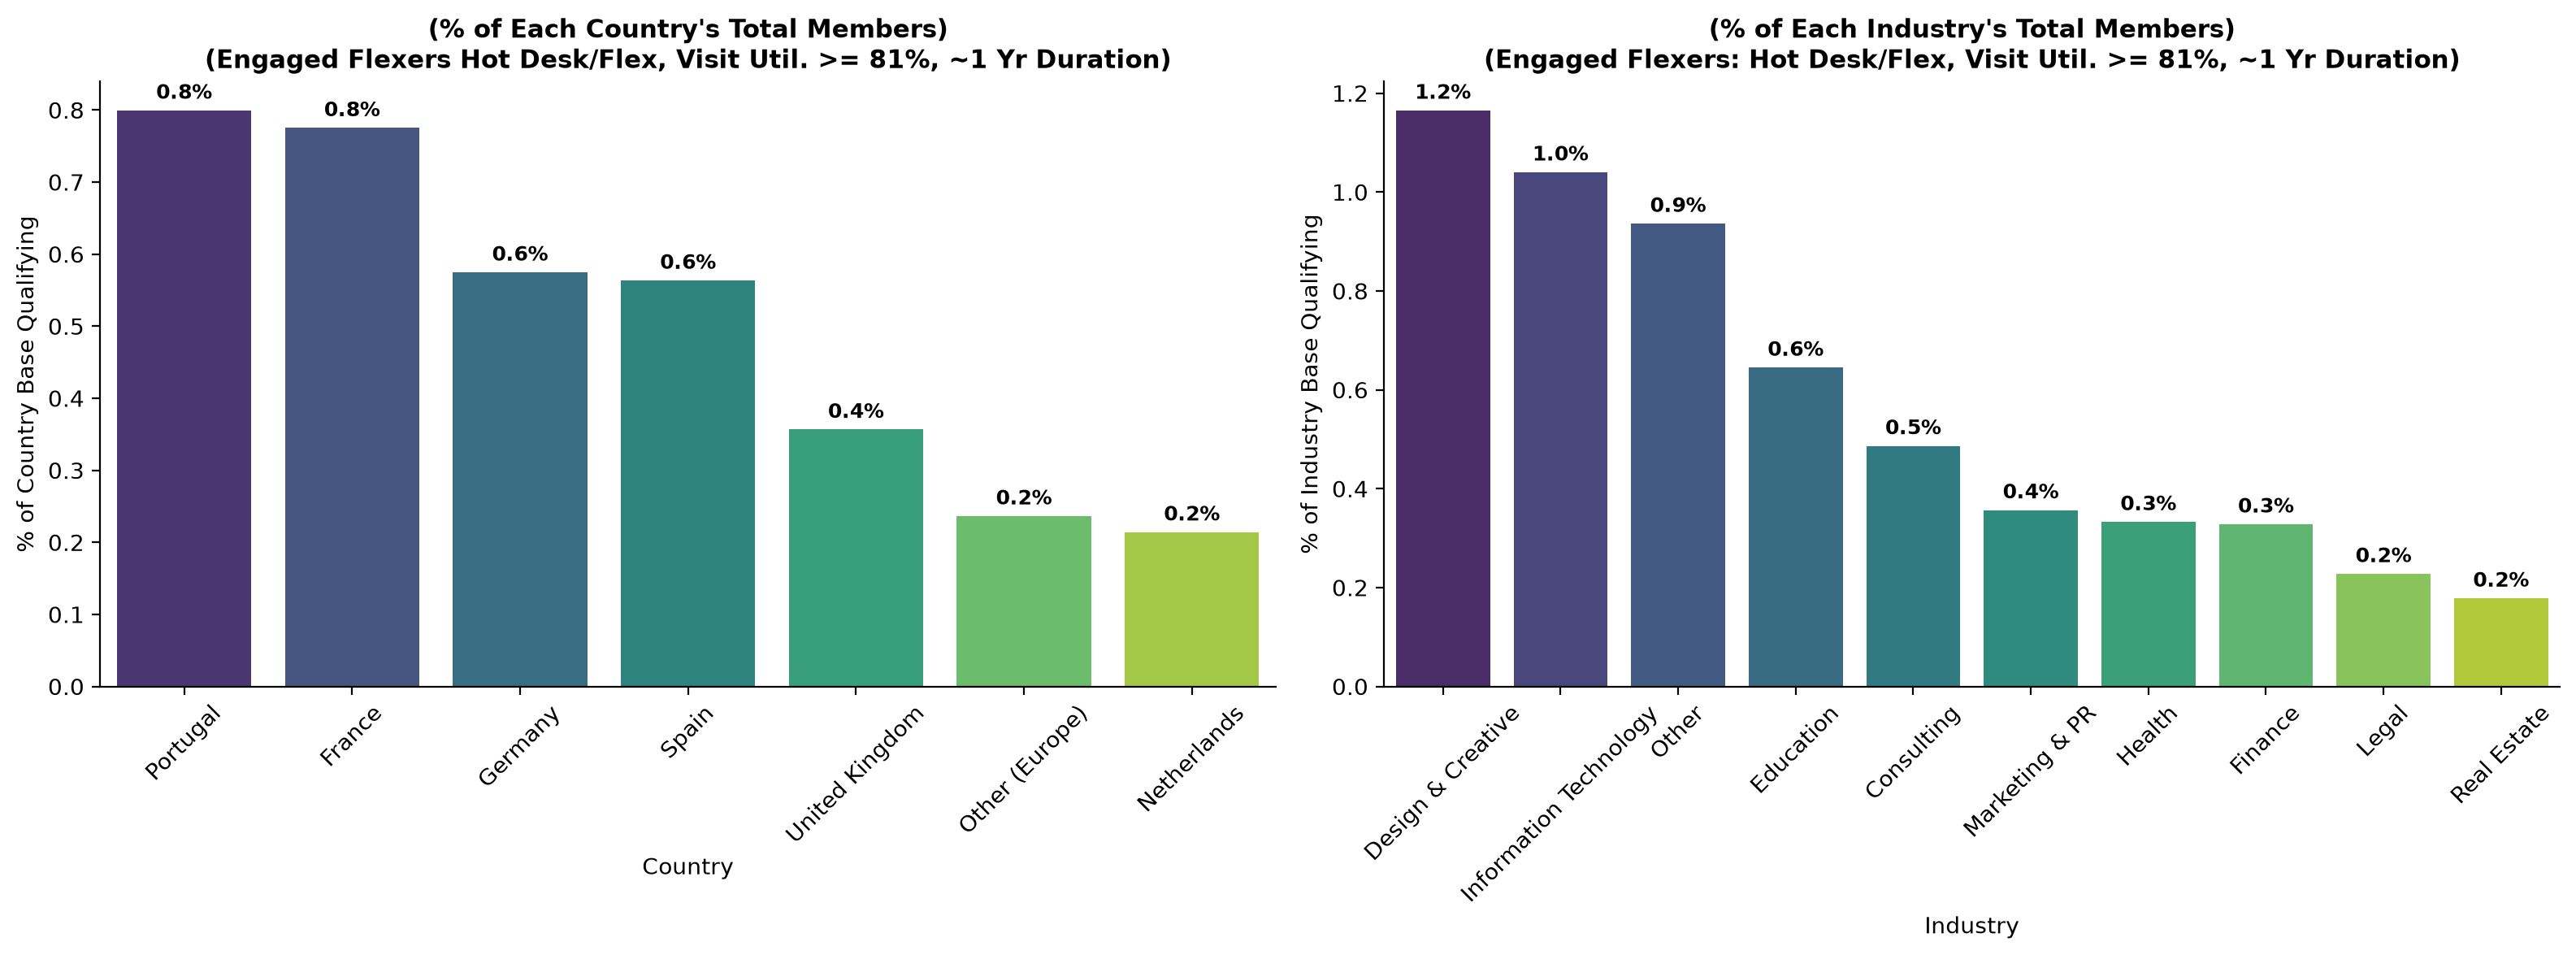

In [45]:
acdc_cohort4_rate = acdc_cleaned.copy()

if "visit_utilization" not in acdc_cohort4_rate.columns:
    acdc_cohort4_rate["visit_utilization"] = (
        acdc_cohort4_rate["actual_visits_last_period"] / 
        acdc_cohort4_rate["entitled_visits_last_period"].replace(0, np.nan)
    )

start_dt = pd.to_datetime(acdc_cohort4_rate["membership_start"], errors='coerce', dayfirst=True)
end_dt = pd.to_datetime(acdc_cohort4_rate["membership_end"], errors='coerce', dayfirst=True)
last_swipe_dt = pd.to_datetime(acdc_cohort4_rate["last_badge_swipe"], errors='coerce', dayfirst=False)
effective_end_dt = end_dt.where((end_dt.notna()) & (end_dt.dt.year > 1970), last_swipe_dt)
acdc_cohort4_rate["membership_duration_days"] = (effective_end_dt - start_dt).dt.days

# 2. Apply cohort conditions
cheap_tiers = ["Flex", "Hot Desk"]
cond_tier_p4 = acdc_cohort4_rate["clean_plan_tier"].isin(cheap_tiers)
cond_utilization_p4 = acdc_cohort4_rate["visit_utilization"] >= 0.81
cond_duration_p4 = (acdc_cohort4_rate["membership_duration_days"] >= 330) & (acdc_cohort4_rate["membership_duration_days"] <= 400)

cohort4_members = acdc_cohort4_rate[cond_tier_p4 & cond_utilization_p4 & cond_duration_p4]

country_total = acdc_cleaned["clean_country"].value_counts()
cohort_country_counts = cohort4_members["clean_country"].value_counts()
country_rate = (cohort_country_counts / country_total * 100).dropna().reset_index()
country_rate.columns = ["country", "percentage"]
country_rate = country_rate.sort_values(by="percentage", ascending=False)

industry_total = acdc_cleaned["clean_industry"].value_counts()
cohort_industry_counts = cohort4_members["clean_industry"].value_counts()
industry_rate = (cohort_industry_counts / industry_total * 100).dropna().reset_index()
industry_rate.columns = ["industry", "percentage"]
industry_rate = industry_rate.sort_values(by="percentage", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax1 = sns.barplot(
    data=country_rate, 
    x="country", 
    y="percentage", 
    palette="viridis",
    hue="country",
    legend=False,
    ax=axes[0]
)
axes[0].set_title("(% of Each Country's Total Members)\n(Engaged Flexers Hot Desk/Flex, Visit Util. >= 81%, ~1 Yr Duration)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Country", fontsize=10)
axes[0].set_ylabel("% of Country Base Qualifying", fontsize=10)
axes[0].tick_params(axis='x', rotation=45)

for p in ax1.patches:
    height = p.get_height()
    if height > 0:
        ax1.annotate(f'{height:.1f}%',
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', 
                     fontsize=9, fontweight='bold',
                     xytext=(0, 3), textcoords='offset points')

ax2 = sns.barplot(
    data=industry_rate, 
    x="industry", 
    y="percentage", 
    palette="viridis",
    hue="industry",
    legend=False,
    ax=axes[1]
)
axes[1].set_title("(% of Each Industry's Total Members)\n(Engaged Flexers: Hot Desk/Flex, Visit Util. >= 81%, ~1 Yr Duration)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Industry", fontsize=10)
axes[1].set_ylabel("% of Industry Base Qualifying", fontsize=10)
axes[1].tick_params(axis='x', rotation=45)

for p in ax2.patches:
    height = p.get_height()
    if height > 0:
        ax2.annotate(f'{height:.1f}%',
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', 
                     fontsize=9, fontweight='bold',
                     xytext=(0, 3), textcoords='offset points')

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

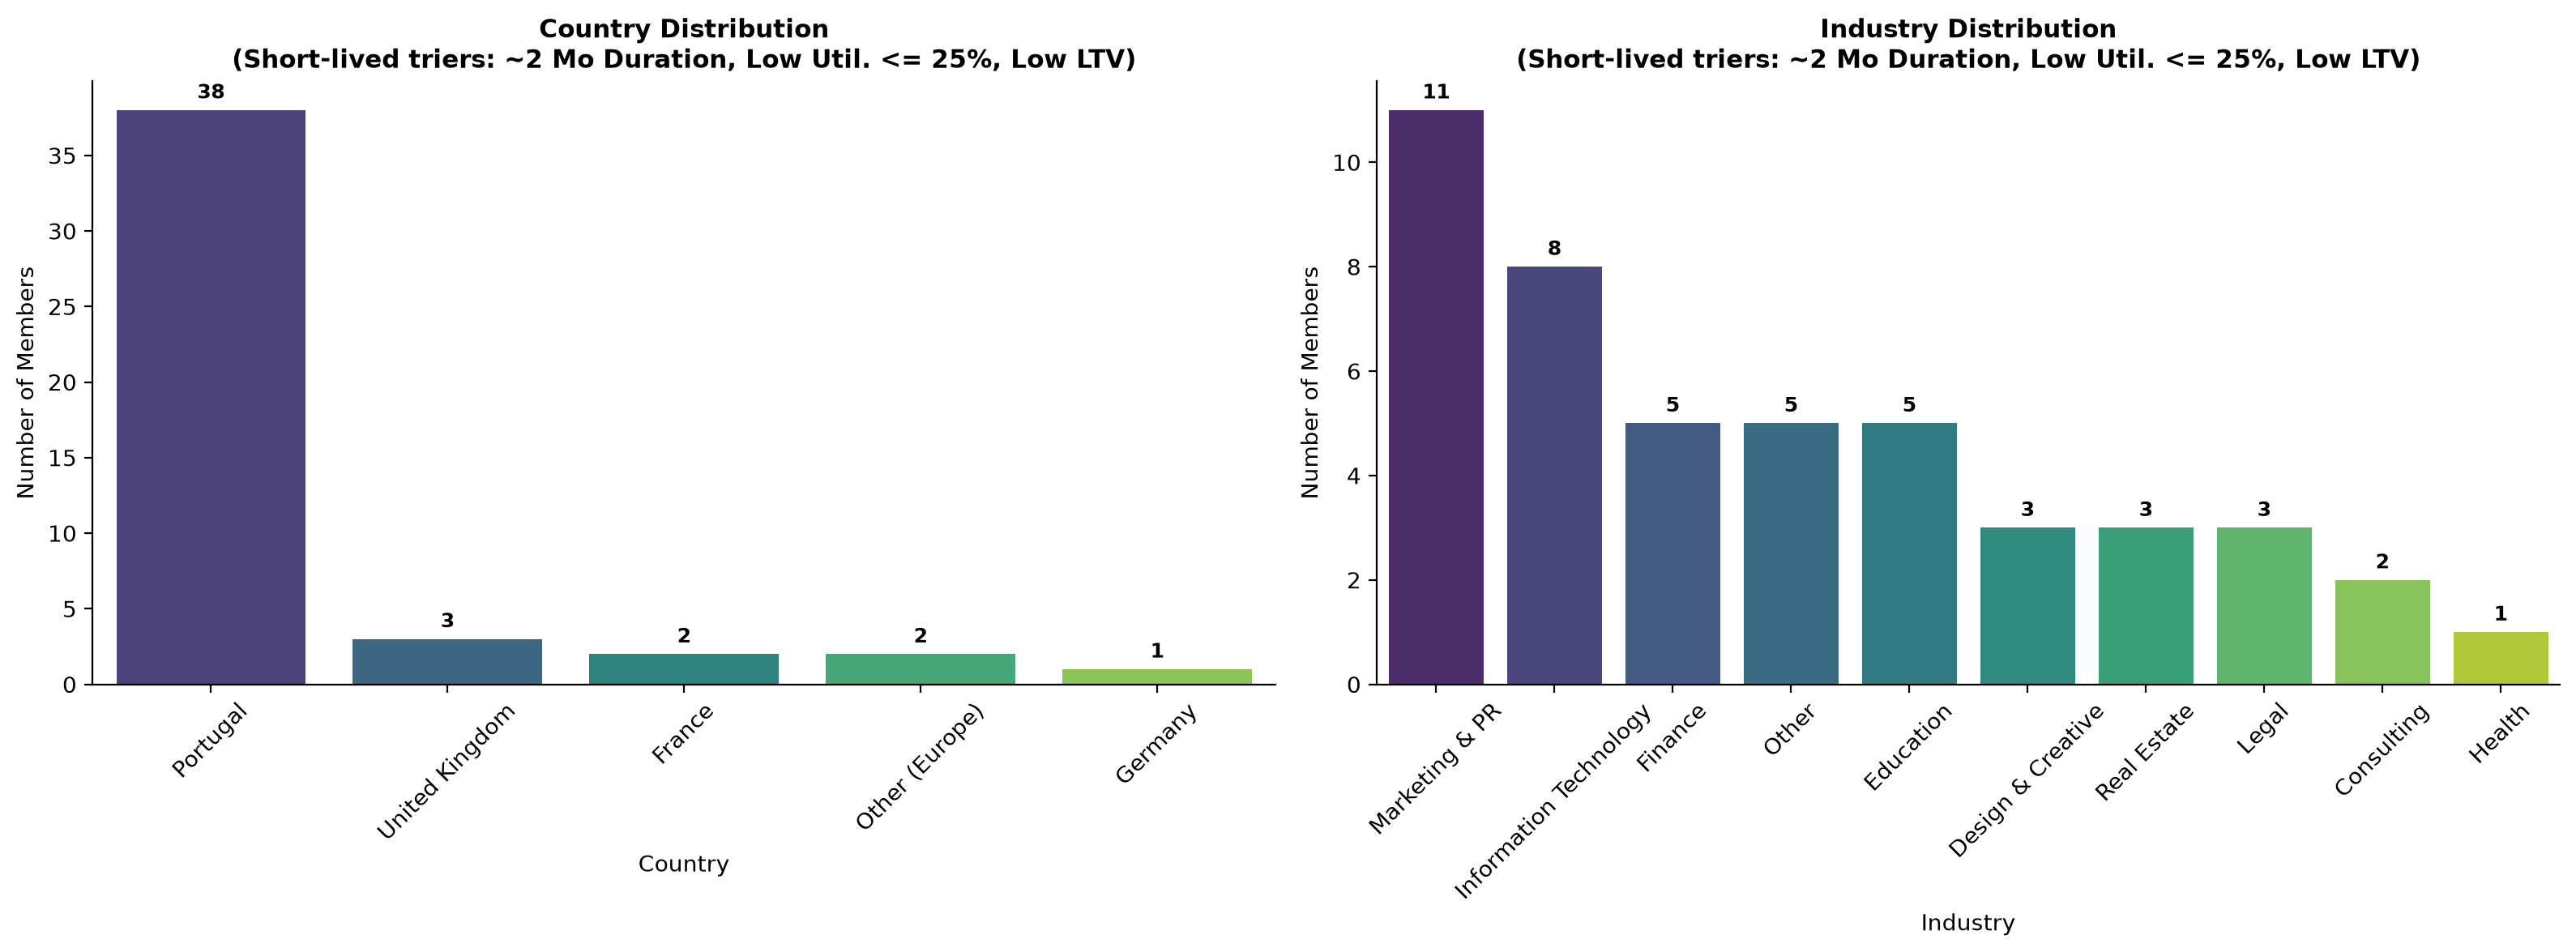

In [46]:
acdc_cohort5 = acdc_cleaned.copy()

if "visit_utilization" not in acdc_cohort5.columns:
    acdc_cohort5["visit_utilization"] = (
        acdc_cohort5["actual_visits_last_period"] / 
        acdc_cohort5["entitled_visits_last_period"].replace(0, np.nan)
    )

if acdc_cohort5["lifetime_value"].dtype == object:
    acdc_cohort5["lifetime_value"] = pd.to_numeric(
        acdc_cohort5["lifetime_value"].astype(str).str.replace("€", "").str.replace(",", "").str.strip(), 
        errors="coerce"
    )

start_dt = pd.to_datetime(acdc_cohort5["membership_start"], errors='coerce', dayfirst=True)
end_dt = pd.to_datetime(acdc_cohort5["membership_end"], errors='coerce', dayfirst=True)
last_swipe_dt = pd.to_datetime(acdc_cohort5["last_badge_swipe"], errors='coerce', dayfirst=False)
effective_end_dt = end_dt.where((end_dt.notna()) & (end_dt.dt.year > 1970), last_swipe_dt)
acdc_cohort5["membership_duration_days"] = (effective_end_dt - start_dt).dt.days

cond_duration_p5 = (acdc_cohort5["membership_duration_days"] >= 40) & (acdc_cohort5["membership_duration_days"] <= 85)

cond_utilization_p5 = acdc_cohort5["visit_utilization"] <= 0.25

ltv_median = acdc_cohort5["lifetime_value"].median()
cond_value_p5 = acdc_cohort5["lifetime_value"] <= ltv_median

cohort5_members = acdc_cohort5[cond_duration_p5 & cond_utilization_p5 & cond_value_p5]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

country_counts_p5 = cohort5_members["clean_country"].value_counts().reset_index()
country_counts_p5.columns = ["country", "count"]

ax1 = sns.barplot(
    data=country_counts_p5, 
    x="country", 
    y="count", 
    palette="viridis",
    hue="country",
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Country Distribution\n(Short-lived triers: ~2 Mo Duration, Low Util. <= 25%, Low LTV)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Country", fontsize=10)
axes[0].set_ylabel("Number of Members", fontsize=10)
axes[0].tick_params(axis='x', rotation=45)

for p in ax1.patches:
    height = p.get_height()
    if height > 0:
        ax1.annotate(f'{int(height)}',
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', 
                     fontsize=9, fontweight='bold',
                     xytext=(0, 3), textcoords='offset points')

industry_counts_p5 = cohort5_members["clean_industry"].value_counts().reset_index()
industry_counts_p5.columns = ["industry", "count"]

ax2 = sns.barplot(
    data=industry_counts_p5, 
    x="industry", 
    y="count", 
    palette="viridis",
    hue="industry",
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Industry Distribution\n(Short-lived triers: ~2 Mo Duration, Low Util. <= 25%, Low LTV)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Industry", fontsize=10)
axes[1].set_ylabel("Number of Members", fontsize=10)
axes[1].tick_params(axis='x', rotation=45)

for p in ax2.patches:
    height = p.get_height()
    if height > 0:
        ax2.annotate(f'{int(height)}',
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', 
                     fontsize=9, fontweight='bold',
                     xytext=(0, 3), textcoords='offset points')

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

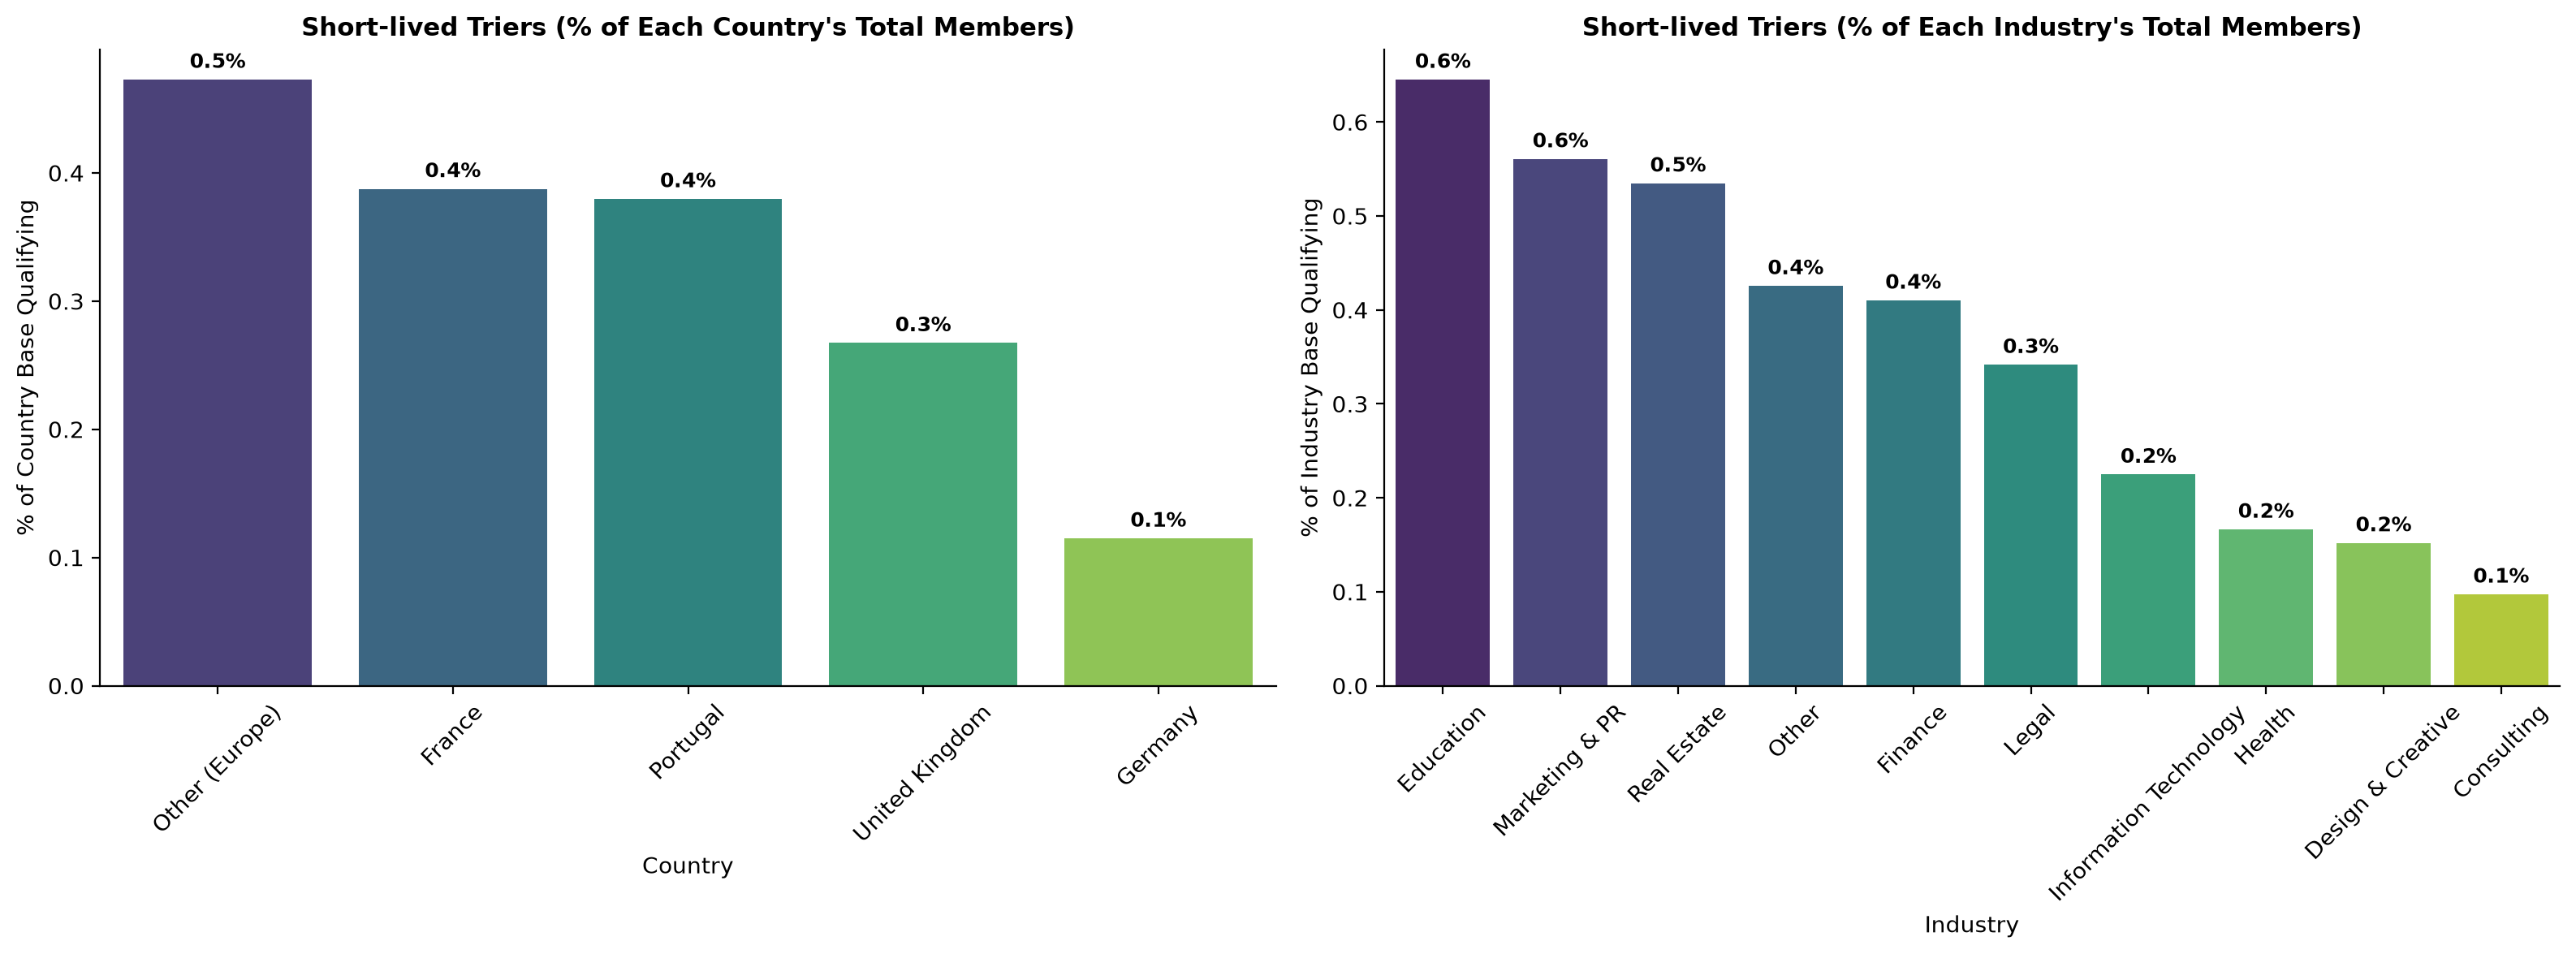

In [47]:
acdc_cohort5_rate = acdc_cleaned.copy()

if "visit_utilization" not in acdc_cohort5_rate.columns:
    acdc_cohort5_rate["visit_utilization"] = (
        acdc_cohort5_rate["actual_visits_last_period"] / 
        acdc_cohort5_rate["entitled_visits_last_period"].replace(0, np.nan)
    )

if acdc_cohort5_rate["lifetime_value"].dtype == object:
    acdc_cohort5_rate["lifetime_value"] = pd.to_numeric(
        acdc_cohort5_rate["lifetime_value"].astype(str).str.replace("€", "").str.replace(",", "").str.strip(), 
        errors="coerce"
    )

start_dt = pd.to_datetime(acdc_cohort5_rate["membership_start"], errors='coerce', dayfirst=True)
end_dt = pd.to_datetime(acdc_cohort5_rate["membership_end"], errors='coerce', dayfirst=True)
last_swipe_dt = pd.to_datetime(acdc_cohort5_rate["last_badge_swipe"], errors='coerce', dayfirst=False)
effective_end_dt = end_dt.where((end_dt.notna()) & (end_dt.dt.year > 1970), last_swipe_dt)
acdc_cohort5_rate["membership_duration_days"] = (effective_end_dt - start_dt).dt.days

cond_duration_p5 = (acdc_cohort5_rate["membership_duration_days"] >= 40) & (acdc_cohort5_rate["membership_duration_days"] <= 85)
cond_utilization_p5 = acdc_cohort5_rate["visit_utilization"] <= 0.25
ltv_median = acdc_cohort5_rate["lifetime_value"].median()
cond_value_p5 = acdc_cohort5_rate["lifetime_value"] <= ltv_median

cohort5_members = acdc_cohort5_rate[cond_duration_p5 & cond_utilization_p5 & cond_value_p5]

country_total = acdc_cleaned["clean_country"].value_counts()
cohort_country_counts = cohort5_members["clean_country"].value_counts()

country_rate = (cohort_country_counts / country_total * 100).dropna().reset_index()
country_rate.columns = ["country", "percentage"]
country_rate = country_rate.sort_values(by="percentage", ascending=False)

industry_total = acdc_cleaned["clean_industry"].value_counts()
cohort_industry_counts = cohort5_members["clean_industry"].value_counts()

industry_rate = (cohort_industry_counts / industry_total * 100).dropna().reset_index()
industry_rate.columns = ["industry", "percentage"]
industry_rate = industry_rate.sort_values(by="percentage", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax1 = sns.barplot(
    data=country_rate, 
    x="country", 
    y="percentage", 
    palette="viridis",
    hue="country",
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Short-lived Triers (% of Each Country's Total Members)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Country", fontsize=10)
axes[0].set_ylabel("% of Country Base Qualifying", fontsize=10)
axes[0].tick_params(axis='x', rotation=45)

for p in ax1.patches:
    height = p.get_height()
    if height > 0:
        ax1.annotate(f'{height:.1f}%',
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', 
                     fontsize=9, fontweight='bold',
                     xytext=(0, 3), textcoords='offset points')

# --- Plot 2: Industry Rate Distribution ---
ax2 = sns.barplot(
    data=industry_rate, 
    x="industry", 
    y="percentage", 
    palette="viridis",
    hue="industry",
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Short-lived Triers (% of Each Industry's Total Members)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Industry", fontsize=10)
axes[1].set_ylabel("% of Industry Base Qualifying", fontsize=10)
axes[1].tick_params(axis='x', rotation=45)

for p in ax2.patches:
    height = p.get_height()
    if height > 0:
        ax2.annotate(f'{height:.1f}%',
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', 
                     fontsize=9, fontweight='bold',
                     xytext=(0, 3), textcoords='offset points')

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

### Conclusion of Geographical and Industrial Segmentation Exploration. 

From our geographical and industrial segmentation exploration, there is no statistical evidence to suggest that geography or industry have a significant impact on customer behavior and there is no evidence of a connection between idustry, geography, and the identified segments. Therefore, industry and geography may have less significance in our formal segmentation. 

In [48]:
DATA_PATH = "data/acdc_dataset.csv"
PLANS = ["hot_desk", "flex", "dedicated_desk", "full_time", "private_office"]

## Data Cleaning

Problems found during exploration and how `load_clean()` handles them:

| Problem | Example | Treatment |
|---|---|---|
| Exact duplicate rows | 15 rows | dropped |
| Inconsistent labels | `F`, `female`, ` Female` · `PT`, `Portucal` · `hotdesk`, `Hot Desk` | normalised to one label per category |
| `lifetime_value` stored as text | `"390.00 €"`, `"4,311.15"` | parsed to number |
| Mixed date formats | `2021-08-01` vs `01/08/2021` | both formats parsed |
| Sentinel values (hidden missing) | `days_since_last_visit = 999`, `n_colleagues = -1`, industry `Unknown` | converted to `NaN` |
| Impossible values | age 1 or 149, negative visits/hours/renewals, 9 days per week | converted to `NaN` |
| Placeholder end date | `membership_end = 1970-01-01` | flag `has_end_date = False` (active member) |

A member has *left* (`churned = 1`) when `membership_end` holds a real date. The data snapshot is **2024-01-01**.

`usage_ratio` (visits used ÷ visits entitled in the last period) and `tenure_days` (days from joining to leaving, or to the snapshot for active members) are also created here because later steps need them.

In [49]:
COUNTRY = {"portugal": "Portugal", "portucal": "Portugal", "pt": "Portugal",
           "united kingdom": "United Kingdom", "uk": "United Kingdom", "gb": "United Kingdom", "u.k.": "United Kingdom",
           "germany": "Germany", "de": "Germany", "deutschland": "Germany",
           "spain": "Spain", "es": "Spain", "espana": "Spain", "españa": "Spain",
           "france": "France", "fr": "France", "ireland": "Ireland", "ie": "Ireland",
           "netherlands": "Netherlands", "the netherlands": "Netherlands", "nl": "Netherlands", "holland": "Netherlands",
           "other (europe)": "Other (Europe)"}
PLAN = {"flex": "flex", "hotdesk": "hot_desk", "fulltime": "full_time", "dedicateddesk": "dedicated_desk", "privateoffice": "private_office"}
INDUSTRY = {"it": "information technology", "tech": "information technology", "design/creative": "design & creative",
            "design and creative": "design & creative", "marketing/pr": "marketing & pr", "marketing and pr": "marketing & pr",
            "realestate": "real estate", "real-estate": "real estate"}
SNAPSHOT = pd.Timestamp("2024-01-01")
NON_NEG = ["total_visits", "meeting_room_hours", "event_space_hours", "guest_passes_issued", "n_renewals", "lifetime_value"]


def load_clean(path=DATA_PATH):
    df = pd.read_csv(path, sep=";").drop_duplicates().reset_index(drop=True)
    df["lifetime_value"] = pd.to_numeric(df["lifetime_value"].astype(str).str.replace("€", "").str.replace(",", "").str.strip(), errors="coerce")
    df["gender"] = df["gender"].str.strip().str.lower().str[0].map({"f": "Female", "m": "Male", "o": "Other"})
    df["country"] = df["country"].str.strip().str.lower().map(COUNTRY)
    df["plan_tier"] = df["plan_tier"].str.lower().str.replace(r"[ _]", "", regex=True).map(PLAN)
    ind = df["industry"].str.strip().str.lower()
    df["industry"] = ind.replace(INDUSTRY).replace("unknown", np.nan).str.title().str.replace("& Pr", "& PR")
    for c in ["membership_start", "membership_end", "last_badge_swipe"]:
        iso = pd.to_datetime(df[c], format="%Y-%m-%d", errors="coerce")
        df[c] = iso.fillna(pd.to_datetime(df[c], format="%d/%m/%Y", errors="coerce"))
    df["has_end_date"] = df["membership_end"].dt.year > 1970
    df.loc[~df["has_end_date"], "membership_end"] = pd.NaT
    df.loc[df["days_since_last_visit"] == 999, "days_since_last_visit"] = np.nan
    df.loc[df["days_since_last_visit"] < 0, "days_since_last_visit"] = np.nan
    df.loc[df["n_colleagues_on_account"] == -1, "n_colleagues_on_account"] = np.nan
    df.loc[~df["age"].between(18, 90), "age"] = np.nan
    df.loc[~df["plan_days_per_week"].isin([2, 3, 5, 7]), "plan_days_per_week"] = np.nan
    for c in NON_NEG:
        df.loc[df[c] < 0, c] = np.nan
    df["usage_ratio"] = (df["actual_visits_last_period"] / df["entitled_visits_last_period"].replace(0, np.nan)).clip(upper=1.5)
    end = df["membership_end"].fillna(SNAPSHOT)
    df["tenure_days"] = (end - df["membership_start"]).dt.days
    df.loc[df["tenure_days"] < 0, "tenure_days"] = np.nan
    df.loc[df["total_visits"] > df["tenure_days"].clip(lower=30) / 30.44 * 31, "total_visits"] = np.nan
    return df

In [50]:
df = load_clean()
print(df.shape)
print("Members who left:", df.has_end_date.sum(), f"({df.has_end_date.mean():.0%})")
df[["gender", "country", "plan_tier", "industry"]].nunique()

(15450, 34)
Members who left: 11496 (74%)


gender        3
country       8
plan_tier     5
industry     10
dtype: int64

### Data quality after cleaning
Share of missing values per column. `membership_end` is excluded because a missing end date simply means the member is still active.

In [51]:
df.drop(columns="membership_end").isna().mean().loc[lambda s: s > 0].sort_values(ascending=False).round(3)

days_since_last_visit      0.088
meeting_room_hours         0.085
guest_passes_issued        0.083
lifetime_value             0.073
age                        0.046
industry                   0.045
n_colleagues_on_account    0.037
gender                     0.034
country                    0.028
tenure_days                0.010
plan_tier                  0.007
plan_days_per_week         0.006
n_renewals                 0.004
total_visits               0.003
usage_ratio                0.001
event_space_hours          0.001
dtype: float64

### Risks for clustering
| Risk | Size | Mitigation |
|---|---|---|
| LTV unusable for many members | 19% of members after correction (see below) | Do not fill zeros with 0; impute or exclude when LTV enters a model. Revenue shares below use known LTV only. |
| Missing meeting hours and guest passes | ~8% each | Decide on imputation before clustering, using plan and add-on flags. |
| Impossible extreme meeting hours | 2 members above 744 h/month (all hours in a month) | Treat as errors or cap them: K-means is sensitive to extremes. |
| Active members have not finished their membership | 26% of members | Tenure and LTV are understated for them; compare groups with this in mind. |
| Different scales and skewed variables | Hours and LTV have long right tails | Log-transform and standardise before distance-based clustering. |

## Additional Feature Engineering
`build_features()` works on the cleaned data and keeps one row per member. `usage_ratio` is the cleaned version of `visit_utilization`, and `n_services` of `n_services_used`.

| Perspective | Feature | What it captures | Contribution to clustering |
|---|---|---|---|
| Value | `monthly_price` | Median monthly revenue of the member's plan | Economic level of the plan |
| Value | `ltv_clean` | LTV after correcting errors | Total economic contribution |
| Value | `ltv_vs_expected` | LTV ÷ (plan price × months) | Separates members who pay for extras from those who pay only the plan, independently of tenure |
| Behaviour | `usage_ratio` | Visits used ÷ visits entitled | Makes attendance comparable across plans with different entitlements |
| Behaviour | `meeting_hours_per_month`, `guest_passes_per_month` | Amenity use per month | Stops long-tenure members from looking heavier just because they stayed longer |
| Behaviour | `n_services` | Number of add-ons used | Breadth of use of the space |
| Relationship | `anchored` | Uses mail handling or storage | The space is their address or locker, a different reason to stay than attendance |
| Relationship | `tenure_months`, `renewals_per_year` | Length of stay and commitment | Loyalty, comparable across join dates |

### Fixing lifetime value
LTV follows *plan monthly price × months as member* closely, which makes errors easy to spot:
- **85 values were stored in cents** (about 100× the expected value), so they are divided by 100.
- **1,742 zeros** belong to normal members with visits and renewals, so they are treated as missing, not as "paid nothing".
- Values still above 5× the plan price per month are set to missing.

`monthly_price` is estimated from the data as the median of LTV ÷ months per plan.

In [52]:
PLAN_RANK = {plan: rank for rank, plan in enumerate(PLANS, start=1)}
DAYS_TO_PLAN = {2: "hot_desk", 3: "flex", 7: "private_office"}
SERVICES = ["uses_meeting_rooms", "uses_event_space", "uses_guest_passes", "uses_print", "uses_mail_handling",
            "uses_phone_booths", "uses_day_passes", "uses_storage", "uses_bike_locker"]


def fix_lifetime_value(df):
    months = df["tenure_days"] / 30.44
    ltv = df["lifetime_value"].copy()
    ltv[ltv == 0] = np.nan
    price = (ltv / months).groupby(df["plan_tier"]).median()
    ratio = ltv / (df["plan_tier"].map(price) * months)
    cents = (ratio > 20) | (ratio.isna() & (ltv > 30000))
    ltv[cents] = ltv[cents] / 100
    per_month = ltv / months.clip(lower=1)
    ltv[per_month > 5 * df["plan_tier"].map(price).fillna(price.max())] = np.nan
    return ltv, price, cents.sum()


def build_features(df):
    f = df[["member_id"]].copy()
    f["churned"] = df["has_end_date"].astype(int)

    plan = df["plan_tier"].fillna(df["plan_days_per_week"].map(DAYS_TO_PLAN))
    ltv, price, _ = fix_lifetime_value(df)
    f["plan_tier"] = plan
    f["plan_rank"] = plan.map(PLAN_RANK)
    f["monthly_price"] = plan.map(price)

    f["tenure_months"] = df["tenure_days"] / 30.44
    months = f["tenure_months"].clip(lower=1)

    f["ltv_clean"] = ltv
    f["expected_ltv"] = f["monthly_price"] * f["tenure_months"]
    f["ltv_vs_expected"] = (ltv / f["expected_ltv"]).clip(upper=5)

    f["usage_ratio"] = df["usage_ratio"]
    f["avg_weekly_visits"] = df["avg_weekly_visits"].clip(upper=7)
    f["meeting_hours_per_month"] = df["meeting_room_hours"] / months
    f["guest_passes_per_month"] = df["guest_passes_issued"] / months

    services = df[SERVICES].astype(int)
    f["n_services"] = services.sum(axis=1)
    f["anchored"] = services[["uses_mail_handling", "uses_storage"]].max(axis=1)
    f["renewals_per_year"] = df["n_renewals"] / (f["tenure_months"] / 12).clip(lower=1)
    return f

In [53]:
f = build_features(df)
print(f.shape)
print("LTV values fixed from cents:", fix_lifetime_value(df)[2])
print("LTV missing after correction:", f"{f.ltv_clean.isna().mean():.0%}")
print("Members above 744 meeting hours/month:", (f.meeting_hours_per_month > 744).sum())
f.head()

(15450, 16)
LTV values fixed from cents: 85
LTV missing after correction: 19%
Members above 744 meeting hours/month: 2


,member_id,churned,plan_tier,plan_rank,monthly_price,tenure_months,ltv_clean,expected_ltv,ltv_vs_expected,usage_ratio,avg_weekly_visits,meeting_hours_per_month,guest_passes_per_month,n_services,anchored,renewals_per_year
0,CW000001,1,flex,2.0,204.742752,19.119580,4477.97,3914.595320,1.143916,0.843235,2.65,0.0,0.941443,3,0,1.255258
1,CW000002,0,hot_desk,1.0,131.621665,1.248357,165.86,164.310882,1.009428,0.093633,0.32,0.0,0.000000,1,1,0.000000
2,CW000003,0,flex,2.0,204.742752,24.934297,4486.17,5105.116577,0.878760,0.076658,0.17,0.0,0.000000,0,0,0.481265
3,CW000004,1,flex,2.0,204.742752,1.445466,258.63,295.948787,0.873901,0.480256,1.23,0.0,0.000000,0,0,0.000000
4,CW000005,0,hot_desk,1.0,131.621665,2.266754,335.74,298.353971,1.125308,0.172513,0.38,0.0,0.000000,1,0,0.000000


### Do the features separate members who stayed from those who left?
Median of each feature for active members and for those who left, plus its Spearman correlation with `churned` (positive = higher among those who left). Churn is used here only to check that the features carry signal.

In [54]:
check = ["plan_rank", "usage_ratio", "avg_weekly_visits", "anchored", "renewals_per_year", "ltv_vs_expected", "n_services"]
signal = f.groupby("churned")[check].median().T.rename(columns={0: "median_active", 1: "median_left"})
signal["spearman_vs_churn"] = f[check].corrwith(f["churned"], method="spearman")
print("Share who left, by anchored:", f.groupby("anchored").churned.mean().round(3).to_dict())
signal.round(3).sort_values("spearman_vs_churn", key=abs, ascending=False)

Share who left, by anchored: {0: 0.818, 1: 0.579}


churned,median_active,median_left,spearman_vs_churn
plan_rank,3.000,2.000,-0.271
usage_ratio,0.232,0.575,0.266
anchored,1.000,0.000,-0.252
renewals_per_year,0.801,0.000,-0.222
avg_weekly_visits,0.825,1.665,0.212
ltv_vs_expected,0.971,1.011,0.130
n_services,2.000,1.000,-0.022


**Reading the table:** higher plan tiers, being *anchored* and renewing often go with staying. Unexpectedly, members who left **used the space more** (median usage 58% vs. 23%), so attendance alone does not explain retention. The "Attendance and anchoring" section looks into this. `n_services` shows almost no link with leaving.

## Lifetime Value

### How LTV is built
Each dot is a member. The x-axis is the LTV expected from *plan price × months*; the y-axis is the recorded LTV. Points above the dashed line paid for extras.

Members within ±25% of plan price × tenure: 86%


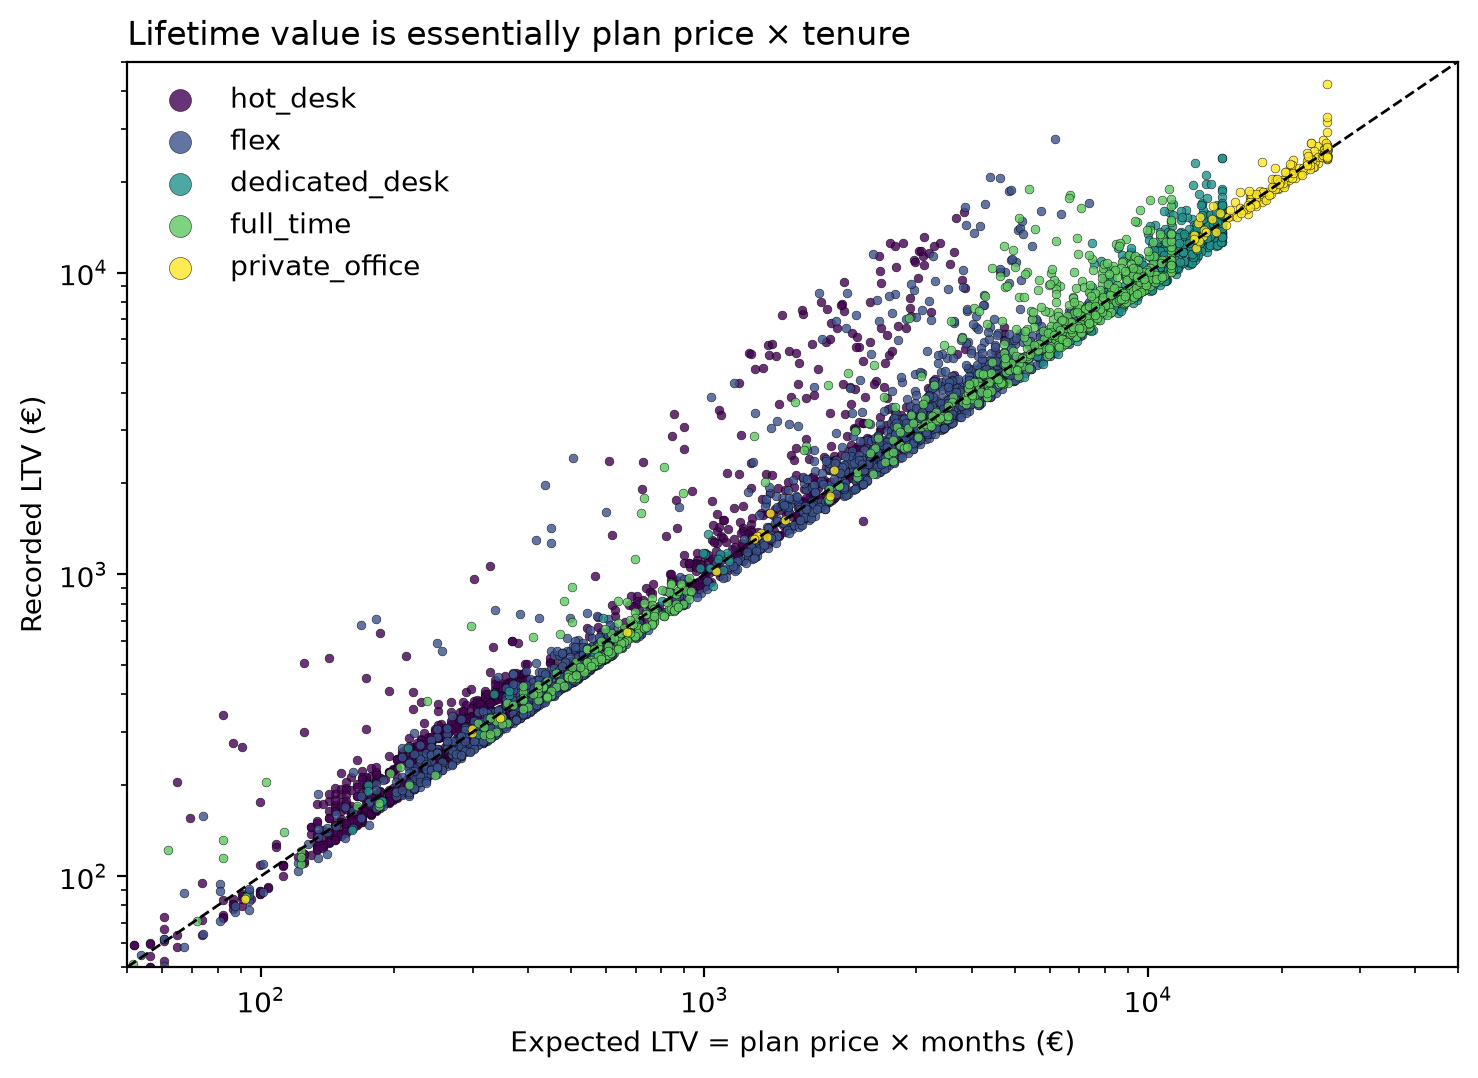

In [88]:
known = f[f.ltv_clean.notna() & (f.expected_ltv > 0)]
near_plan = (known.ltv_clean / known.expected_ltv).between(0.75, 1.25).mean()
print(f"Members within ±25% of plan price × tenure: {near_plan:.0%}")

plan_colors = {
    "hot_desk":       "#440154",   # dark purple
    "flex":           "#3B528B",   # blue
    "dedicated_desk": "#21918C",   # teal
    "full_time":      "#5EC962",   # green
    "private_office": "#FDE725",   # yellow
}

fig, ax = plt.subplots(figsize=(7.5, 5.5))
for plan in PLANS:
    d = known[known.plan_tier == plan].sample(frac=0.35, random_state=0)
    ax.scatter(d.expected_ltv, d.ltv_clean, s=10, alpha=0.8,
               label=plan, color=plan_colors[plan],
               edgecolors="black", linewidths=0.2)
ax.plot([50, 50000], [50, 50000], color="black", lw=1, ls="--")
ax.set(xscale="log", yscale="log", xlim=(50, 50000), ylim=(50, 50000),
       xlabel="Expected LTV = plan price × months (€)", ylabel="Recorded LTV (€)")
ax.set_title("Lifetime value is essentially plan price × tenure", loc="left")
ax.legend(frameon=False, markerscale=2.5)
fig.tight_layout(); fig.savefig("eda_ltv_formula.png", dpi=130); plt.show()

**Takeaway:** 86% of members are within ±25% of plan price × tenure, so LTV is mainly a function of **which plan** and **how long**. Value and tenure will overlap heavily in clustering; `ltv_vs_expected` isolates the part that plan and tenure do not explain.

### How concentrated is value?

Top 10% of members hold 42% of LTV
Top 20% of members hold 65% of LTV


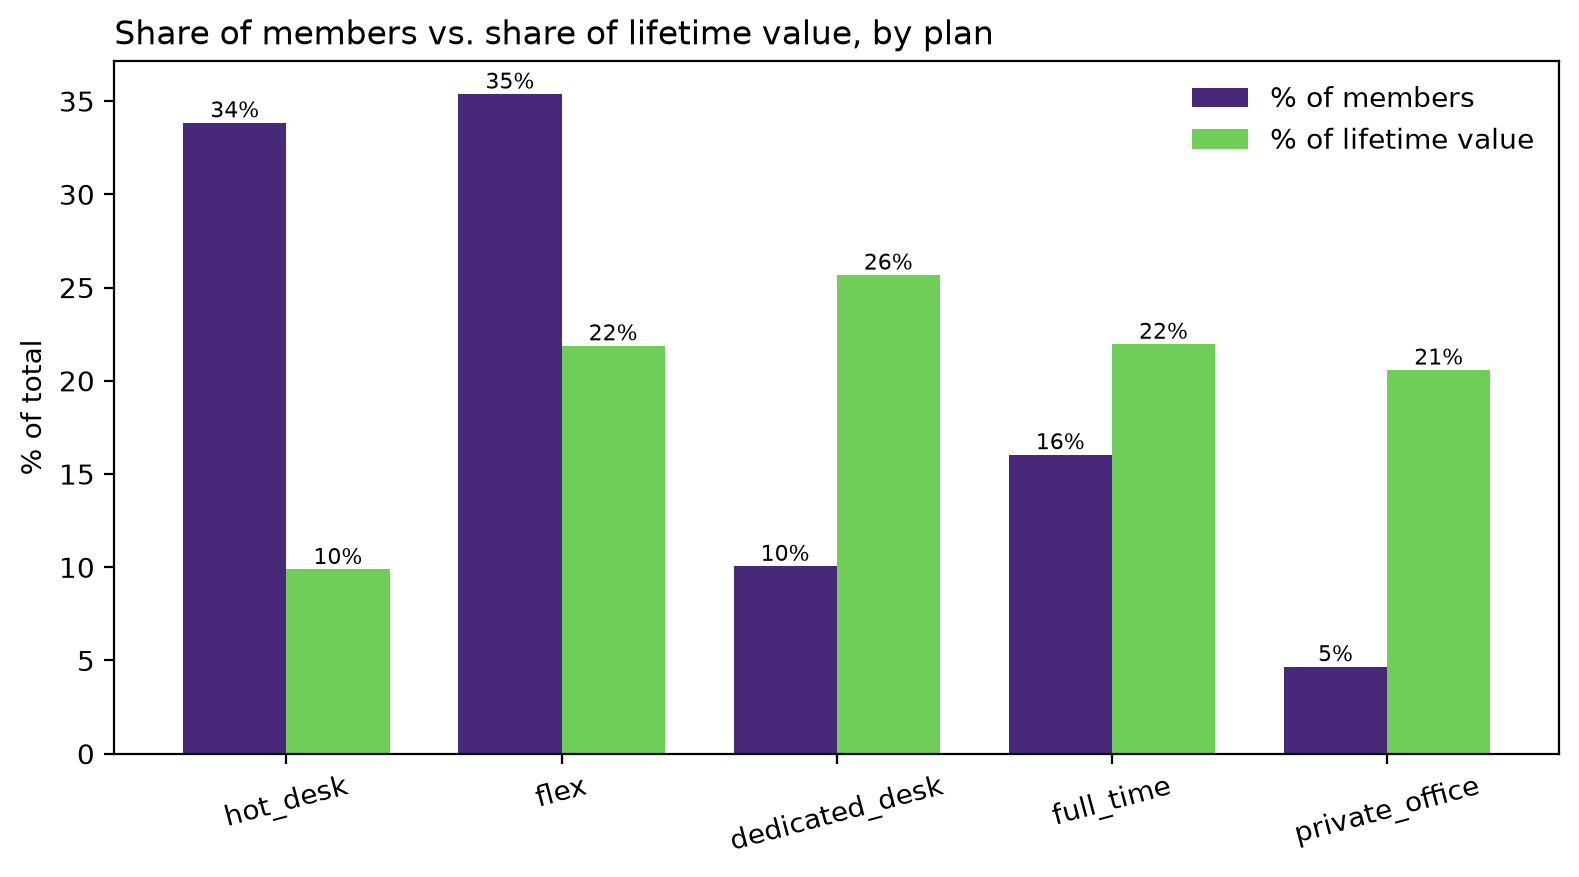

In [86]:
ltv = f.ltv_clean.dropna().sort_values(ascending=False)
for top in (0.1, 0.2):
    print(f"Top {top:.0%} of members hold {ltv.head(int(top * len(ltv))).sum() / ltv.sum():.0%} of LTV")

by_plan = f.groupby("plan_tier").agg(members=("member_id", "size"), ltv=("ltv_clean", "sum")).reindex(PLANS)
by_plan = by_plan / by_plan.sum() * 100

ax = by_plan.plot.bar(figsize=(8, 4.5), width=0.75, color=[PALETTE[0], PALETTE[6]], rot=15)
ax.set(xlabel="", ylabel="% of total")
ax.set_title("Share of members vs. share of lifetime value, by plan", loc="left")
ax.legend(["% of members", "% of lifetime value"], frameon=False)
ax.grid(axis="x", visible=False)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.0f%%", fontsize=8)
plt.tight_layout(); plt.savefig("eda_ltv_by_plan.png", dpi=130); plt.show()

**Takeaway:** the top 20% of members hold about 65% of lifetime value. Dedicated desks and private offices are 15% of members but 46% of value, while hot desks are a third of members and only 10%.

### Profile of each plan

In [57]:
f.groupby("plan_tier").agg(
    members=("member_id", "size"),
    monthly_price=("monthly_price", "first"),
    median_tenure_months=("tenure_months", "median"),
    median_ltv=("ltv_clean", "median"),
    median_usage=("usage_ratio", "median"),
    anchored=("anchored", "mean"),
    left=("churned", "mean"),
).reindex(PLANS).round(2)

,members,monthly_price,median_tenure_months,median_ltv,median_usage,anchored,left
plan_tier,,,,,,,
hot_desk,5212,131.62,2.63,349.76,0.46,0.11,0.87
flex,5449,204.74,8.56,1818.90,0.57,0.22,0.80
dedicated_desk,1549,407.79,26.61,11004.75,0.74,0.78,0.43
full_time,2471,312.73,17.15,5794.55,0.33,0.45,0.62
private_office,720,702.06,29.83,21363.34,0.15,0.88,0.54


In [58]:
long_plans = f[f.plan_tier.isin(["dedicated_desk", "private_office"])]
print("Left before 18 months:", ((long_plans.churned == 1) & (long_plans.tenure_months < 18)).sum(), "of", len(long_plans))

Left before 18 months: 4 of 2269


**Takeaway:**
- Length of stay rises with plan price: hot-desk members stay a median of under 3 months, private-office members about 30. Medians include active members, so true stays are longer.
- Only 4 of the 2,269 dedicated-desk and private-office members left before 18 months, which suggests a minimum contract worth confirming with ACDC.
- **Unexpected:** the guidelines place `dedicated_desk` below `full_time`, yet dedicated desks cost more (€408 vs. €313), stay longer and are worth about twice as much. The order of the two tiers should not be assumed to reflect value.
- Private-office members use only 15% of their entitlement, and 88% of them are anchored. This is the first sign that some members pay for presence, not for a desk.

### Attendance and anchoring

Members per cell:
anchored        0     1
usage_ratio            
under 20%    1665  1531
20-50%       3899   468
50-80%       2440  1367
over 80%     2677  1393


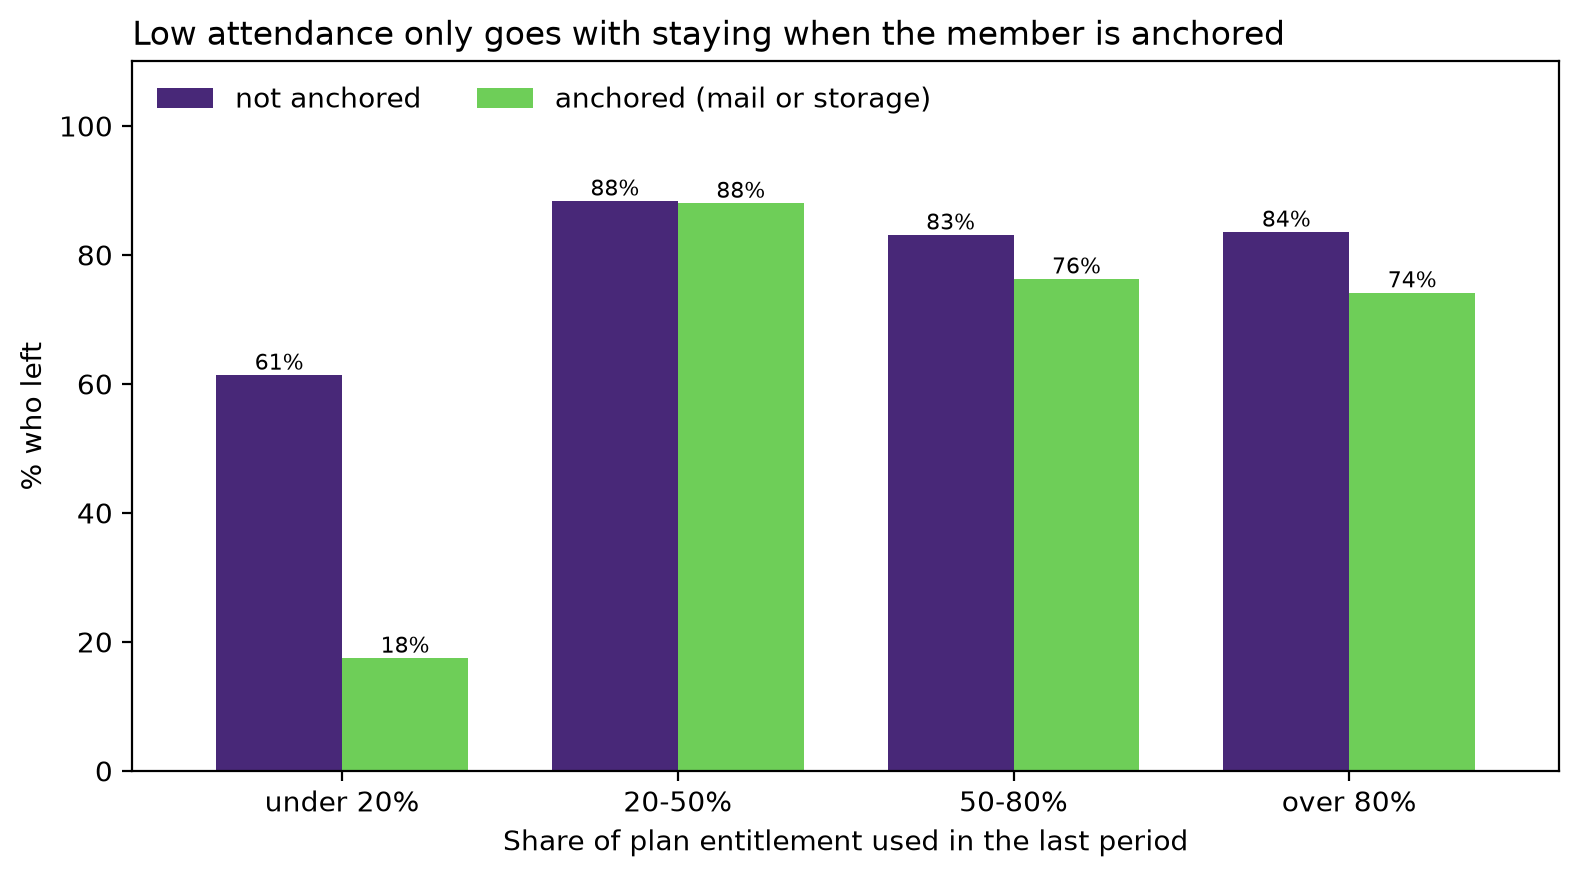

% who left, by plan level and anchoring:
anchored            0     1
plan_rank                  
higher plans     65.0  49.0
hot desk / flex  85.0  73.0


In [81]:
bands = pd.cut(f.usage_ratio, [-0.01, 0.2, 0.5, 0.8, 1.5], labels=["under 20%", "20-50%", "50-80%", "over 80%"])
left = f.groupby([bands, "anchored"], observed=True).churned.mean().unstack() * 100
print("Members per cell:")
print(f.groupby([bands, "anchored"], observed=True).size().unstack())

ax = left.plot.bar(figsize=(8, 4.5), width=0.75, color=[PALETTE[0], PALETTE[6]], rot=0)
ax.set(xlabel="Share of plan entitlement used in the last period", ylabel="% who left")
ax.set_title("Low attendance only goes with staying when the member is anchored", loc="left")
ax.set_ylim(0, 110)
ax.legend(["not anchored", "anchored (mail or storage)"], frameon=False, ncol=2, loc="upper left")
ax.grid(axis="x", visible=False)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.0f%%", fontsize=8)
plt.tight_layout(); plt.savefig("eda_usage_anchored.png", dpi=130); plt.show()

print("% who left, by plan level and anchoring:")
premium = f.plan_rank.ge(3).map({False: "hot desk / flex", True: "higher plans"})
print((f.groupby([premium, "anchored"]).churned.mean().unstack() * 100).round(0))

**Takeaway:** among members who rarely come in, only 18% of anchored members left, against 61% of those not anchored. Above 20% usage the gap shrinks to between 0 and 10 points. Anchored members are more often on higher plans, but the difference holds within each plan level (see the output below the chart).

In [60]:
for col in ["membership_start", "membership_end", "last_badge_swipe"]:
    iso = pd.to_datetime(acdc[col], format="%Y-%m-%d", errors="coerce")
    acdc[col] = iso.fillna(pd.to_datetime(acdc[col], format="%d/%m/%Y", errors="coerce"))

## Size and value of the candidate segments
The five segments above, applied to the cleaned data with the same rules. They are **hypotheses to test in Deliverable 2, not clusters**.

In [61]:
days = f.tenure_months * 30.44
median_ltv = f.ltv_clean.median()
premium = f.plan_rank >= 3
cheap = f.plan_rank <= 2

segments = {
    "Silent anchors": premium & (f.anchored == 1) & (f.usage_ratio <= 0.05),
    "Committed residents": premium & (f.avg_weekly_visits >= 4) & (f.n_services > 1) & (days >= 730),
    "Meeting-room power users": cheap & (df.meeting_room_hours > 0) & (df.guest_passes_issued > 0) & (f.ltv_clean >= 2.5 * median_ltv),
    "Engaged flexers": cheap & (f.usage_ratio >= 0.81) & days.between(330, 400),
    "Short-lived triers": days.between(40, 85) & (f.usage_ratio <= 0.25) & (f.ltv_clean <= median_ltv),
}

profile = pd.DataFrame({
    name: {
        "members": mask.sum(),
        "member_share": mask.mean(),
        "ltv_share": f.ltv_clean[mask].sum() / f.ltv_clean.sum(),
        "median_ltv": f.ltv_clean[mask].median(),
        "left": f.churned[mask].mean(),
    }
    for name, mask in segments.items()
}).T
print(f"Members in one of the segments: {sum(segments.values()).clip(upper=1).mean():.0%}")
profile.round(2)

Members in one of the segments: 20%


,members,member_share,ltv_share,median_ltv,left
Silent anchors,659.0,0.04,0.09,8574.06,0.04
Committed residents,797.0,0.05,0.19,13595.27,0.69
Meeting-room power users,335.0,0.02,0.05,6995.04,0.98
Engaged flexers,258.0,0.02,0.01,2105.69,0.98
Short-lived triers,1064.0,0.07,0.01,335.72,0.94


**Reading the table:** the segments differ strongly in value and retention. Silent anchors are 4% of members and 9% of value, and only 4% left. Committed residents are 5% of members and 19% of value. Together the five segments cover only 20% of members, so they describe the clearest cases, not the whole base. Clustering must show where the remaining members fall.

## Conclusions for clustering

**Most unexpected findings**
1. Members who left used the space more than those who stayed. Retention depends on the type of relationship, not on how often someone visits.
2. The most loyal group, the Silent anchors, barely comes in: they rely on the space as an address or locker.
3. Dedicated desks are worth more than full-time plans, despite ranking lower in the plan order.

**Expected number of clusters:** around **4 to 5**, to be tested with several algorithms and validation metrics in Deliverable 2.

**Most differentiating features:** plan tier, tenure, `usage_ratio`, `anchored` and `ltv_vs_expected`. Age, gender and country are not expected to separate groups as strongly.

**Anticipated challenges**
- Plan, tenure and LTV are strongly related, so using them together would give value too much weight. Value and behaviour should be clustered as separate perspectives.
- 19% of LTV values are missing after correction, and active members have not finished their membership.
- Extreme and skewed values need treatment before any distance-based method.
- `anchored` and `n_services` are binary or count variables, so they may need a different treatment from continuous ones.

**In plain language for ACDC:** a member's value is mostly set by their plan and how long they stay. A small group of premium and "address-only" members brings in most of the money, and those who use the space as a base rather than a desk are the ones who stay. Many others join a cheap plan, try it briefly and leave. A practical idea to test is offering mail or storage to flexible-plan members, although this analysis shows association, not cause.